In [1]:
# Build the local 3D scalar propagator before importing deepwave3D.
from pathlib import Path
import platform
import shutil
import subprocess
import sys

deepwave3d_dir = Path.cwd() / "deepwave3D"
if not deepwave3d_dir.is_dir():
    raise FileNotFoundError(f"Cannot find deepwave3D at {deepwave3d_dir}")

build_scripts = {
    "Linux": "build_linux.sh",
    "Darwin": "build_macos.sh",
    "Windows": "build_windows.sh",
}
system = platform.system()
if system not in build_scripts:
    raise RuntimeError(f"Unsupported operating system: {system}")

# A native library cannot be replaced safely after it has been loaded by
# the current Python process. Restart the kernel before rebuilding.
module_is_loaded = any(
    name == "deepwave3D" or name.startswith("deepwave3D.")
    for name in sys.modules
)
library_is_loaded = False
if system == "Linux" and Path("/proc/self/maps").is_file():
    process_maps = Path("/proc/self/maps").read_text()
    library_is_loaded = "libdeepwave_cpu_linux_x86_64.so" in process_maps
if module_is_loaded or library_is_loaded:
    raise RuntimeError(
        "deepwave3D is already loaded. Restart the Jupyter kernel, then run this cell once."
    )

build_command = ["bash", build_scripts[system]]
if system != "Darwin" and shutil.which("nvcc") is None:
    build_command.append("NOCUDA")

subprocess.run(build_command, cwd=deepwave3d_dir, check=True)

import deepwave3D
from deepwave3D import scalar, wavelets

print(f"deepwave3D built and imported on {system}")


Built libdeepwave_cpu_linux_x86_64.so
Built libdeepwave_cuda_linux_x86_64.so
deepwave3D built and imported on Linux


In [2]:
import time
import torch
import numpy as np
import random
import scipy.ndimage
import scipy.io
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import sys
from tqdm import trange
from siren import *
import torch.utils.checkpoint
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter

import warnings
warnings.filterwarnings("ignore", category=UserWarning)  
warnings.filterwarnings("ignore", category=FutureWarning)

/home/hls/anaconda3/envs/HLS_env/lib/python3.9/site-packages/numpy/_core/getlimits.py:552: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/hls/anaconda3/envs/HLS_env/lib/python3.9/site-packages/numpy/_core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  return self._float_to_str(self.smallest_subnormal)
/home/hls/anaconda3/envs/HLS_env/lib/python3.9/site-packages/numpy/_core/getlimits.py:552: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/home/hls/anaconda3/envs/HLS_env/lib/python3.9/site-packages/numpy/_core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)


In [3]:
dz = 30
dy = 30
dx = 30
nz = 112
ny = 300
nx = 300
freq = 8
dt = 0.004
nt = int(3.48 / dt)
peak_time = 2.5 / freq
device = torch.device('cuda:0')

In [4]:
d_source_y = 30
d_source_x = 30*1
first_source_y = 15
first_source_x = 15
source_depth = 2
n_shots_y = len(range(first_source_y, ny, d_source_y))
n_shots_x = len(range(first_source_x, nx, d_source_x))
n_shots = n_shots_y * n_shots_x

d_receiver_y = 2
d_receiver_x = 3
first_receiver_y = 1
first_receiver_x = 1
receiver_depth = 2
n_sources_per_shot = 1
n_receivers_per_shot_y = len(range(first_receiver_y, ny, d_receiver_y))
n_receivers_per_shot_x = len(range(first_receiver_x, nx, d_receiver_x))
n_receivers_per_shot = n_receivers_per_shot_y*n_receivers_per_shot_x

# source_locations
source_locations = torch.zeros(n_shots, n_sources_per_shot, 3,
                               dtype=torch.long, device=device)
source_locations[..., 0] = source_depth
source_locations[:, 0, 1] = (torch.arange(n_shots_y) * d_source_y +
                             first_source_y).repeat(n_shots_x)
source_locations[: ,0, 2] = (torch.arange(n_shots_x) * d_source_x +
                             first_source_x).repeat_interleave(n_shots_y)

# receiver_locations
receiver_locations = torch.zeros(n_shots, n_receivers_per_shot_y*n_receivers_per_shot_x, 3,
                                 dtype=torch.long, device=device)
receiver_locations[..., 0] = receiver_depth
receiver_locations[:, :, 1] = (
    (torch.arange(n_receivers_per_shot_y) * d_receiver_y +
     first_receiver_y).repeat(n_receivers_per_shot_x)
    .repeat(n_shots, 1)
)
receiver_locations[:, :, 2] = (
    (torch.arange(n_receivers_per_shot_x) * d_receiver_x +
     first_receiver_x).repeat_interleave(n_receivers_per_shot_y)
    .repeat(n_shots, 1)
)

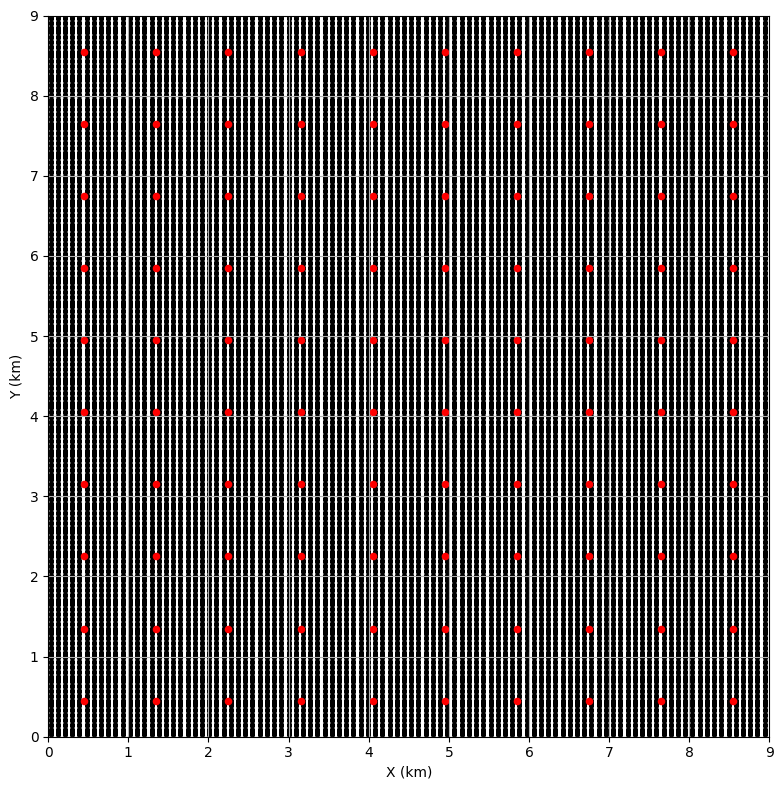

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

for shot in range(n_shots):
    rx = receiver_locations[shot, :, 2] * dx / 1e3  # x
    ry = receiver_locations[shot, :, 1] * dy / 1e3  # y
    plt.scatter(rx.cpu(), ry.cpu(), color='black', s=5, alpha=0.6)

for shot in range(n_shots):
    sx = source_locations[shot, :, 2] * dx / 1e3
    sy = source_locations[shot, :, 1] * dy / 1e3
    plt.scatter(sx.cpu(), sy.cpu(), color='red', s=20)

plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.xlim(0, nx * dx / 1e3)
plt.ylim(0, ny * dy / 1e3)
plt.grid(True)
plt.gca().set_aspect("equal", adjustable="box")  

plt.tight_layout()
plt.show()

In [7]:
import scipy as sp
def highpass_filter(order: int, freq: float, data, dt: float, filteringN: int = 1):
   
    sos = sp.signal.butter(order, Wn=freq, btype='highpass', output='sos', fs=1/dt)
    if filteringN == 1:
        return sp.signal.sosfilt(sos, data, axis=-1).copy()
    return sp.signal.sosfiltfilt(sos, data, axis=-1).copy()

In [8]:
ricker = wavelets.ricker(freq, nt, dt,peak_time).reshape(1, 1, -1)
ricker = torch.tensor(highpass_filter(8, 6, ricker, dt, filteringN=2)).float()
source_amplitudes_true = (
    ricker
    .repeat(n_shots, n_sources_per_shot, 1).to(device)
)

In [9]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12

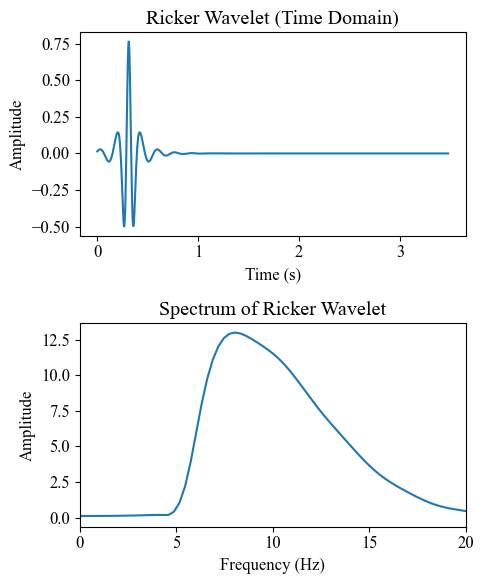

In [10]:
t_max = nt * dt 
t = np.arange(0, t_max, dt)  

wavelet = ricker[0,0,:].numpy()

n = len(wavelet)
f = np.fft.fftfreq(n, dt)  
f = np.fft.fftshift(f)  
wavelet_freq = np.abs(np.fft.fftshift(np.fft.fft(wavelet)))  

plt.figure(figsize=(5, 6))

plt.subplot(2, 1, 1)
plt.plot(t, wavelet)
plt.title('Ricker Wavelet (Time Domain)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

plt.subplot(2, 1, 2)
plt.plot(f, wavelet_freq)
plt.title('Spectrum of Ricker Wavelet')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim([0, 20])  

plt.tight_layout()
plt.show()

In [12]:
v0 = scipy.io.loadmat('True.mat')
model_true = torch.tensor(v0['True']).to(device)
model_true = model_true[:nz,:ny,:nx].to(device)

In [13]:
observed_data = torch.zeros((n_shots, n_receivers_per_shot, nt), dtype=torch.float32, device=device)
num_batches = n_shots//1
t_start = time.time()
for it in range(num_batches):
    print(it)
    out = scalar(
        model_true, [dz,dy,dx], dt,
        source_amplitudes=source_amplitudes_true[it::num_batches].to(device),
        source_locations=source_locations[it::num_batches].to(device),
        receiver_locations=receiver_locations[it::num_batches].to(device),
        pml_freq=freq,)
    
    observed_data[it::num_batches] = out[-1]

t_end = time.time()
print('Runtime (mins):', (t_end - t_start)/60)

arr = observed_data.detach().cpu().numpy().astype(np.float32)
np.save('./observed_data.npy', arr)

observed_data = np.load("./observed_data.npy")
observed_data = torch.from_numpy(observed_data).to(device)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
Runtime (mins): 2.866752890745799


torch.Size([100, 15000, 870])


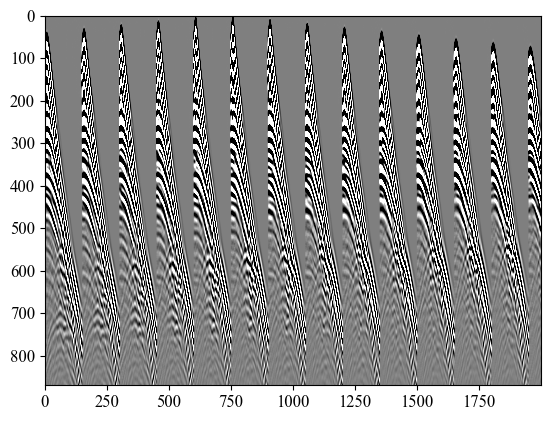

In [15]:
print(observed_data.shape)
plt.imshow(observed_data[0, :2000,:].T.cpu(), aspect='auto',
           vmin=-1e-2, vmax=1e-2, cmap="gray")

In [17]:
# Upsample source_amplitudes
max_vel = 6e3
dt, step_ratio = deepwave3D.common.cfl_condition(dz, dy, dx, dt, max_vel)
source_amplitudes_true = deepwave3D.common.upsample(source_amplitudes_true,
                                             step_ratio)


nt = source_amplitudes_true.shape[-1]

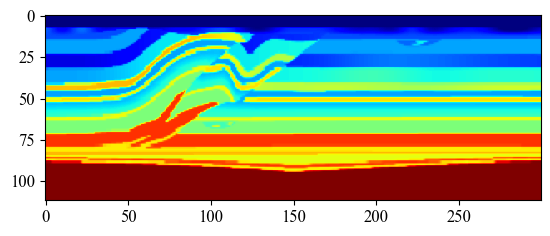

In [18]:
plt.imshow(model_true[:,50,:].cpu().numpy(), vmin=2.5e3, vmax=6.0e3,cmap='jet')

In [19]:
model_init = v0['True']
model_init = model_init[:nz,:ny,:nx]
model_init[8:,:] = scipy.ndimage.gaussian_filter(model_init[8:,:],sigma=23)


depth = 8 #8
v_init = 4.25e3
v_final = 4.25e3 
n_layer = nz - depth
vel_profile = np.linspace(v_init, v_final, n_layer).reshape(-1, 1, 1)  # [nz-z0, 1, 1]
vel_3d = np.tile(vel_profile, (1, ny, nx))  
model_init[depth:, :, :] = vel_3d  


model_init = torch.Tensor(model_init)
model = model_init.clone()
model = model.to(device)
model.requires_grad = True

source_amplitudes = source_amplitudes_true
mask = torch.ones_like(model)
mask[:8, :] = 0

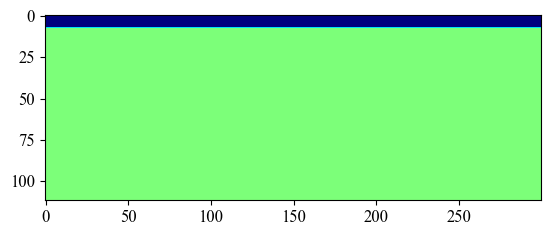

In [20]:
plt.imshow(model[:,2,:].cpu().detach().numpy(), vmin=2.5e3, vmax=6.0e3,cmap='jet')
# scipy.io.savemat('./result/Int_domo.mat',{'Int':model_init.cpu().detach()})

In [21]:
in_features = 3 # z,y,x
out_features = 1 # vp
hidden_features = 256
hidden_layers = 4
imvel = Siren(in_features=in_features, 
              out_features=out_features, 
              hidden_features=hidden_features, 
              hidden_layers=hidden_layers, 
              hidden_omega_0=30.0,
              outermost_linear=True,
              domain_shape=(nz//1, ny//1, nx//1)).to(device)
coords = imvel.coords.to(device)


imvel = F_Siren(in_features=1, 
              out_features=out_features, 
              hidden_features=hidden_features, 
              hidden_layers=hidden_layers, 
              rank = 64,
              first_omega_0=20, 
              hidden_omega_0=20.0,
              type='sin',
              outermost_linear=True,
              decomp_mode='TT',
              domain_shape=(nz, ny, nx)).to(device)
zcoords = imvel.zcoords.to(device)
ycoords = imvel.ycoords.to(device)
xcoords = imvel.xcoords.to(device)


pytorch_total_params = sum(p.numel() for p in imvel.parameters() if p.requires_grad)
print('Total Number of Parameters:', pytorch_total_params)

for name, param in imvel.named_parameters():
    if param.requires_grad:
        print(f"Layer: {name} | Shape: {param.shape} | #Params: {param.numel()}")

Cannot find the pretrained model ''. Using random initialization.
Domain Shape: (112, 300, 300), Mode: TT
Cannot find the pretrained model ''. Using random initialization.
Cannot find the pretrained model ''. Using random initialization.
Cannot find the pretrained model ''. Using random initialization.
Total Number of Parameters: 1407840
Layer: fz.net.0.linear.weight | Shape: torch.Size([256, 1]) | #Params: 256
Layer: fz.net.0.linear.bias | Shape: torch.Size([256]) | #Params: 256
Layer: fz.net.1.linear.weight | Shape: torch.Size([256, 256]) | #Params: 65536
Layer: fz.net.1.linear.bias | Shape: torch.Size([256]) | #Params: 256
Layer: fz.net.2.linear.weight | Shape: torch.Size([256, 256]) | #Params: 65536
Layer: fz.net.2.linear.bias | Shape: torch.Size([256]) | #Params: 256
Layer: fz.net.3.linear.weight | Shape: torch.Size([256, 256]) | #Params: 65536
Layer: fz.net.3.linear.bias | Shape: torch.Size([256]) | #Params: 256
Layer: fz.net.4.linear.weight | Shape: torch.Size([256, 256]) | #Par

In [23]:
from torchsummary import summary
from torchinfo import summary


# summary(imvel.to('cpu'),input_size=(10080000//1, 3),device='cpu')
# summary(imvel.to('cpu'),[(nz,1),(ny,1),(nx,1)],device='cpu')

In [24]:
# Setup optimiser to perform inversion
optimizer = torch.optim.Adam(imvel.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1000, gamma=0.8, last_epoch=-1)


loss_fn = torch.nn.MSELoss()
# Run optimisation/inversion
cutoff_freq = 10

In [25]:
sos = butter(6, cutoff_freq, fs=1/dt, output='sos')
sos = [torch.tensor(sosi).to(observed_data.dtype).to(device)
       for sosi in sos]

In [26]:
def taper(x):
    return deepwave3D.common.cosine_taper_end(x, 600)


def filt(x):
    return biquad(biquad(biquad(x, *sos[0]), *sos[1]), *sos[2])

In [27]:
def wrap(v, dz, dy, dx, dt, chunk, source_locations, receiver_locations, freq, pml_width, wavefield_0, wavefield_m1, psiz_m1, psiy_m1, psix_m1,
         zetaz_m1, zetay_m1, zetax_m1):
    return scalar(
                  v, [dz,dy,dx], dt,
                  source_amplitudes=chunk,
                  source_locations=source_locations,
                  receiver_locations=receiver_locations,
                  pml_freq=freq,
                  pml_width = pml_width,
                  wavefield_0=wavefield_0,
                  wavefield_m1=wavefield_m1,
                  psiz_m1=psiz_m1,
                  psiy_m1=psiy_m1,
                  psix_m1=psix_m1,
                  zetaz_m1=zetaz_m1,
                  zetay_m1=zetay_m1,
                  zetax_m1=zetax_m1,
                  max_vel=max_vel,
                  model_gradient_sampling_interval=step_ratio
              )

In [29]:
from misfit import *
criterion_data = torch.nn.MSELoss()
criterion_data = Misfit_M_SSIM3D(gaussian_sigmas=[2], alpha=10, compensation=10)

100%|██████████████████████████████████████████████████████████| 1/1 [00:06<00:00,  6.75s/it]

Epoch: 0 Loss:  -4.735720634460449 model_loss:  1119858.0


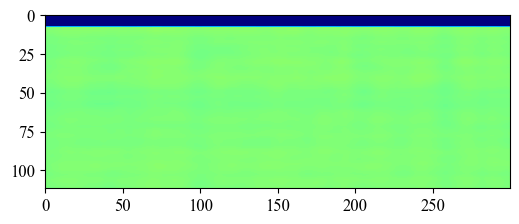

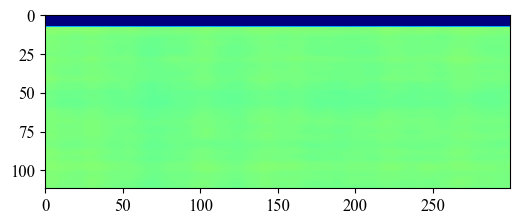

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.92s/it]


Epoch: 1 Loss:  -4.856505870819092 model_loss:  1400706.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 2 Loss:  -5.1153998374938965 model_loss:  1832908.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]


Epoch: 3 Loss:  -3.6338515281677246 model_loss:  4468528.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]


Epoch: 9 Loss:  -4.783188819885254 model_loss:  1215391.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 10 Loss:  -4.828021049499512 model_loss:  1216990.4


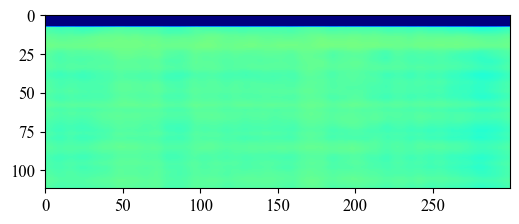

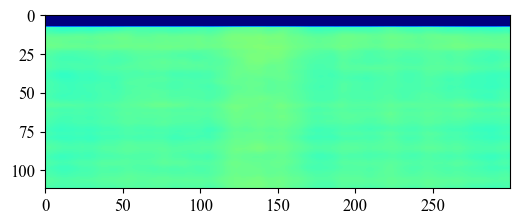

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 11 Loss:  -4.874603271484375 model_loss:  1227966.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 12 Loss:  -4.867396831512451 model_loss:  1247899.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 13 Loss:  -4.906506061553955 model_loss:  1277192.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 19 Loss:  -5.403284072875977 model_loss:  2340465.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]

Epoch: 20 Loss:  -5.438381195068359 model_loss:  1976465.5


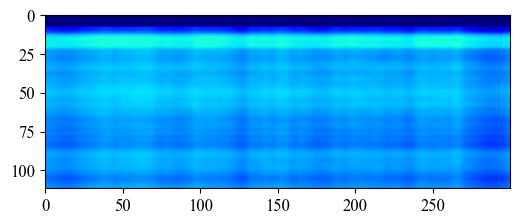

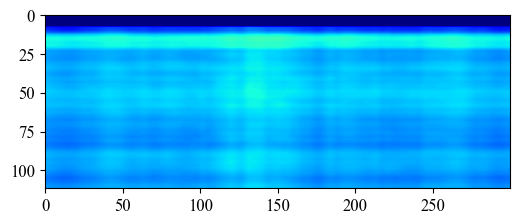

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 21 Loss:  -5.200023651123047 model_loss:  1872597.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 22 Loss:  -5.257887840270996 model_loss:  1880626.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 23 Loss:  -5.193248748779297 model_loss:  1922754.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 29 Loss:  -5.525356292724609 model_loss:  2057352.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 30 Loss:  -5.651778697967529 model_loss:  1956137.9


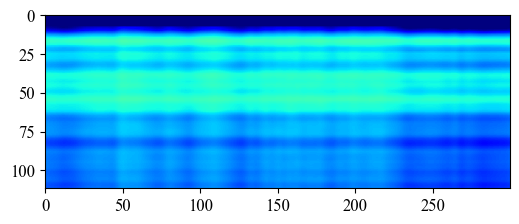

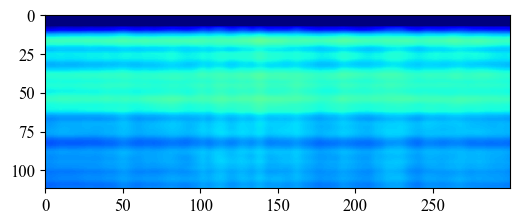

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 31 Loss:  -5.6987152099609375 model_loss:  1988009.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 32 Loss:  -5.591645240783691 model_loss:  2019595.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 33 Loss:  -5.746274948120117 model_loss:  1892395.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 39 Loss:  -5.88806676864624 model_loss:  1888554.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 40 Loss:  -5.966000556945801 model_loss:  1861532.6


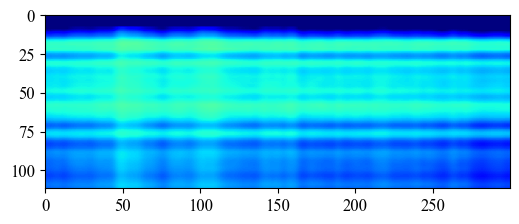

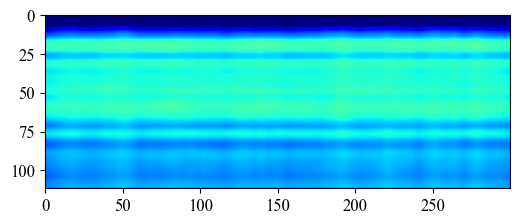

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 41 Loss:  -5.815243721008301 model_loss:  1766953.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 42 Loss:  -5.819404602050781 model_loss:  1878019.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 43 Loss:  -5.63282585144043 model_loss:  1723358.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 49 Loss:  -5.880274295806885 model_loss:  1739043.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 50 Loss:  -5.957581520080566 model_loss:  1738205.2


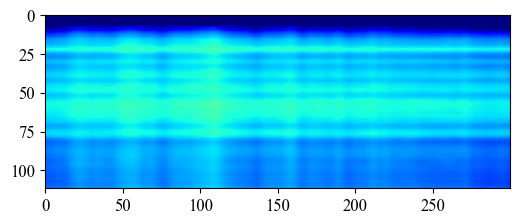

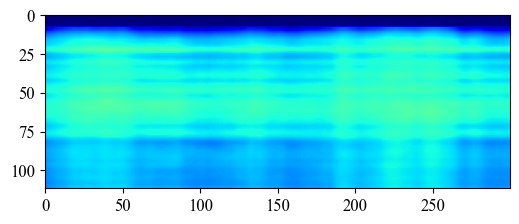

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 51 Loss:  -6.001277446746826 model_loss:  1816623.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 52 Loss:  -6.177796363830566 model_loss:  1760770.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 53 Loss:  -6.08869743347168 model_loss:  1732335.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 59 Loss:  -5.926868438720703 model_loss:  1850060.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 60 Loss:  -5.848255157470703 model_loss:  1838274.6


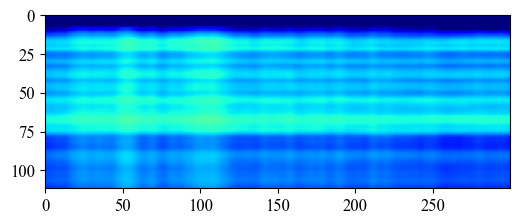

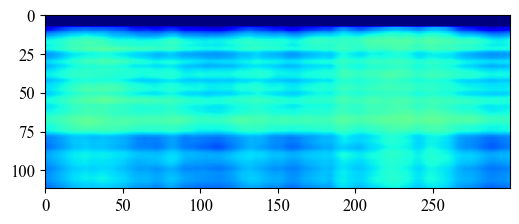

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 61 Loss:  -6.080238342285156 model_loss:  1942239.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 62 Loss:  -5.938321113586426 model_loss:  1997680.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 63 Loss:  -5.879384994506836 model_loss:  1856855.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 69 Loss:  -5.7899169921875 model_loss:  2027789.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]

Epoch: 70 Loss:  -6.183646202087402 model_loss:  1930614.9


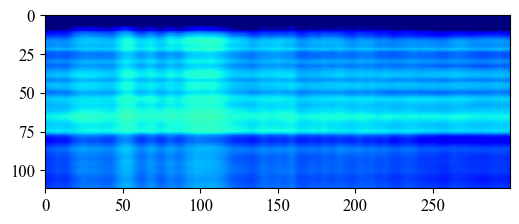

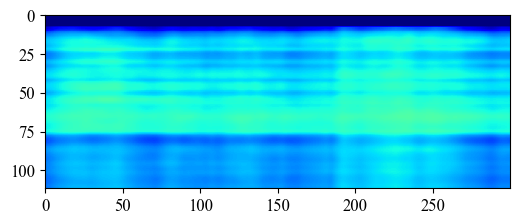

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 71 Loss:  -5.728899955749512 model_loss:  1805698.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 72 Loss:  -5.986478805541992 model_loss:  1818603.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 73 Loss:  -6.065270900726318 model_loss:  1935587.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 79 Loss:  -5.988377571105957 model_loss:  1803098.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 80 Loss:  -6.336224555969238 model_loss:  1885277.2


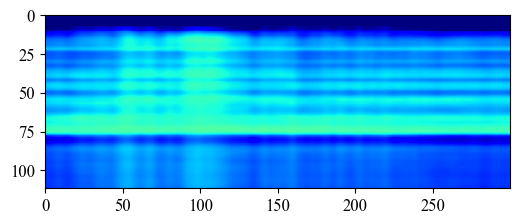

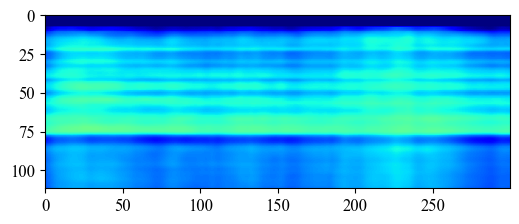

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 81 Loss:  -6.317293167114258 model_loss:  1910043.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 82 Loss:  -5.933398246765137 model_loss:  1800407.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 83 Loss:  -6.459736347198486 model_loss:  1872764.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 89 Loss:  -6.18286657333374 model_loss:  1817532.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 90 Loss:  -6.147751808166504 model_loss:  1917452.1


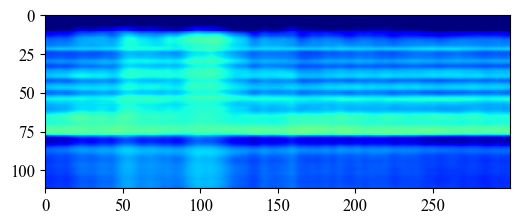

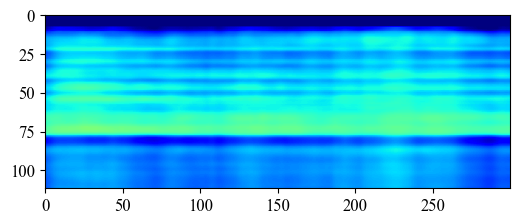

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 91 Loss:  -6.370211601257324 model_loss:  1848105.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 92 Loss:  -6.202853202819824 model_loss:  1799897.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 93 Loss:  -6.139770030975342 model_loss:  1902927.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 99 Loss:  -6.20703649520874 model_loss:  1870264.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 100 Loss:  -6.45716667175293 model_loss:  1785978.4


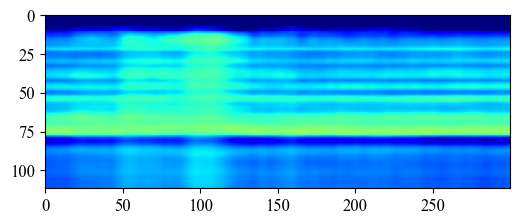

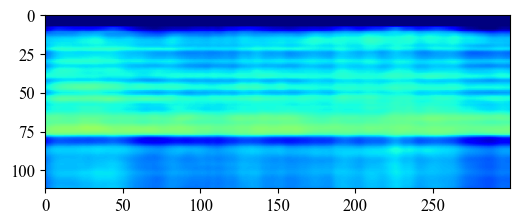

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 101 Loss:  -6.654070854187012 model_loss:  1807698.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 102 Loss:  -6.212055683135986 model_loss:  1840508.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 103 Loss:  -6.197105407714844 model_loss:  1742695.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 109 Loss:  -6.401747703552246 model_loss:  1845844.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 110 Loss:  -5.6363630294799805 model_loss:  1699955.6


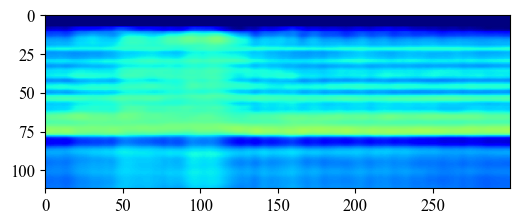

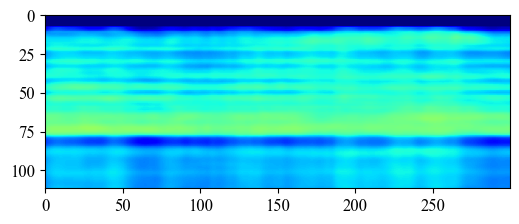

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 111 Loss:  -5.381537437438965 model_loss:  1665826.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 112 Loss:  -5.681439399719238 model_loss:  1688093.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 113 Loss:  -5.806676864624023 model_loss:  1756286.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 119 Loss:  -6.049012660980225 model_loss:  1811764.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 120 Loss:  -6.044040203094482 model_loss:  1761677.1


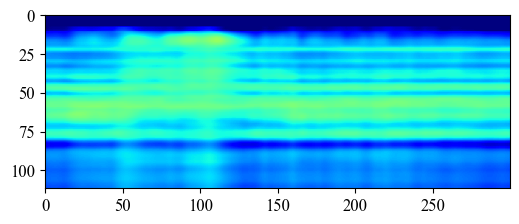

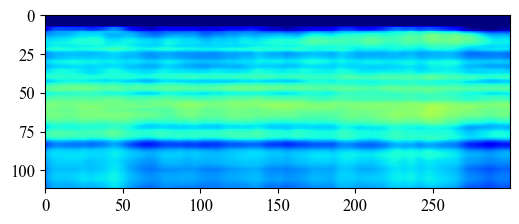

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 121 Loss:  -6.238288879394531 model_loss:  1771071.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 122 Loss:  -6.194384574890137 model_loss:  1823202.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 123 Loss:  -6.305665493011475 model_loss:  1767812.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 129 Loss:  -6.33209753036499 model_loss:  1722143.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 130 Loss:  -6.053884506225586 model_loss:  1666681.6


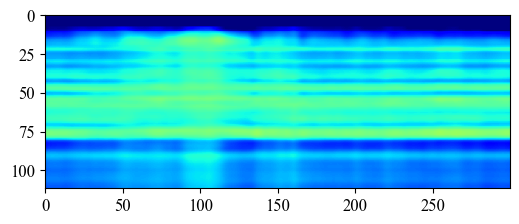

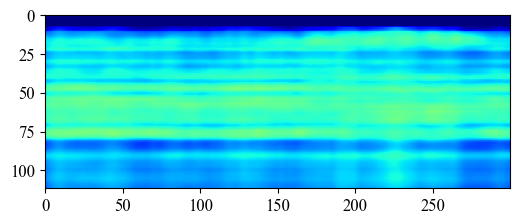

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 131 Loss:  -6.388774394989014 model_loss:  1728340.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 132 Loss:  -6.3379597663879395 model_loss:  1752700.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 133 Loss:  -6.370567798614502 model_loss:  1677959.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 139 Loss:  -6.267594814300537 model_loss:  1633864.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 140 Loss:  -6.594753265380859 model_loss:  1667092.8


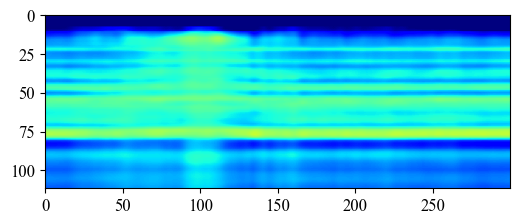

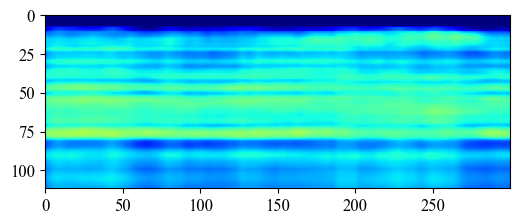

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 141 Loss:  -6.217308044433594 model_loss:  1718905.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 142 Loss:  -6.455068588256836 model_loss:  1655944.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 143 Loss:  -6.436283588409424 model_loss:  1657013.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 149 Loss:  -6.449508190155029 model_loss:  1618676.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 150 Loss:  -6.576934337615967 model_loss:  1638533.2


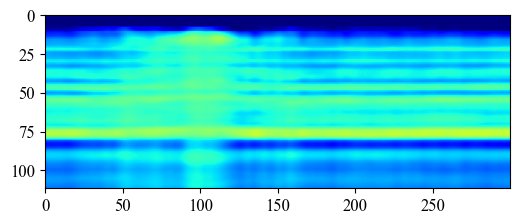

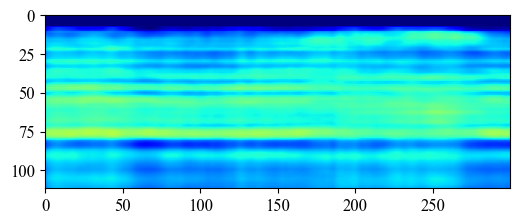

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 151 Loss:  -6.406899452209473 model_loss:  1677299.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 152 Loss:  -6.539813041687012 model_loss:  1621067.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 153 Loss:  -6.61907958984375 model_loss:  1624961.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 159 Loss:  -6.644949436187744 model_loss:  1653823.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 160 Loss:  -6.769927024841309 model_loss:  1630634.5


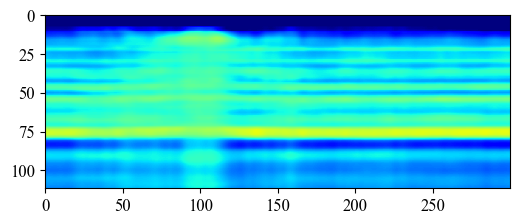

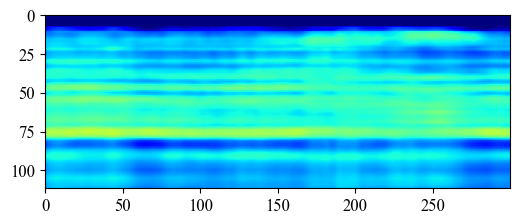

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 161 Loss:  -6.729076385498047 model_loss:  1624729.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 162 Loss:  -6.681210517883301 model_loss:  1626953.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 163 Loss:  -6.713560104370117 model_loss:  1599814.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 169 Loss:  -6.728968143463135 model_loss:  1624874.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 170 Loss:  -6.556324481964111 model_loss:  1578950.0


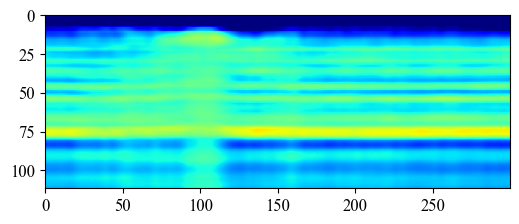

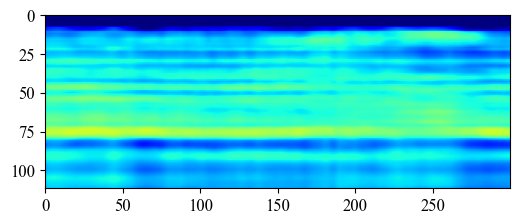

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 171 Loss:  -6.673157215118408 model_loss:  1617807.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 172 Loss:  -6.725180149078369 model_loss:  1596288.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 173 Loss:  -6.693508625030518 model_loss:  1587120.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 179 Loss:  -6.680195331573486 model_loss:  1605736.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 180 Loss:  -6.8045501708984375 model_loss:  1585553.9


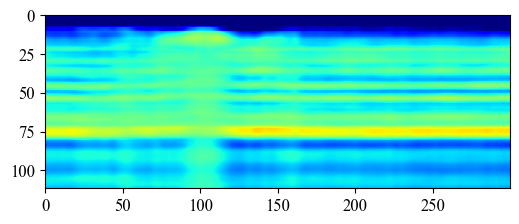

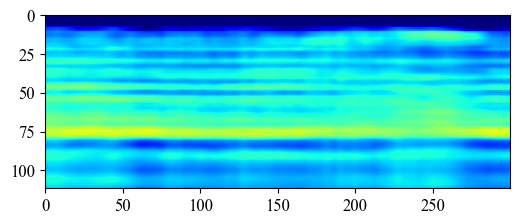

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 181 Loss:  -6.840526580810547 model_loss:  1584184.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 182 Loss:  -6.696598529815674 model_loss:  1600897.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 183 Loss:  -6.545082092285156 model_loss:  1541449.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 189 Loss:  -6.788687229156494 model_loss:  1547074.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 190 Loss:  -6.758761882781982 model_loss:  1574411.6


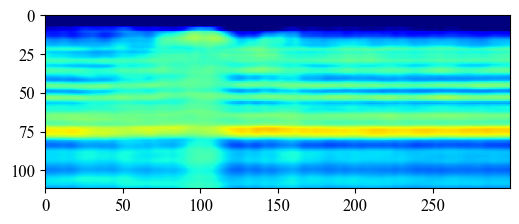

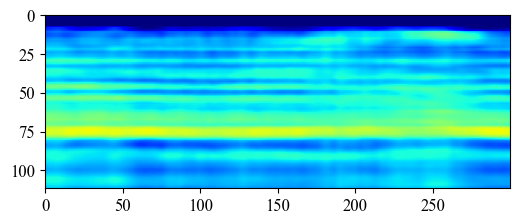

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 191 Loss:  -6.679858684539795 model_loss:  1533846.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 192 Loss:  -6.854488849639893 model_loss:  1569847.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 193 Loss:  -6.907681465148926 model_loss:  1555726.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 199 Loss:  -6.510281562805176 model_loss:  1565428.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 200 Loss:  -6.851096153259277 model_loss:  1512609.2


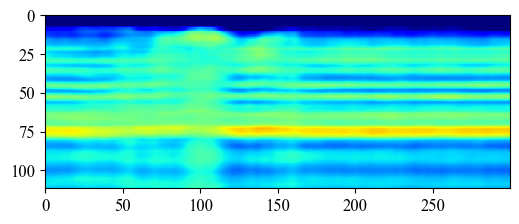

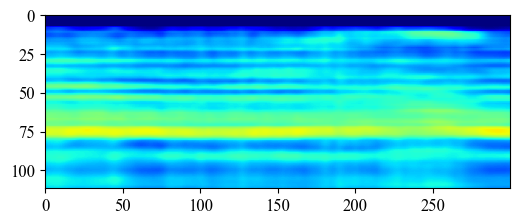

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 201 Loss:  -6.970496654510498 model_loss:  1517827.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 202 Loss:  -6.9102678298950195 model_loss:  1526777.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 203 Loss:  -6.584698677062988 model_loss:  1490646.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 209 Loss:  -6.643173694610596 model_loss:  1526617.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 210 Loss:  -6.451427936553955 model_loss:  1463027.6


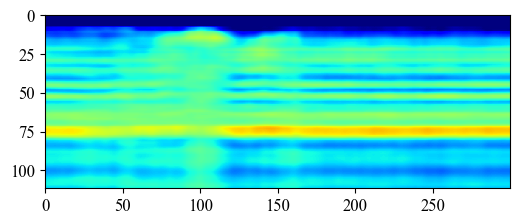

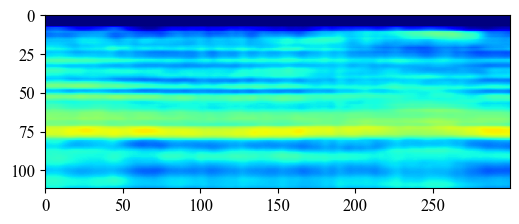

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 211 Loss:  -6.920320510864258 model_loss:  1491566.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 212 Loss:  -5.798907279968262 model_loss:  1559214.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 213 Loss:  -6.706840991973877 model_loss:  1527534.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 219 Loss:  -6.491793632507324 model_loss:  1589156.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 220 Loss:  -6.047351837158203 model_loss:  1501218.5


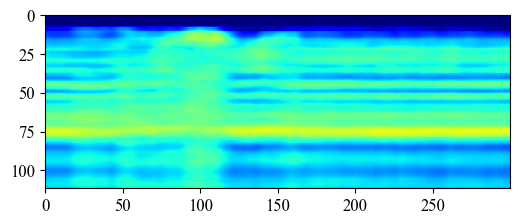

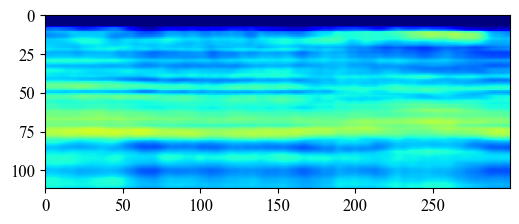

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 221 Loss:  -6.249615669250488 model_loss:  1498607.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 222 Loss:  -6.165109157562256 model_loss:  1564753.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 223 Loss:  -6.24167537689209 model_loss:  1574611.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 229 Loss:  -6.270780086517334 model_loss:  1558123.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 230 Loss:  -6.1669487953186035 model_loss:  1641055.1


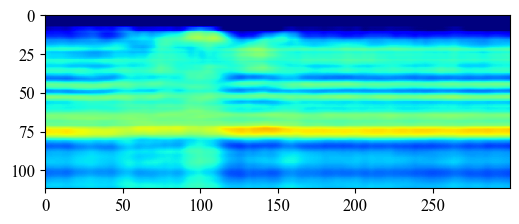

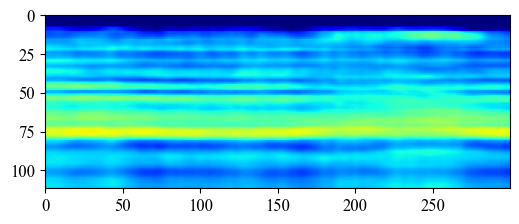

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 231 Loss:  -6.3937788009643555 model_loss:  1627128.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 232 Loss:  -6.050601959228516 model_loss:  1537709.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 233 Loss:  -5.799494743347168 model_loss:  1526013.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 239 Loss:  -6.601767063140869 model_loss:  1642593.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 240 Loss:  -6.561198711395264 model_loss:  1646854.4


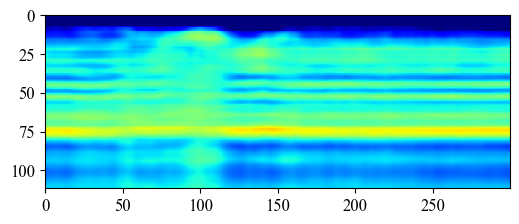

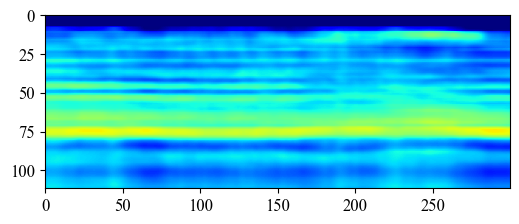

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 241 Loss:  -6.425829887390137 model_loss:  1588499.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 242 Loss:  -6.737428665161133 model_loss:  1602446.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 243 Loss:  -6.3690900802612305 model_loss:  1652750.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 249 Loss:  -6.196042060852051 model_loss:  1544379.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 250 Loss:  -6.417283058166504 model_loss:  1559422.0


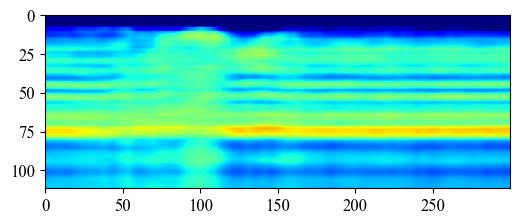

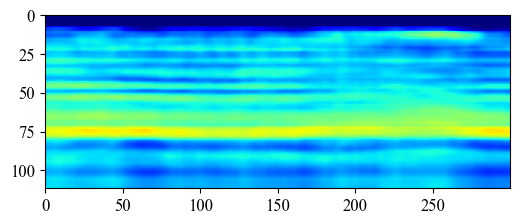

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 251 Loss:  -6.580863952636719 model_loss:  1637207.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 252 Loss:  -6.733743667602539 model_loss:  1623879.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 253 Loss:  -6.4258928298950195 model_loss:  1562554.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 259 Loss:  -6.805408477783203 model_loss:  1610825.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 260 Loss:  -6.324271202087402 model_loss:  1652114.1


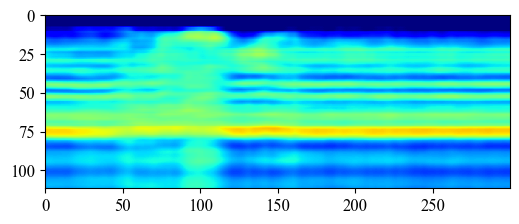

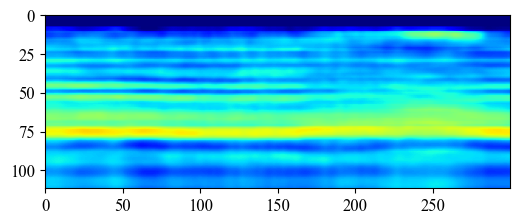

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 261 Loss:  -6.780198097229004 model_loss:  1611489.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 262 Loss:  -5.968524932861328 model_loss:  1542616.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 263 Loss:  -6.39967155456543 model_loss:  1544955.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 269 Loss:  -6.899158477783203 model_loss:  1597689.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 270 Loss:  -6.698235988616943 model_loss:  1547576.6


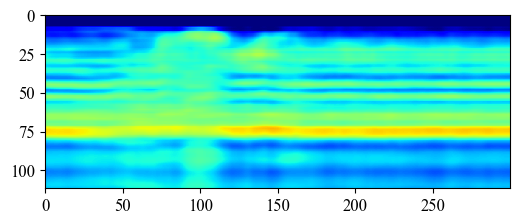

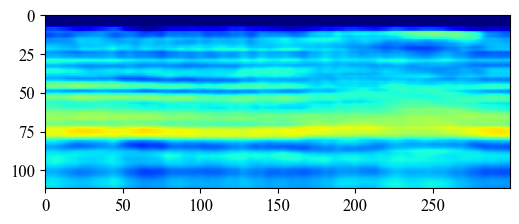

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 271 Loss:  -6.932950973510742 model_loss:  1563194.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 272 Loss:  -6.761919021606445 model_loss:  1581508.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 273 Loss:  -6.919258117675781 model_loss:  1546035.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 279 Loss:  -6.985666275024414 model_loss:  1532845.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 280 Loss:  -7.136096954345703 model_loss:  1542895.0


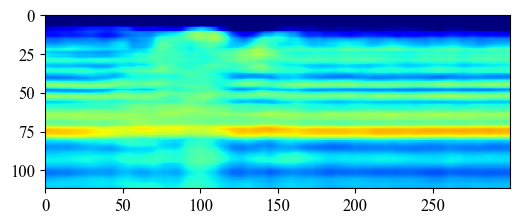

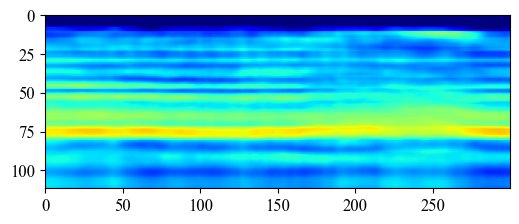

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 281 Loss:  -7.055652618408203 model_loss:  1544732.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 282 Loss:  -6.898223876953125 model_loss:  1514257.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 283 Loss:  -7.110763072967529 model_loss:  1532555.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 289 Loss:  -7.104458808898926 model_loss:  1497418.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 290 Loss:  -7.083779335021973 model_loss:  1515853.2


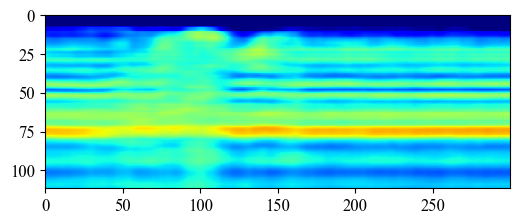

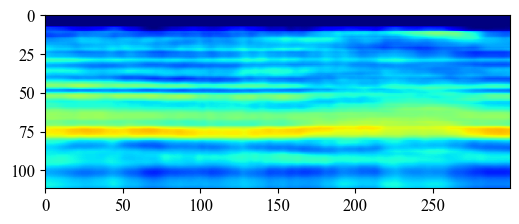

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 291 Loss:  -7.1695051193237305 model_loss:  1492972.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 292 Loss:  -7.16855001449585 model_loss:  1500048.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 293 Loss:  -7.220287322998047 model_loss:  1495029.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 299 Loss:  -7.077966690063477 model_loss:  1497681.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 300 Loss:  -7.102961540222168 model_loss:  1471893.6


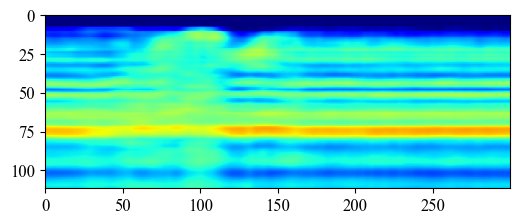

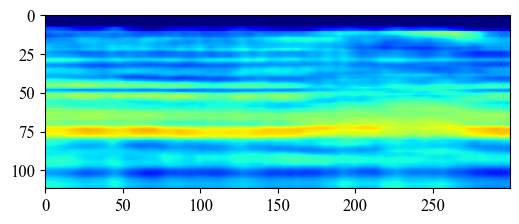

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 301 Loss:  -7.047248840332031 model_loss:  1491824.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 302 Loss:  -7.131819248199463 model_loss:  1465831.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 303 Loss:  -7.111844062805176 model_loss:  1480230.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 309 Loss:  -7.161084175109863 model_loss:  1473869.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 310 Loss:  -7.009428024291992 model_loss:  1450186.8


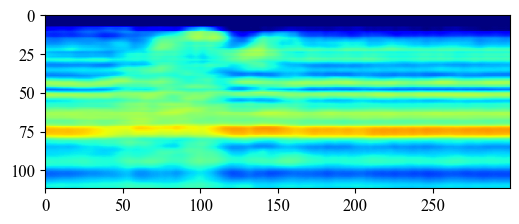

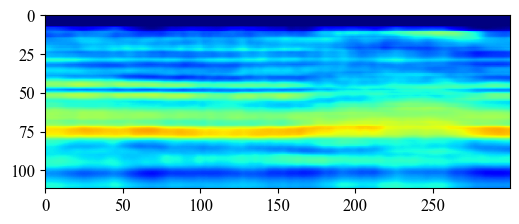

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 311 Loss:  -6.9770121574401855 model_loss:  1488823.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 312 Loss:  -7.0306925773620605 model_loss:  1460674.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 313 Loss:  -7.293992042541504 model_loss:  1484647.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 319 Loss:  -7.142629146575928 model_loss:  1466596.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 320 Loss:  -6.811681747436523 model_loss:  1430160.9


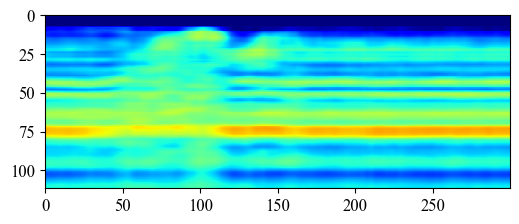

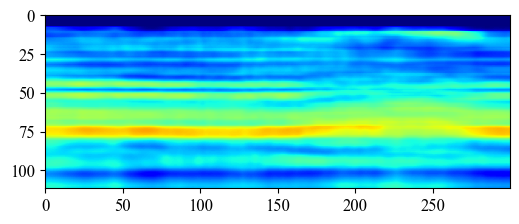

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 321 Loss:  -7.1651153564453125 model_loss:  1460606.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 322 Loss:  -7.293086528778076 model_loss:  1454617.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 323 Loss:  -7.130129337310791 model_loss:  1440703.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]


Epoch: 329 Loss:  -7.241115570068359 model_loss:  1446964.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 330 Loss:  -7.319232940673828 model_loss:  1427501.0


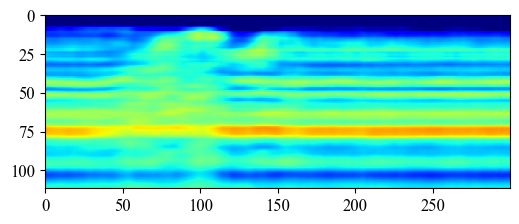

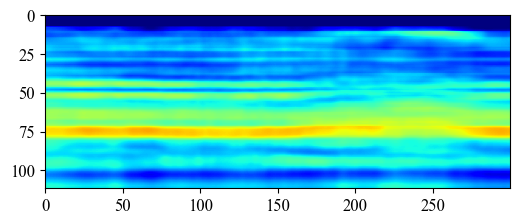

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 331 Loss:  -7.335204124450684 model_loss:  1428119.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 332 Loss:  -7.393838882446289 model_loss:  1417689.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 333 Loss:  -7.372698783874512 model_loss:  1418772.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 339 Loss:  -6.938399791717529 model_loss:  1394857.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 340 Loss:  -7.225947380065918 model_loss:  1423177.2


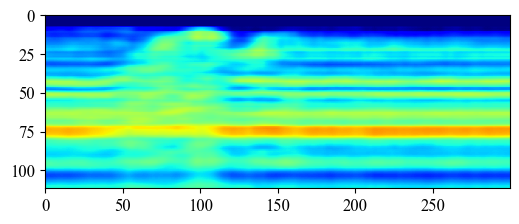

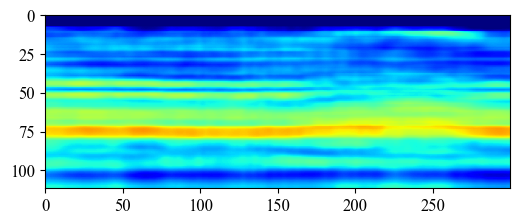

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 341 Loss:  -7.284156799316406 model_loss:  1421636.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 342 Loss:  -7.02696418762207 model_loss:  1386820.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 343 Loss:  -7.1453070640563965 model_loss:  1410502.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 349 Loss:  -7.379057884216309 model_loss:  1376949.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 350 Loss:  -7.104273796081543 model_loss:  1360541.2


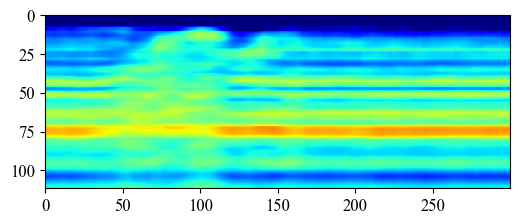

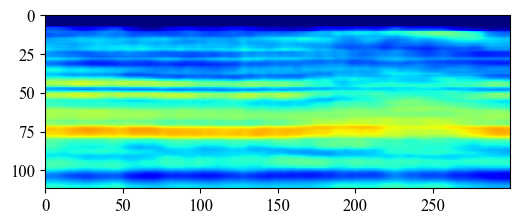

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 351 Loss:  -7.130894660949707 model_loss:  1398784.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 352 Loss:  -7.35294771194458 model_loss:  1382881.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 353 Loss:  -7.430892467498779 model_loss:  1387065.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 359 Loss:  -7.277377128601074 model_loss:  1364018.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 360 Loss:  -7.519633769989014 model_loss:  1349010.9


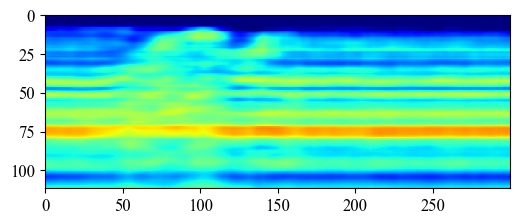

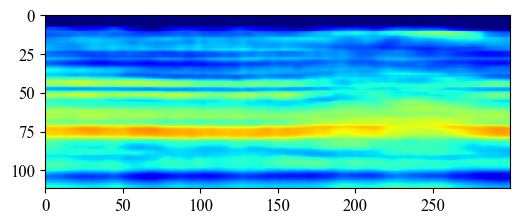

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 361 Loss:  -7.410773277282715 model_loss:  1346290.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 362 Loss:  -7.224533557891846 model_loss:  1362008.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 363 Loss:  -7.017848968505859 model_loss:  1333762.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 369 Loss:  -7.464800834655762 model_loss:  1350914.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]

Epoch: 370 Loss:  -7.440550327301025 model_loss:  1349327.5


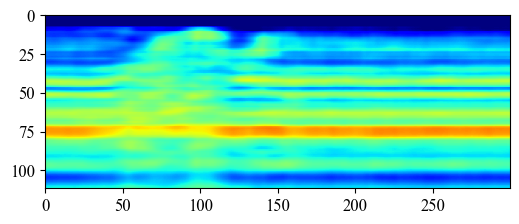

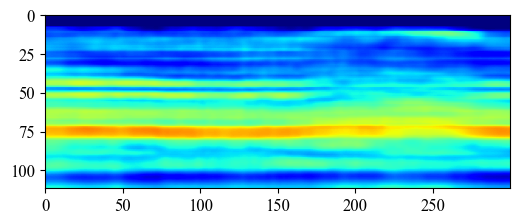

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 371 Loss:  -7.161977291107178 model_loss:  1322398.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 372 Loss:  -7.187612056732178 model_loss:  1343434.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 373 Loss:  -7.484612464904785 model_loss:  1315175.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 379 Loss:  -7.536010265350342 model_loss:  1314129.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 380 Loss:  -7.644656181335449 model_loss:  1318625.9


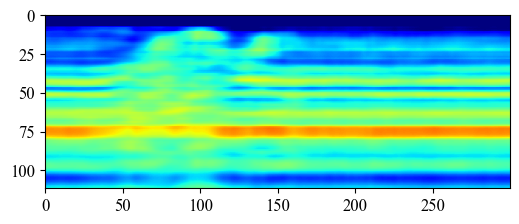

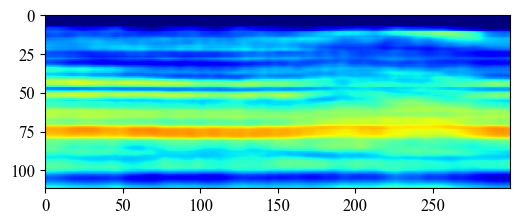

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 381 Loss:  -7.42527437210083 model_loss:  1315127.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 382 Loss:  -7.350358486175537 model_loss:  1337733.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 383 Loss:  -7.292022705078125 model_loss:  1315916.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 389 Loss:  -7.213395118713379 model_loss:  1317778.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 390 Loss:  -7.404506683349609 model_loss:  1346260.8


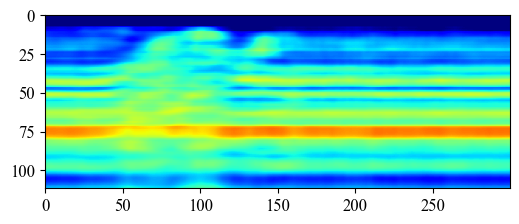

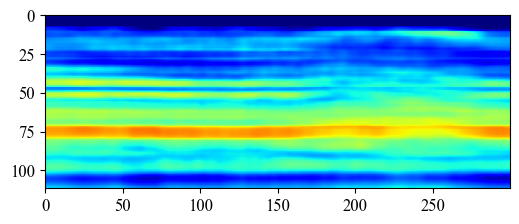

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 391 Loss:  -7.558739185333252 model_loss:  1329960.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 392 Loss:  -7.551255226135254 model_loss:  1336215.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 393 Loss:  -7.663991928100586 model_loss:  1327541.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 399 Loss:  -7.2200846672058105 model_loss:  1331151.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 400 Loss:  -6.920328140258789 model_loss:  1297985.9


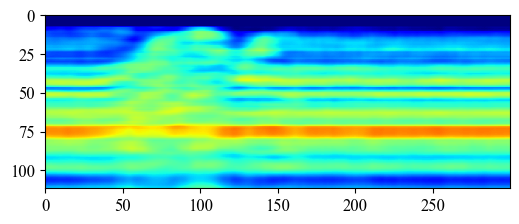

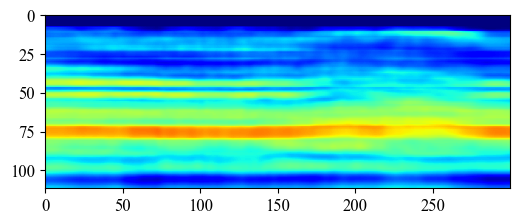

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 401 Loss:  -7.51854133605957 model_loss:  1311460.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 402 Loss:  -6.7399187088012695 model_loss:  1337921.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 403 Loss:  -7.4730753898620605 model_loss:  1311501.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 409 Loss:  -7.104940414428711 model_loss:  1331823.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 410 Loss:  -7.0748701095581055 model_loss:  1302932.8


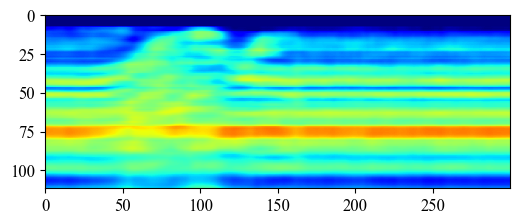

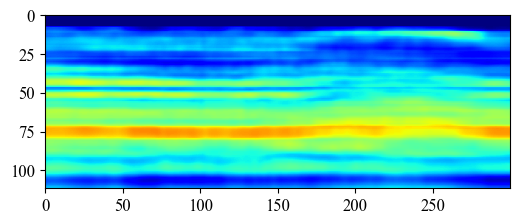

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 411 Loss:  -7.204225063323975 model_loss:  1315865.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 412 Loss:  -7.1045966148376465 model_loss:  1347781.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 413 Loss:  -7.5193400382995605 model_loss:  1332456.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 419 Loss:  -7.3984694480896 model_loss:  1300149.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 420 Loss:  -7.383744716644287 model_loss:  1288888.6


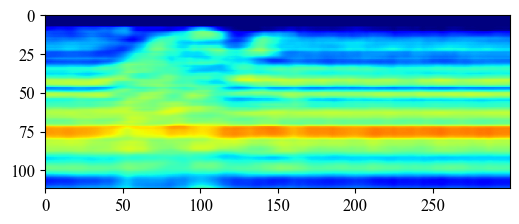

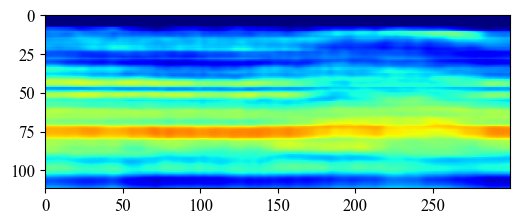

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 421 Loss:  -6.8701324462890625 model_loss:  1320078.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 422 Loss:  -7.399621486663818 model_loss:  1308045.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 423 Loss:  -6.835794448852539 model_loss:  1286254.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 429 Loss:  -7.434796333312988 model_loss:  1290627.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 430 Loss:  -7.57190465927124 model_loss:  1296648.9


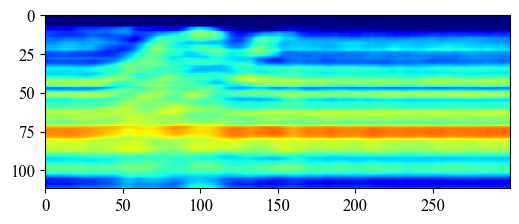

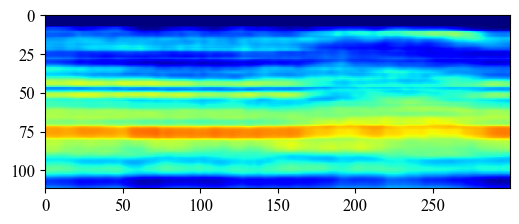

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 431 Loss:  -7.240116119384766 model_loss:  1310854.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 432 Loss:  -7.142405986785889 model_loss:  1279429.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 433 Loss:  -7.626040458679199 model_loss:  1291624.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 439 Loss:  -7.653045654296875 model_loss:  1294352.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 440 Loss:  -7.480428218841553 model_loss:  1305554.8


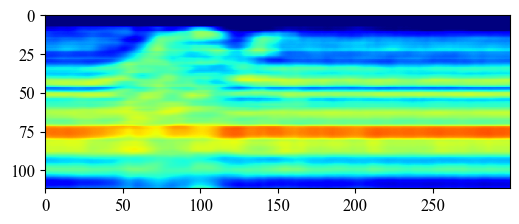

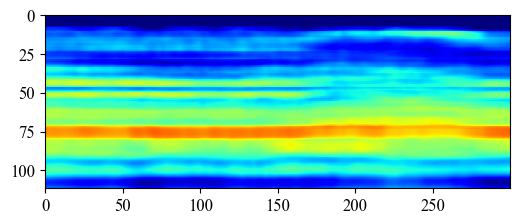

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 441 Loss:  -7.34539794921875 model_loss:  1277038.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 442 Loss:  -7.653010368347168 model_loss:  1287822.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 443 Loss:  -7.585393905639648 model_loss:  1291515.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 449 Loss:  -7.287118911743164 model_loss:  1314504.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 450 Loss:  -7.810997486114502 model_loss:  1291429.9


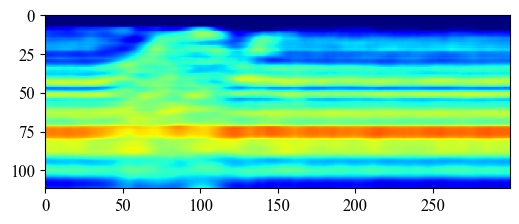

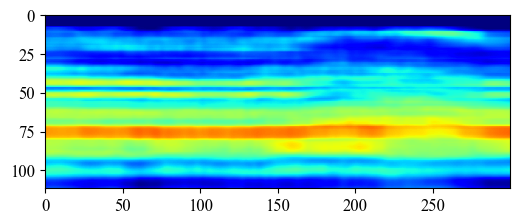

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 451 Loss:  -7.2871198654174805 model_loss:  1276755.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 452 Loss:  -7.240663528442383 model_loss:  1303972.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 453 Loss:  -7.772068977355957 model_loss:  1289229.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 459 Loss:  -7.702028274536133 model_loss:  1265069.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 460 Loss:  -7.81485652923584 model_loss:  1266146.6


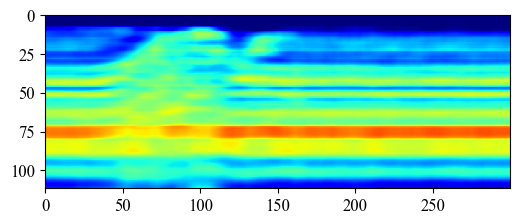

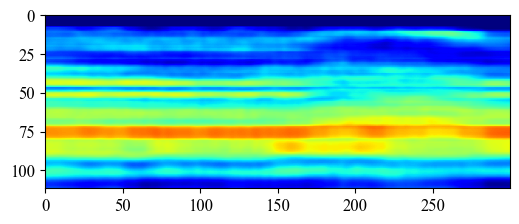

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 461 Loss:  -7.621334075927734 model_loss:  1274984.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 462 Loss:  -7.356588363647461 model_loss:  1251236.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 463 Loss:  -7.762336730957031 model_loss:  1266232.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 469 Loss:  -7.809906005859375 model_loss:  1234804.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 470 Loss:  -7.623706817626953 model_loss:  1247628.0


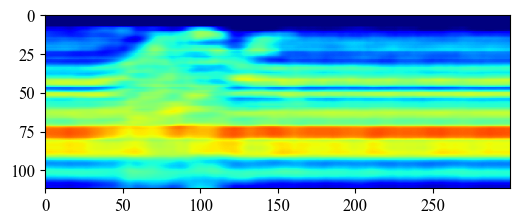

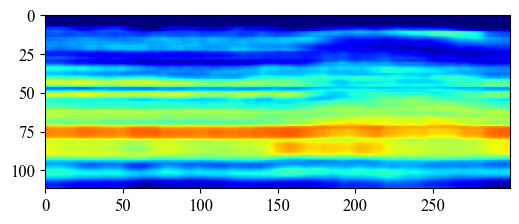

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 471 Loss:  -7.519368648529053 model_loss:  1228369.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 472 Loss:  -7.745579719543457 model_loss:  1245909.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 473 Loss:  -7.817821025848389 model_loss:  1248209.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 479 Loss:  -7.884252071380615 model_loss:  1204626.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 480 Loss:  -7.985934257507324 model_loss:  1200204.6


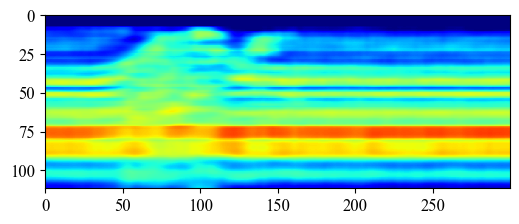

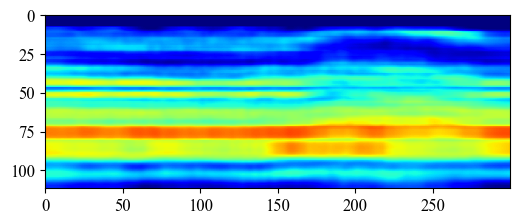

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 481 Loss:  -7.915291786193848 model_loss:  1193291.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 482 Loss:  -7.775070667266846 model_loss:  1179183.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 483 Loss:  -7.603919982910156 model_loss:  1193321.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 489 Loss:  -7.612423896789551 model_loss:  1165580.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 490 Loss:  -7.573877334594727 model_loss:  1142407.2


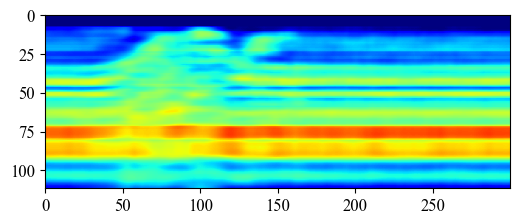

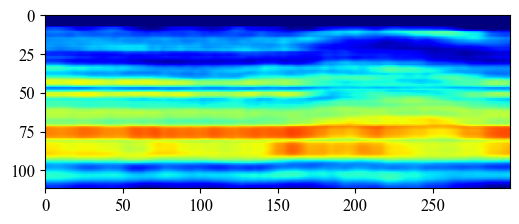

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 491 Loss:  -7.978425025939941 model_loss:  1152689.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 492 Loss:  -8.112998962402344 model_loss:  1141722.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 493 Loss:  -8.064204216003418 model_loss:  1141337.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 499 Loss:  -7.428000450134277 model_loss:  1108002.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 500 Loss:  -8.06692886352539 model_loss:  1116359.1


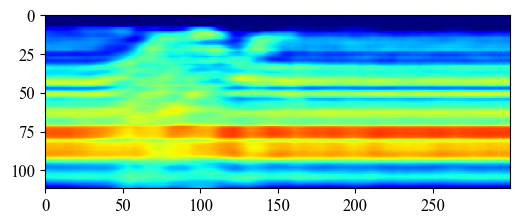

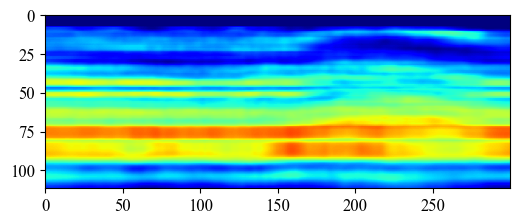

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 501 Loss:  -7.698853015899658 model_loss:  1126249.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 502 Loss:  -7.0703887939453125 model_loss:  1107170.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 503 Loss:  -7.7168169021606445 model_loss:  1120313.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 509 Loss:  -7.313368797302246 model_loss:  1124081.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 510 Loss:  -7.809477806091309 model_loss:  1114316.9


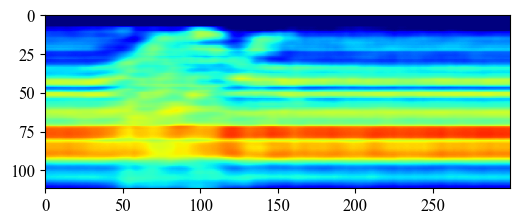

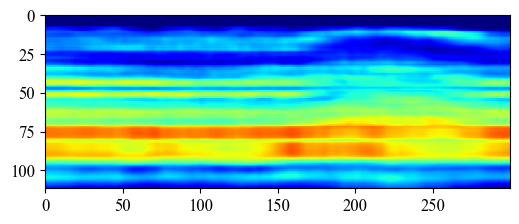

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 511 Loss:  -7.328212738037109 model_loss:  1097398.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 512 Loss:  -7.705357551574707 model_loss:  1111028.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 513 Loss:  -7.757301330566406 model_loss:  1113973.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 519 Loss:  -7.797635078430176 model_loss:  1097357.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 520 Loss:  -7.333834171295166 model_loss:  1085233.8


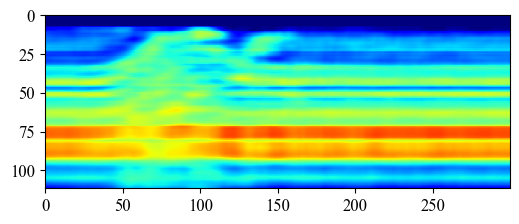

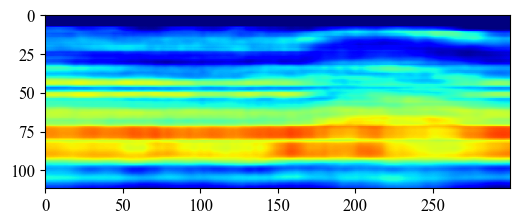

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 521 Loss:  -7.58909797668457 model_loss:  1098323.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 522 Loss:  -7.843660831451416 model_loss:  1096686.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 523 Loss:  -7.297327041625977 model_loss:  1079439.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 529 Loss:  -7.951220989227295 model_loss:  1078915.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 530 Loss:  -7.184412479400635 model_loss:  1096686.9


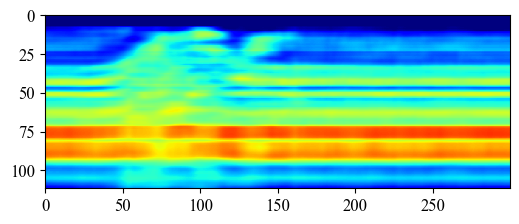

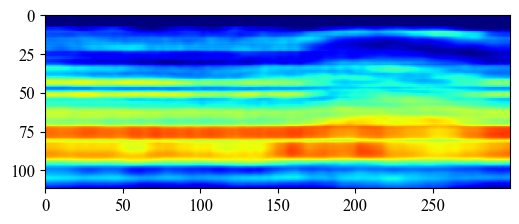

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 531 Loss:  -7.90155029296875 model_loss:  1082548.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 532 Loss:  -8.098662376403809 model_loss:  1080744.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 533 Loss:  -7.274477958679199 model_loss:  1092490.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 539 Loss:  -7.386307239532471 model_loss:  1065370.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 540 Loss:  -6.800196647644043 model_loss:  1091234.0


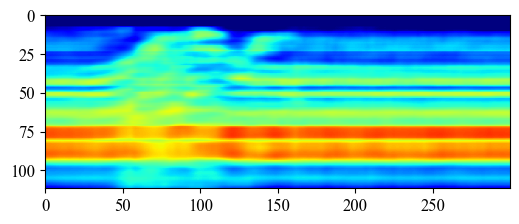

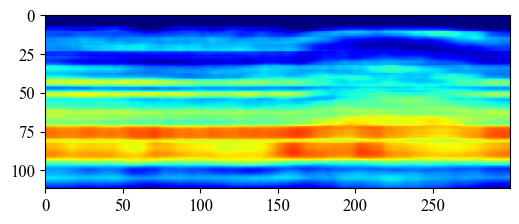

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 541 Loss:  -7.502685070037842 model_loss:  1081743.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 542 Loss:  -6.272184371948242 model_loss:  1049138.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 543 Loss:  -6.3193769454956055 model_loss:  1045249.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 549 Loss:  -7.2824788093566895 model_loss:  1077053.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 550 Loss:  -7.562592029571533 model_loss:  1092677.5


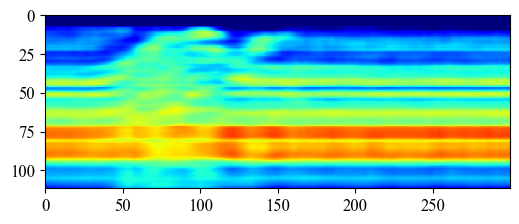

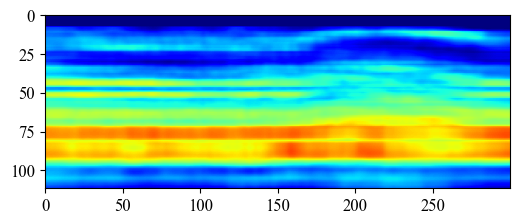

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 551 Loss:  -7.9882330894470215 model_loss:  1084513.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 552 Loss:  -7.832402229309082 model_loss:  1074313.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 553 Loss:  -7.30681848526001 model_loss:  1084855.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 559 Loss:  -7.064548492431641 model_loss:  1055290.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 560 Loss:  -8.14393138885498 model_loss:  1068765.1


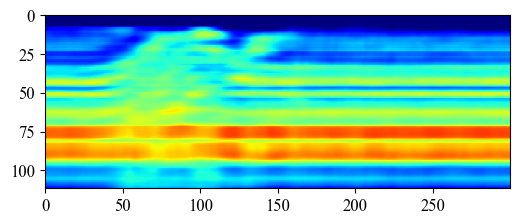

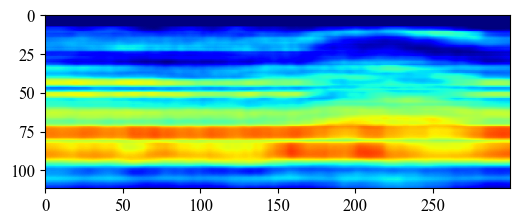

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 561 Loss:  -8.092588424682617 model_loss:  1067366.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 562 Loss:  -7.308131217956543 model_loss:  1048775.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 563 Loss:  -8.063057899475098 model_loss:  1059509.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 569 Loss:  -8.092863082885742 model_loss:  1042717.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 570 Loss:  -7.502645969390869 model_loss:  1056325.0


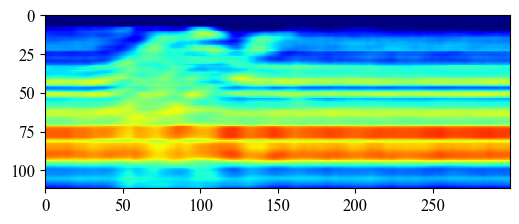

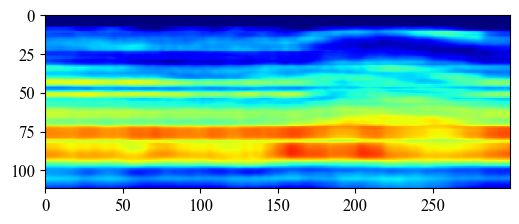

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 571 Loss:  -8.008309364318848 model_loss:  1041675.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 572 Loss:  -7.999104976654053 model_loss:  1041945.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 573 Loss:  -7.396190166473389 model_loss:  1057667.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 579 Loss:  -7.913303375244141 model_loss:  1037104.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 580 Loss:  -7.69347620010376 model_loss:  1046997.2


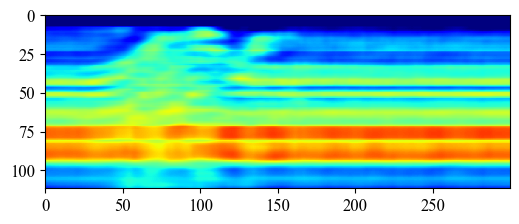

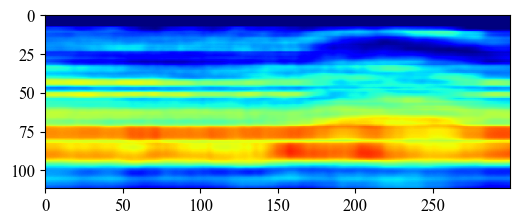

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 581 Loss:  -8.11778450012207 model_loss:  1035386.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 582 Loss:  -8.154825210571289 model_loss:  1033527.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 583 Loss:  -8.053543090820312 model_loss:  1032672.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 589 Loss:  -7.60174560546875 model_loss:  1034030.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 590 Loss:  -7.8804826736450195 model_loss:  1022253.0


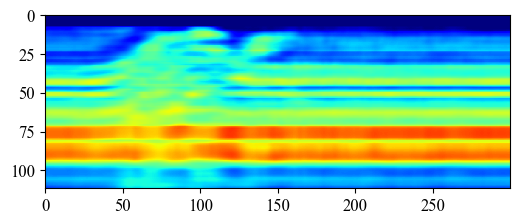

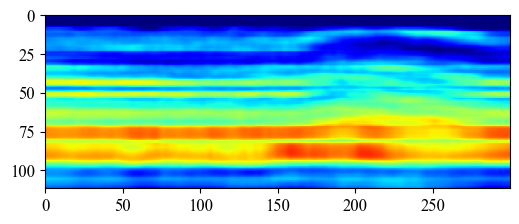

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 591 Loss:  -7.658463478088379 model_loss:  1020742.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 592 Loss:  -8.00153923034668 model_loss:  1034329.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 593 Loss:  -8.16411304473877 model_loss:  1023378.7


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 599 Loss:  -8.101033210754395 model_loss:  999528.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 600 Loss:  -7.850064754486084 model_loss:  994547.8


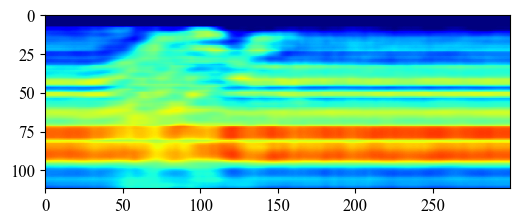

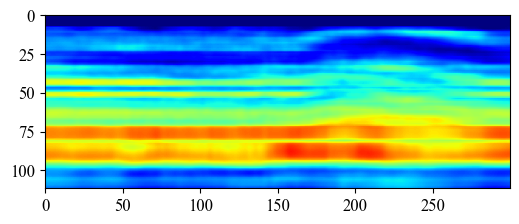

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 601 Loss:  -7.505838394165039 model_loss:  1011352.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 602 Loss:  -8.099364280700684 model_loss:  1004433.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 603 Loss:  -7.495718955993652 model_loss:  997622.25


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 609 Loss:  -7.697134971618652 model_loss:  975531.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 610 Loss:  -7.9639716148376465 model_loss:  982222.75


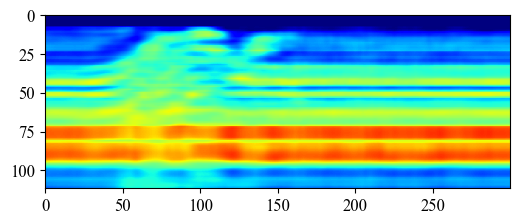

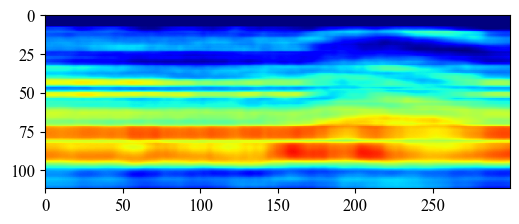

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 611 Loss:  -8.116891860961914 model_loss:  981819.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 612 Loss:  -7.528937339782715 model_loss:  970901.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 613 Loss:  -7.800908088684082 model_loss:  977293.94


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 619 Loss:  -7.803094387054443 model_loss:  969496.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 620 Loss:  -8.344756126403809 model_loss:  966281.8


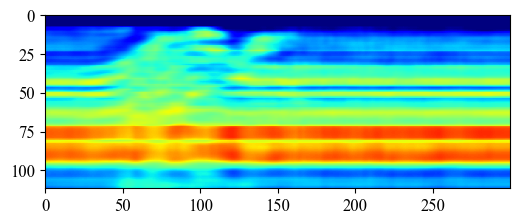

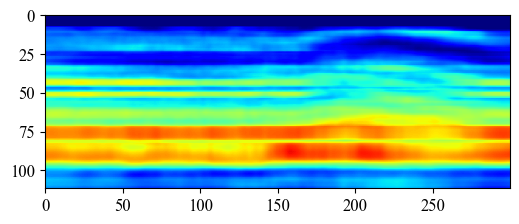

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 621 Loss:  -7.904202938079834 model_loss:  961194.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 622 Loss:  -7.892728805541992 model_loss:  967932.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 623 Loss:  -8.374553680419922 model_loss:  961625.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 629 Loss:  -8.391694068908691 model_loss:  952232.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 630 Loss:  -8.376728057861328 model_loss:  951764.1


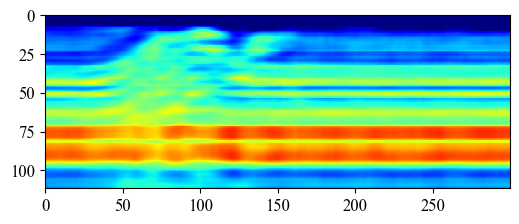

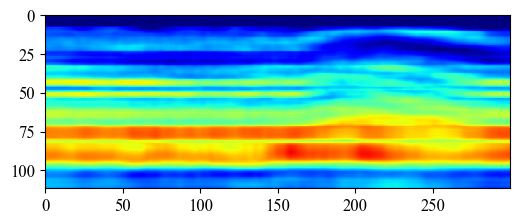

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 631 Loss:  -8.434828758239746 model_loss:  949123.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 632 Loss:  -8.401266098022461 model_loss:  948093.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 633 Loss:  -8.440230369567871 model_loss:  950471.75


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 639 Loss:  -8.556093215942383 model_loss:  921626.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 640 Loss:  -8.360739707946777 model_loss:  917496.6


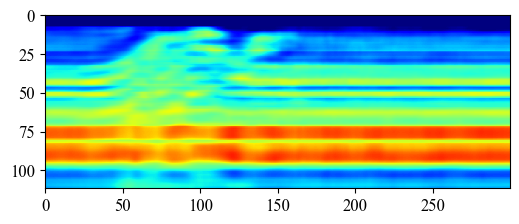

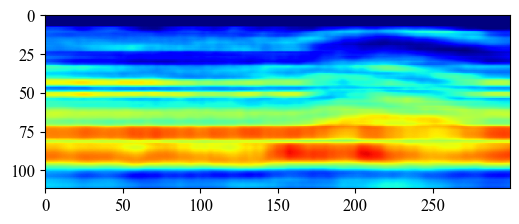

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 641 Loss:  -8.453243255615234 model_loss:  922622.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 642 Loss:  -8.450812339782715 model_loss:  920578.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 643 Loss:  -8.10798454284668 model_loss:  925773.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 649 Loss:  -8.351248741149902 model_loss:  907738.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 650 Loss:  -8.141246795654297 model_loss:  898045.94


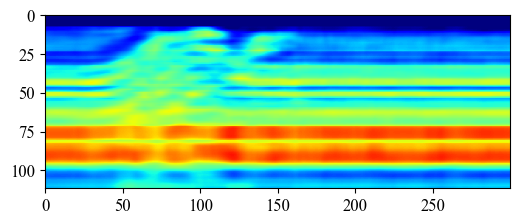

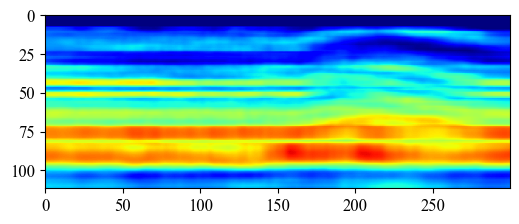

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 651 Loss:  -8.317328453063965 model_loss:  902697.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 652 Loss:  -8.533839225769043 model_loss:  894260.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 653 Loss:  -8.468311309814453 model_loss:  888889.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 659 Loss:  -8.579930305480957 model_loss:  878801.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 660 Loss:  -8.419681549072266 model_loss:  874830.06


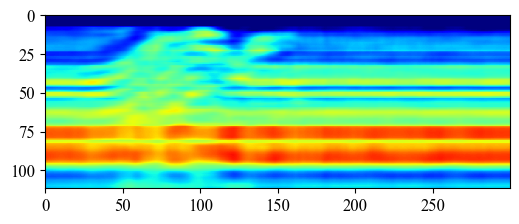

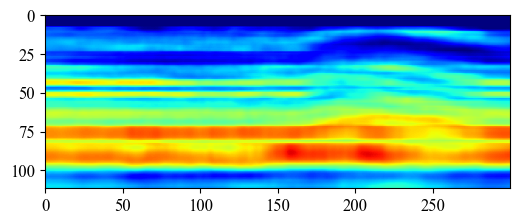

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 661 Loss:  -8.2392578125 model_loss:  878631.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 662 Loss:  -8.387938499450684 model_loss:  872524.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 663 Loss:  -8.321310043334961 model_loss:  877943.06


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 669 Loss:  -8.187914848327637 model_loss:  862300.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 670 Loss:  -8.44222640991211 model_loss:  863652.25


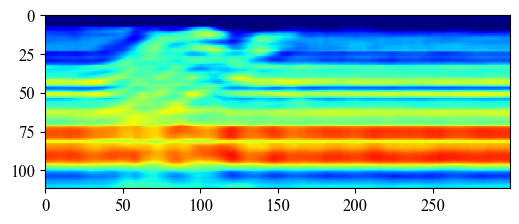

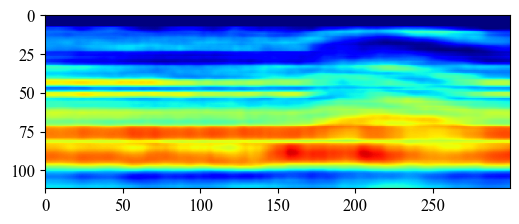

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 671 Loss:  -8.514145851135254 model_loss:  853251.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 672 Loss:  -8.58244800567627 model_loss:  848526.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 673 Loss:  -8.216103553771973 model_loss:  850297.94


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 679 Loss:  -7.979855537414551 model_loss:  848290.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 680 Loss:  -8.020224571228027 model_loss:  834023.75


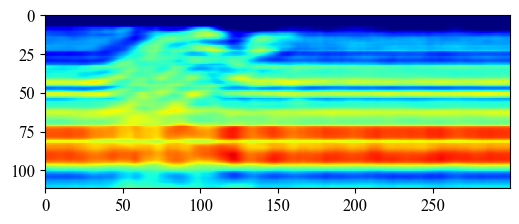

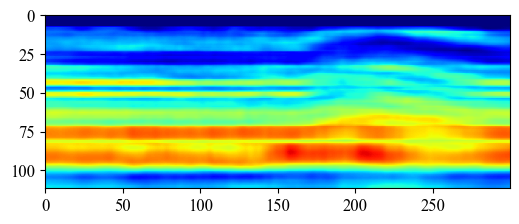

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 681 Loss:  -8.331464767456055 model_loss:  831647.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 682 Loss:  -8.177571296691895 model_loss:  834971.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 683 Loss:  -8.126638412475586 model_loss:  826631.7


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 689 Loss:  -8.142485618591309 model_loss:  830131.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 690 Loss:  -8.245384216308594 model_loss:  831006.44


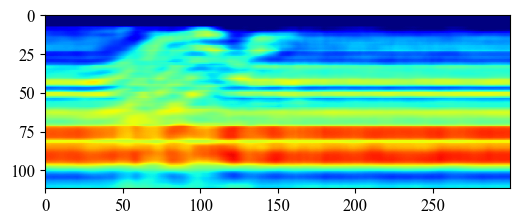

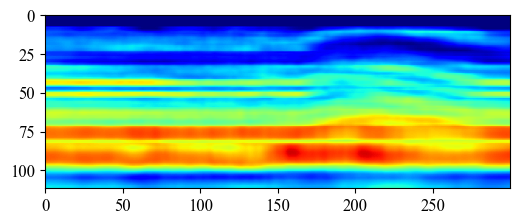

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 691 Loss:  -8.56243896484375 model_loss:  827142.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 692 Loss:  -8.378020286560059 model_loss:  828371.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 693 Loss:  -8.415573120117188 model_loss:  829289.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 699 Loss:  -8.034382820129395 model_loss:  823632.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 700 Loss:  -7.768314361572266 model_loss:  827235.3


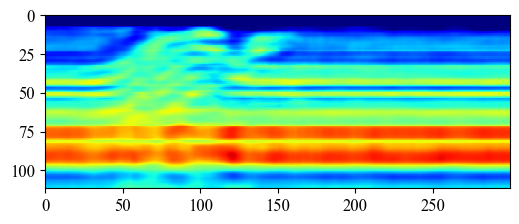

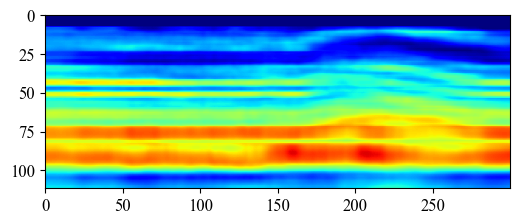

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 701 Loss:  -8.208629608154297 model_loss:  821932.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 702 Loss:  -7.478828430175781 model_loss:  816716.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 703 Loss:  -8.092194557189941 model_loss:  825181.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 709 Loss:  -6.85284423828125 model_loss:  833306.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 710 Loss:  -6.5267229080200195 model_loss:  842278.7


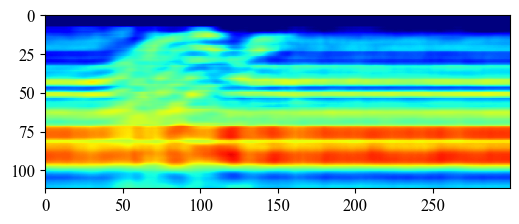

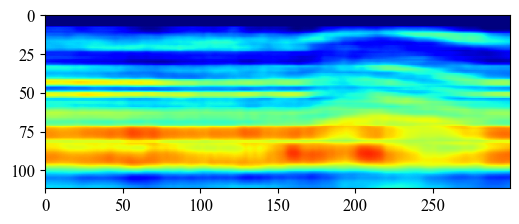

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 711 Loss:  -7.317881107330322 model_loss:  838661.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 712 Loss:  -6.546635150909424 model_loss:  831581.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 713 Loss:  -7.566511631011963 model_loss:  840298.56


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 719 Loss:  -7.4467926025390625 model_loss:  842304.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 720 Loss:  -6.755147933959961 model_loss:  836558.06


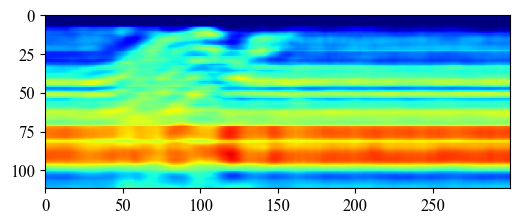

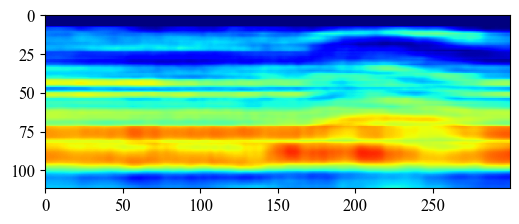

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 721 Loss:  -8.032685279846191 model_loss:  847100.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 722 Loss:  -6.887330055236816 model_loss:  864274.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 723 Loss:  -8.080751419067383 model_loss:  863672.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 729 Loss:  -8.232610702514648 model_loss:  869252.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 730 Loss:  -7.077749252319336 model_loss:  861728.5


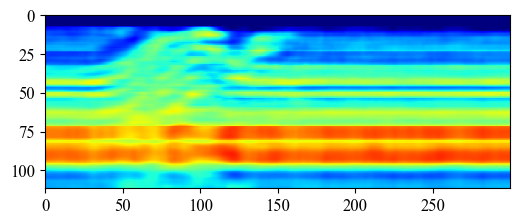

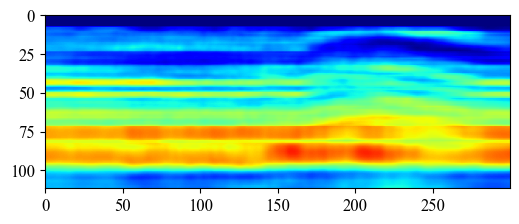

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 731 Loss:  -8.054969787597656 model_loss:  870277.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 732 Loss:  -7.7223663330078125 model_loss:  875632.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 733 Loss:  -7.426280975341797 model_loss:  868950.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 739 Loss:  -7.858462333679199 model_loss:  874682.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 740 Loss:  -8.068807601928711 model_loss:  874801.2


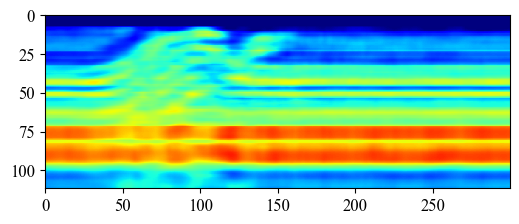

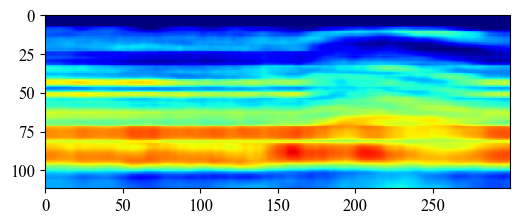

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 741 Loss:  -8.236038208007812 model_loss:  872727.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 742 Loss:  -7.752704620361328 model_loss:  864635.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 743 Loss:  -8.144174575805664 model_loss:  866628.94


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 749 Loss:  -8.110376358032227 model_loss:  870120.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 750 Loss:  -8.274277687072754 model_loss:  867538.6


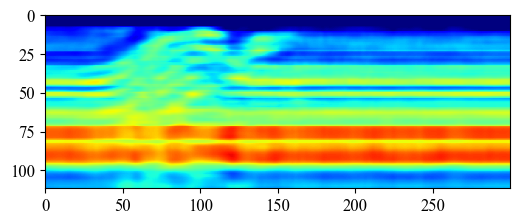

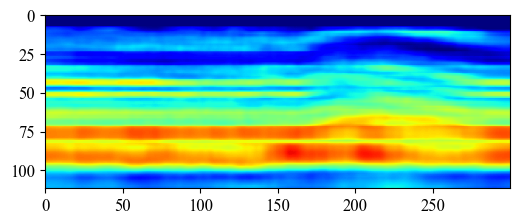

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 751 Loss:  -7.873294830322266 model_loss:  856659.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 752 Loss:  -7.943379878997803 model_loss:  859070.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 753 Loss:  -8.29062271118164 model_loss:  852808.75


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 759 Loss:  -8.222990989685059 model_loss:  846772.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 760 Loss:  -8.174749374389648 model_loss:  841925.8


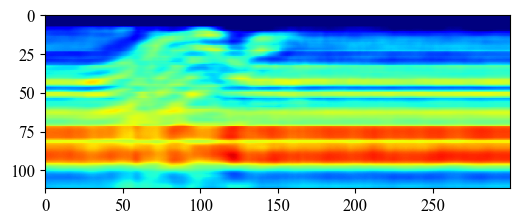

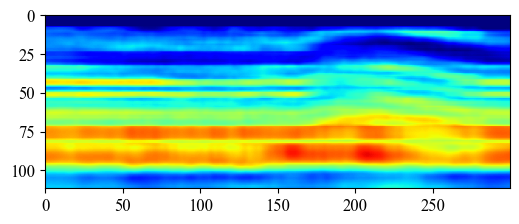

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 761 Loss:  -8.306330680847168 model_loss:  845065.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 762 Loss:  -8.356964111328125 model_loss:  839411.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 763 Loss:  -8.570974349975586 model_loss:  837322.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 769 Loss:  -8.471601486206055 model_loss:  824768.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 770 Loss:  -8.603327751159668 model_loss:  828306.0


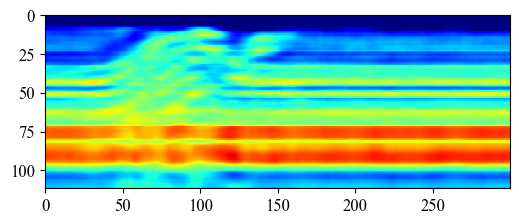

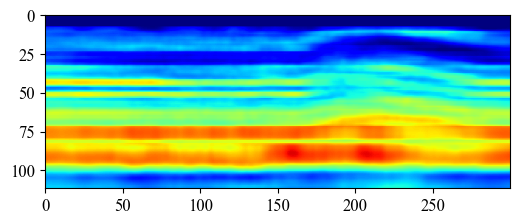

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 771 Loss:  -8.533429145812988 model_loss:  827044.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 772 Loss:  -8.673885345458984 model_loss:  830764.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 773 Loss:  -8.666427612304688 model_loss:  826621.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 779 Loss:  -8.519035339355469 model_loss:  810230.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 780 Loss:  -8.224748611450195 model_loss:  803443.56


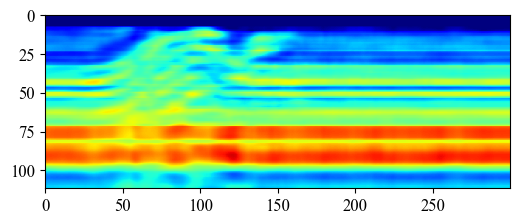

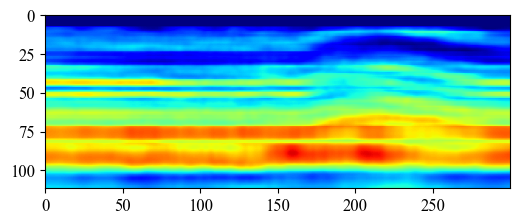

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 781 Loss:  -8.650218963623047 model_loss:  807707.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 782 Loss:  -8.762701034545898 model_loss:  804987.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 783 Loss:  -8.554354667663574 model_loss:  800900.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 789 Loss:  -8.775372505187988 model_loss:  797469.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 790 Loss:  -8.646251678466797 model_loss:  791629.06


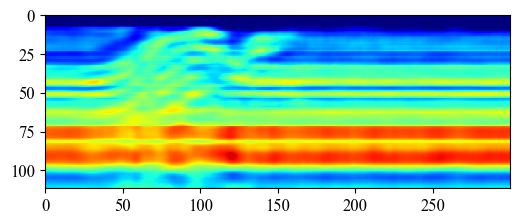

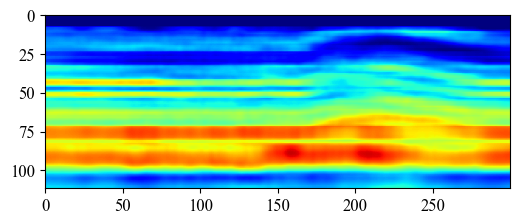

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 791 Loss:  -8.432856559753418 model_loss:  793940.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 792 Loss:  -8.33963680267334 model_loss:  785083.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 793 Loss:  -8.658293724060059 model_loss:  786973.7


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 799 Loss:  -8.754690170288086 model_loss:  783290.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 800 Loss:  -8.497042655944824 model_loss:  781403.4


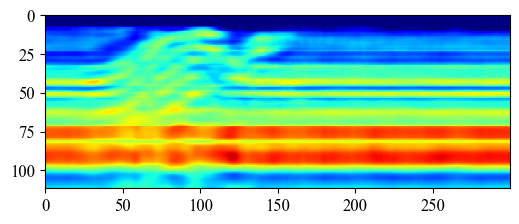

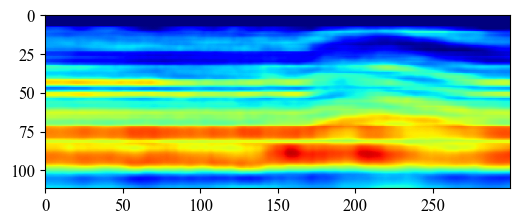

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 801 Loss:  -8.320362091064453 model_loss:  787360.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 802 Loss:  -8.693726539611816 model_loss:  781481.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 803 Loss:  -8.755605697631836 model_loss:  780060.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 809 Loss:  -8.4067964553833 model_loss:  783179.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 810 Loss:  -8.755866050720215 model_loss:  777143.44


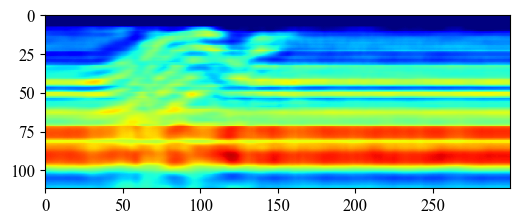

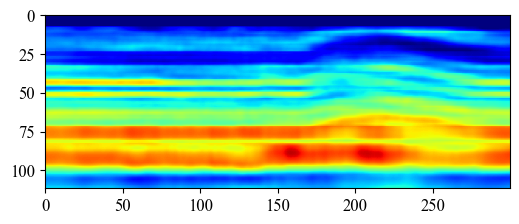

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 811 Loss:  -8.767839431762695 model_loss:  774155.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 812 Loss:  -8.819887161254883 model_loss:  770518.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 813 Loss:  -8.799056053161621 model_loss:  767993.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 819 Loss:  -8.828357696533203 model_loss:  768316.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 820 Loss:  -8.773249626159668 model_loss:  765346.1


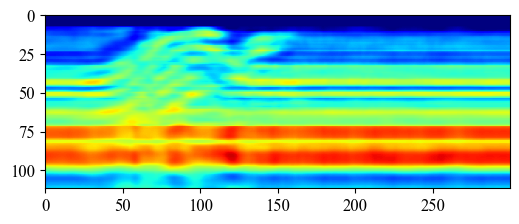

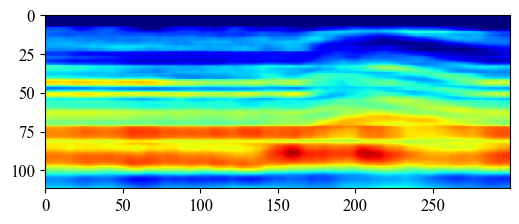

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 821 Loss:  -8.599874496459961 model_loss:  765992.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 822 Loss:  -8.48338508605957 model_loss:  759532.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 823 Loss:  -8.636000633239746 model_loss:  763673.25


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 829 Loss:  -8.739208221435547 model_loss:  757464.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 830 Loss:  -8.854430198669434 model_loss:  757191.8


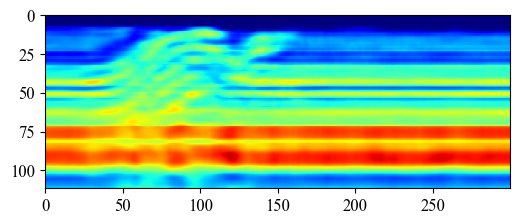

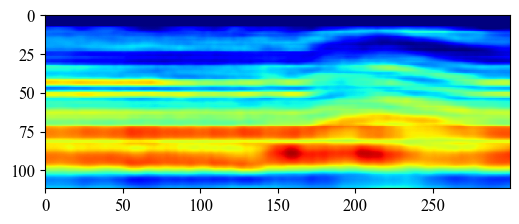

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 831 Loss:  -8.834024429321289 model_loss:  756090.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 832 Loss:  -8.67624568939209 model_loss:  752596.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 833 Loss:  -8.312620162963867 model_loss:  757997.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 839 Loss:  -8.592482566833496 model_loss:  747481.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 840 Loss:  -8.66130256652832 model_loss:  748719.7


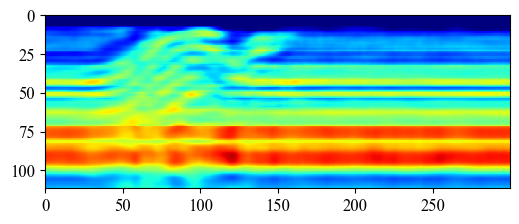

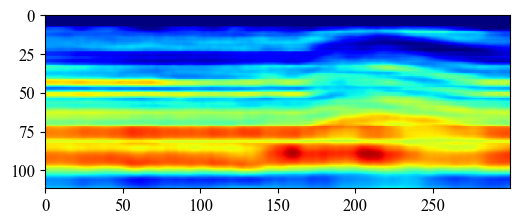

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 841 Loss:  -8.237325668334961 model_loss:  744361.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 842 Loss:  -8.64879035949707 model_loss:  748894.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 843 Loss:  -8.581098556518555 model_loss:  749951.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 849 Loss:  -8.307544708251953 model_loss:  747874.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 850 Loss:  -8.64854907989502 model_loss:  744299.75


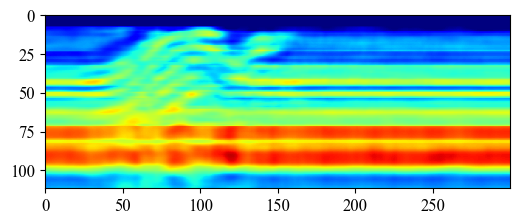

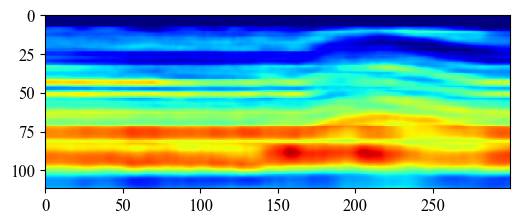

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 851 Loss:  -8.420815467834473 model_loss:  744398.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 852 Loss:  -8.339792251586914 model_loss:  753205.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 853 Loss:  -8.681452751159668 model_loss:  750534.94


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 859 Loss:  -8.420595169067383 model_loss:  748585.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 860 Loss:  -8.279611587524414 model_loss:  741425.44


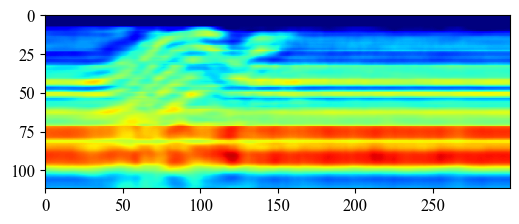

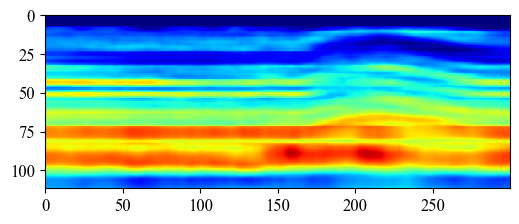

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 861 Loss:  -8.539938926696777 model_loss:  743196.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 862 Loss:  -8.338974952697754 model_loss:  747918.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 863 Loss:  -8.60543155670166 model_loss:  745495.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 869 Loss:  -8.741365432739258 model_loss:  749347.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 870 Loss:  -8.329988479614258 model_loss:  744429.25


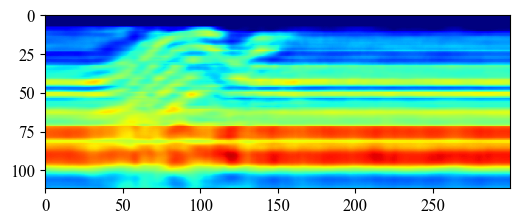

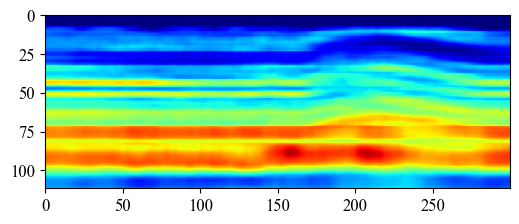

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 871 Loss:  -8.4315824508667 model_loss:  747036.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 872 Loss:  -8.626002311706543 model_loss:  742897.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 873 Loss:  -8.117972373962402 model_loss:  736005.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 879 Loss:  -8.641074180603027 model_loss:  739684.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 880 Loss:  -8.720296859741211 model_loss:  740812.8


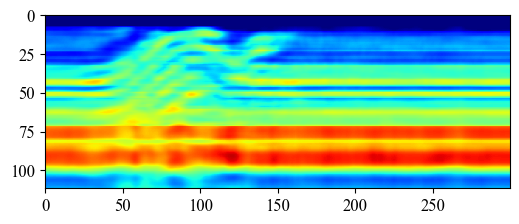

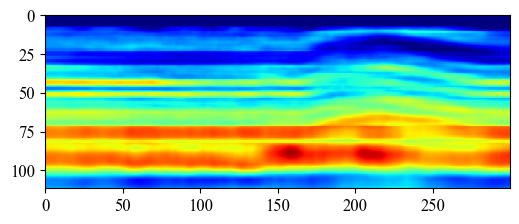

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 881 Loss:  -8.785293579101562 model_loss:  740148.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 882 Loss:  -8.62746810913086 model_loss:  735686.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 883 Loss:  -8.580711364746094 model_loss:  738075.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 889 Loss:  -8.839179039001465 model_loss:  732653.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 890 Loss:  -8.879602432250977 model_loss:  732229.06


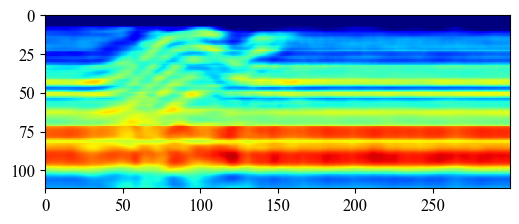

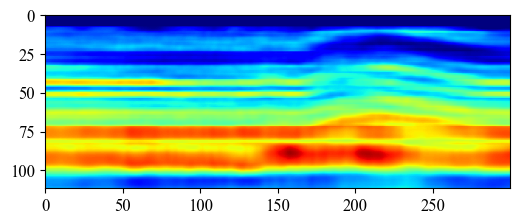

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 891 Loss:  -8.676318168640137 model_loss:  729753.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 892 Loss:  -8.61833381652832 model_loss:  733447.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 893 Loss:  -8.757730484008789 model_loss:  727429.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 899 Loss:  -8.397510528564453 model_loss:  725508.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 900 Loss:  -8.81489372253418 model_loss:  727247.4


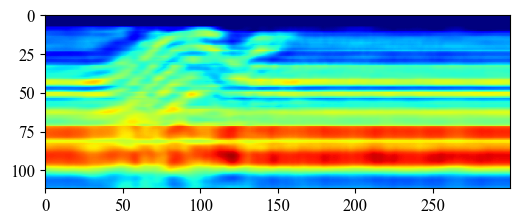

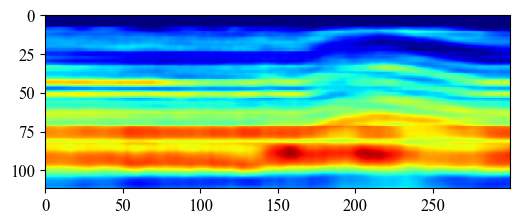

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 901 Loss:  -8.513038635253906 model_loss:  728529.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 902 Loss:  -8.533803939819336 model_loss:  722563.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 903 Loss:  -8.801716804504395 model_loss:  722353.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 909 Loss:  -8.486516952514648 model_loss:  719266.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 910 Loss:  -8.572122573852539 model_loss:  724051.25


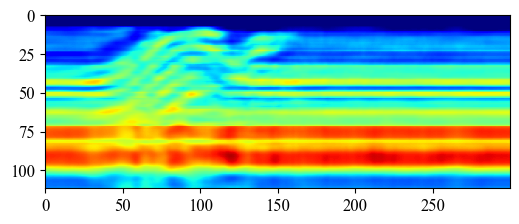

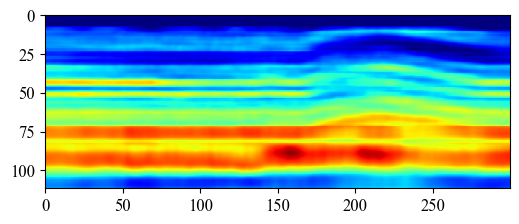

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 911 Loss:  -8.780470848083496 model_loss:  720808.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 912 Loss:  -8.557117462158203 model_loss:  714173.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 913 Loss:  -8.540749549865723 model_loss:  714884.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 919 Loss:  -8.576088905334473 model_loss:  710015.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 920 Loss:  -8.739959716796875 model_loss:  711074.75


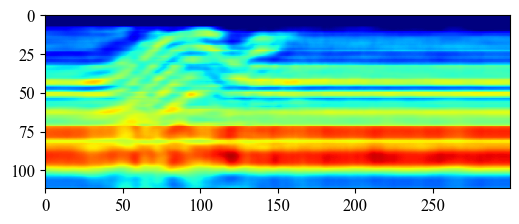

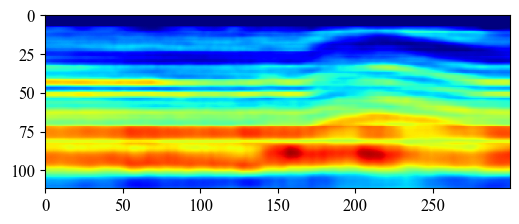

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 921 Loss:  -8.33250617980957 model_loss:  708957.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 922 Loss:  -8.567310333251953 model_loss:  712997.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 923 Loss:  -8.616254806518555 model_loss:  715023.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 929 Loss:  -8.911214828491211 model_loss:  711073.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 930 Loss:  -8.811813354492188 model_loss:  710548.2


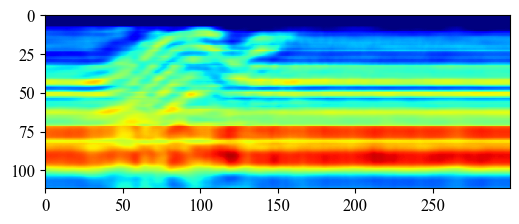

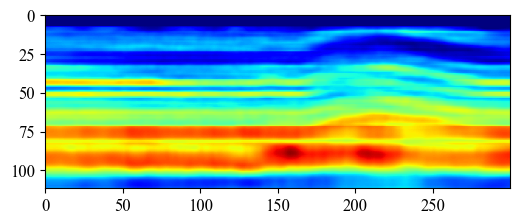

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 931 Loss:  -8.643942832946777 model_loss:  713744.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 932 Loss:  -8.674880027770996 model_loss:  710797.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 933 Loss:  -8.835531234741211 model_loss:  712403.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 939 Loss:  -8.558274269104004 model_loss:  707152.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 940 Loss:  -8.840142250061035 model_loss:  705555.9


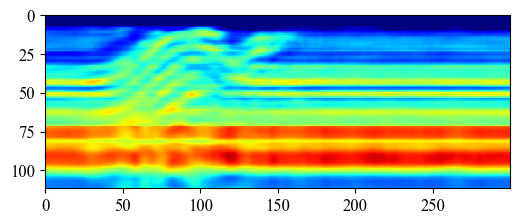

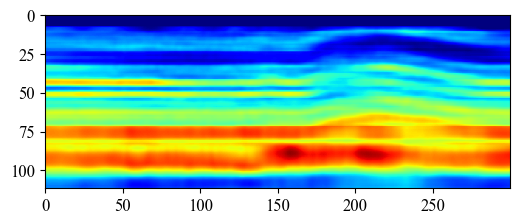

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 941 Loss:  -8.883599281311035 model_loss:  702964.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 942 Loss:  -8.783529281616211 model_loss:  701363.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 943 Loss:  -8.795491218566895 model_loss:  696627.06


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 949 Loss:  -8.896661758422852 model_loss:  698014.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 950 Loss:  -8.676484107971191 model_loss:  699470.4


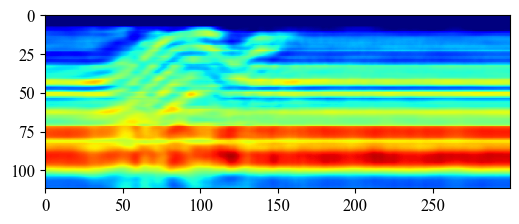

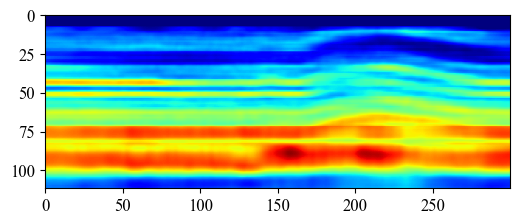

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 951 Loss:  -8.379301071166992 model_loss:  691928.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 952 Loss:  -8.854248046875 model_loss:  690632.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 953 Loss:  -8.470130920410156 model_loss:  689575.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 959 Loss:  -8.586141586303711 model_loss:  689041.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 960 Loss:  -8.748310089111328 model_loss:  683749.56


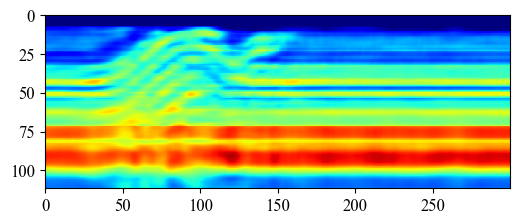

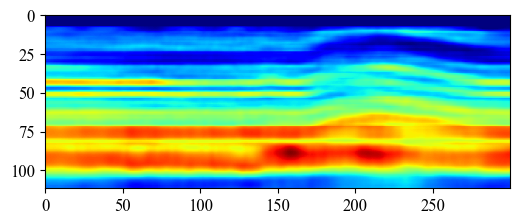

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 961 Loss:  -8.836462020874023 model_loss:  683685.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 962 Loss:  -8.830053329467773 model_loss:  684346.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 963 Loss:  -8.377705574035645 model_loss:  679405.7


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 969 Loss:  -8.408059120178223 model_loss:  681118.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 970 Loss:  -8.821572303771973 model_loss:  683935.44


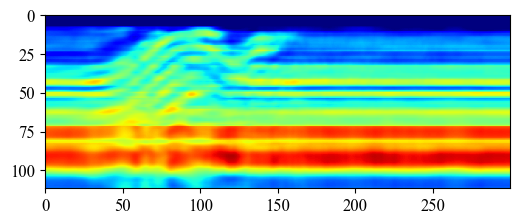

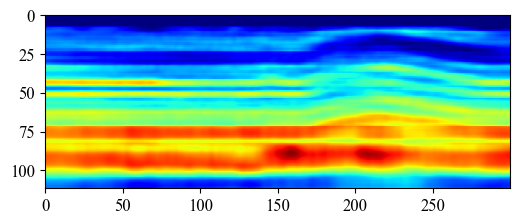

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 971 Loss:  -8.709782600402832 model_loss:  682009.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 972 Loss:  -8.372913360595703 model_loss:  672873.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 973 Loss:  -8.855386734008789 model_loss:  672252.44


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 979 Loss:  -8.940707206726074 model_loss:  667560.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 980 Loss:  -8.496297836303711 model_loss:  667501.7


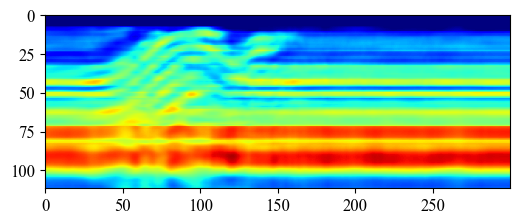

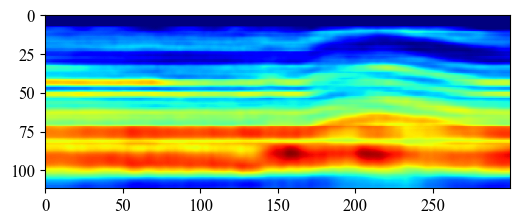

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 981 Loss:  -8.716286659240723 model_loss:  661327.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 982 Loss:  -8.915950775146484 model_loss:  661374.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 983 Loss:  -8.842342376708984 model_loss:  662951.25


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 989 Loss:  -8.974452018737793 model_loss:  658530.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 990 Loss:  -9.008844375610352 model_loss:  657731.44


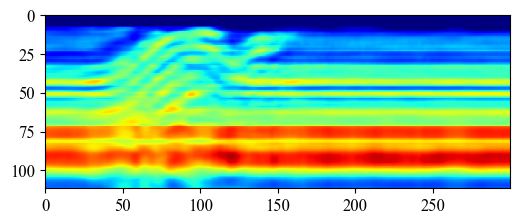

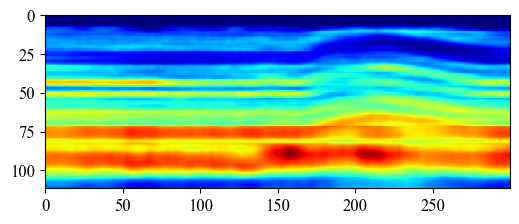

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 991 Loss:  -8.978321075439453 model_loss:  658225.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 992 Loss:  -8.811539649963379 model_loss:  656730.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 993 Loss:  -8.7328519821167 model_loss:  661242.56


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 999 Loss:  -8.948171615600586 model_loss:  644329.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1000 Loss:  -8.997013092041016 model_loss:  643434.9


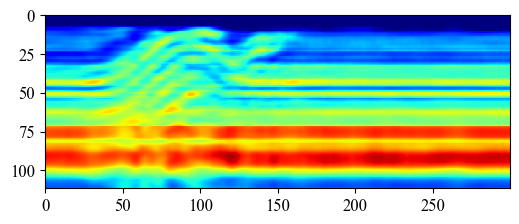

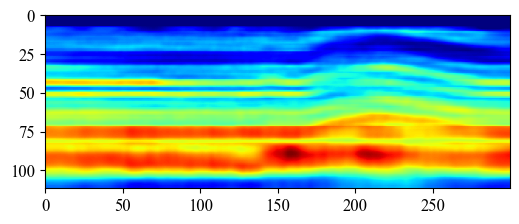

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1001 Loss:  -8.932487487792969 model_loss:  643428.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1002 Loss:  -8.966626167297363 model_loss:  639616.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1003 Loss:  -8.999488830566406 model_loss:  639223.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1009 Loss:  -9.085153579711914 model_loss:  622896.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1010 Loss:  -9.046998977661133 model_loss:  624187.7


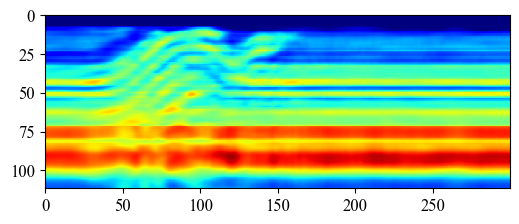

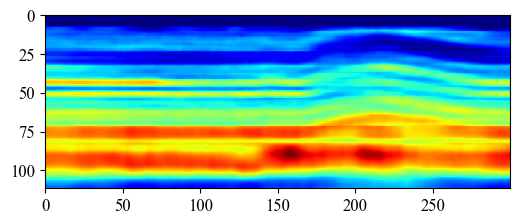

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1011 Loss:  -8.997404098510742 model_loss:  621174.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1012 Loss:  -9.073370933532715 model_loss:  620485.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1013 Loss:  -9.097622871398926 model_loss:  616640.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1019 Loss:  -9.085004806518555 model_loss:  601279.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1020 Loss:  -9.148427963256836 model_loss:  599457.25


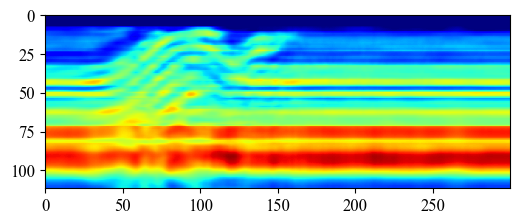

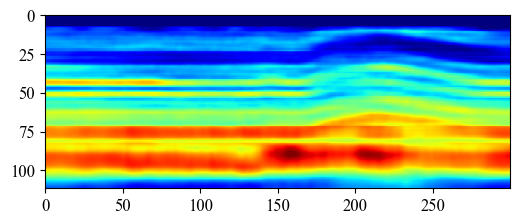

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1021 Loss:  -9.0086030960083 model_loss:  596257.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1022 Loss:  -8.873483657836914 model_loss:  595517.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1023 Loss:  -9.082748413085938 model_loss:  589897.25


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1029 Loss:  -9.024412155151367 model_loss:  575403.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1030 Loss:  -9.053703308105469 model_loss:  571715.44


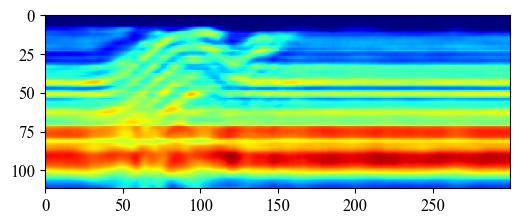

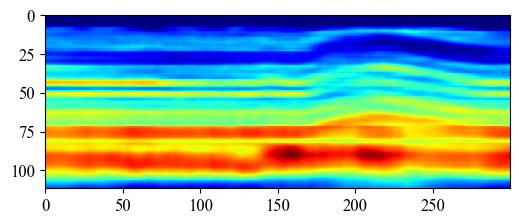

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1031 Loss:  -8.861603736877441 model_loss:  569668.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1032 Loss:  -9.03856372833252 model_loss:  564659.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1033 Loss:  -9.084217071533203 model_loss:  562891.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1039 Loss:  -9.125591278076172 model_loss:  559744.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1040 Loss:  -9.10958194732666 model_loss:  557297.9


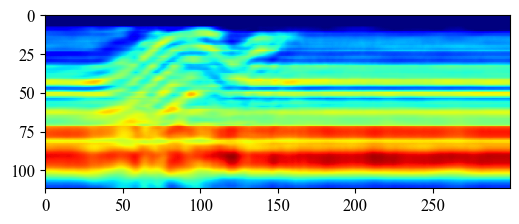

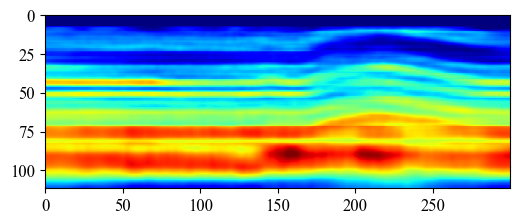

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1041 Loss:  -9.053539276123047 model_loss:  554385.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1042 Loss:  -9.068065643310547 model_loss:  553714.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1043 Loss:  -9.083410263061523 model_loss:  551861.56


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1049 Loss:  -9.063230514526367 model_loss:  546047.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1050 Loss:  -9.149559020996094 model_loss:  542468.6


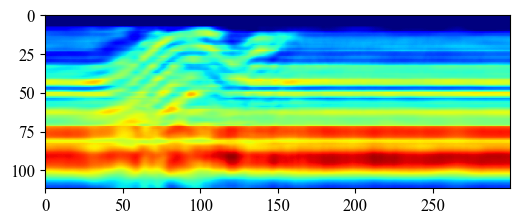

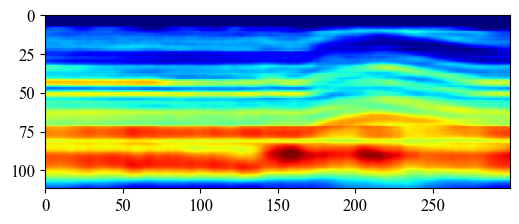

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1051 Loss:  -9.12051773071289 model_loss:  541109.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1052 Loss:  -9.01309871673584 model_loss:  538871.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1053 Loss:  -8.939106941223145 model_loss:  540171.7


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1059 Loss:  -9.164663314819336 model_loss:  523973.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1060 Loss:  -9.184115409851074 model_loss:  522463.44


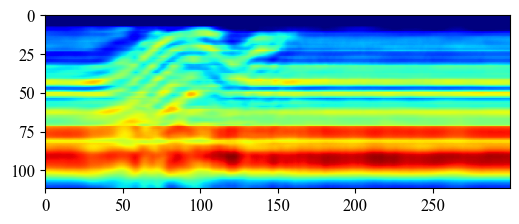

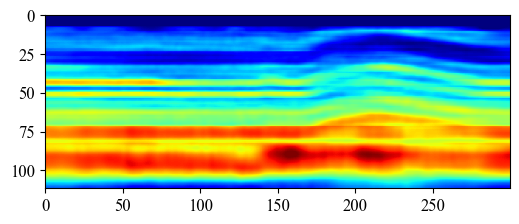

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1061 Loss:  -9.066446304321289 model_loss:  522371.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1062 Loss:  -8.965517044067383 model_loss:  519278.12


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1063 Loss:  -9.092864036560059 model_loss:  518125.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1069 Loss:  -9.093485832214355 model_loss:  505023.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1070 Loss:  -9.13929557800293 model_loss:  504458.16


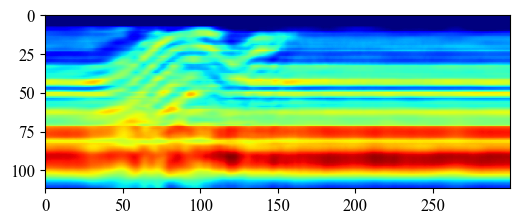

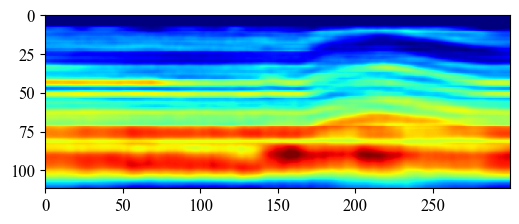

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1071 Loss:  -9.175525665283203 model_loss:  502472.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1072 Loss:  -9.145391464233398 model_loss:  502716.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1073 Loss:  -9.060502052307129 model_loss:  500871.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1079 Loss:  -9.034488677978516 model_loss:  488520.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1080 Loss:  -9.146974563598633 model_loss:  487040.66


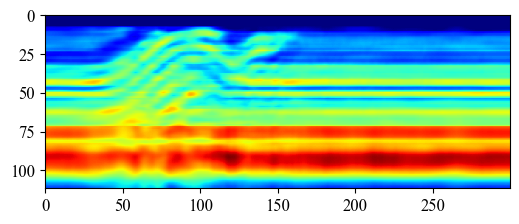

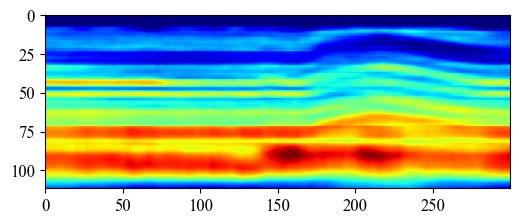

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1081 Loss:  -9.182098388671875 model_loss:  483092.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1082 Loss:  -9.201882362365723 model_loss:  480926.84


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1083 Loss:  -9.2044095993042 model_loss:  479875.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1089 Loss:  -9.157296180725098 model_loss:  476237.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1090 Loss:  -9.220817565917969 model_loss:  476659.97


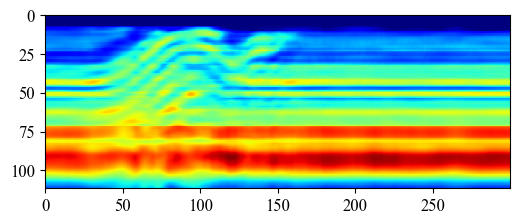

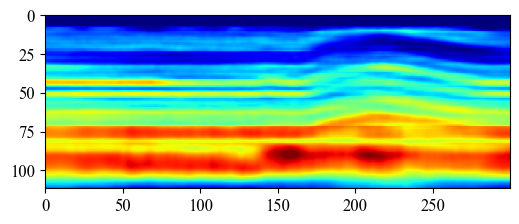

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1091 Loss:  -9.209368705749512 model_loss:  475826.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1092 Loss:  -9.238832473754883 model_loss:  473122.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1093 Loss:  -9.199344635009766 model_loss:  468988.88


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1099 Loss:  -9.21557331085205 model_loss:  464550.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1100 Loss:  -9.20968246459961 model_loss:  462105.06


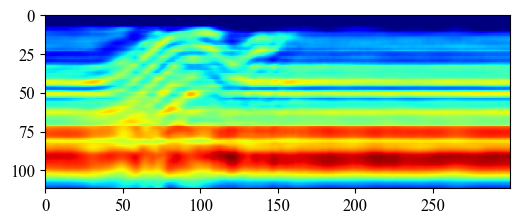

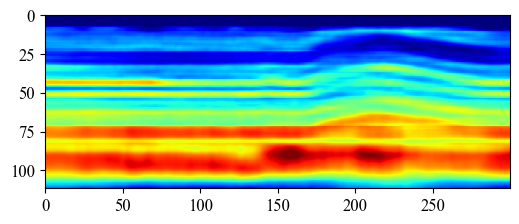

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1101 Loss:  -9.235269546508789 model_loss:  459106.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1102 Loss:  -9.160673141479492 model_loss:  455307.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1103 Loss:  -9.038335800170898 model_loss:  454613.03


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1109 Loss:  -9.034212112426758 model_loss:  451534.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1110 Loss:  -9.1771240234375 model_loss:  449867.03


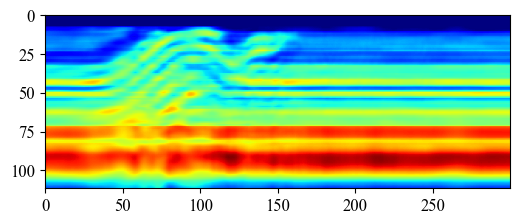

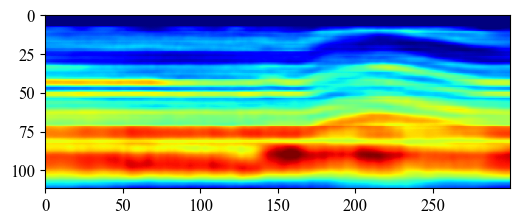

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1111 Loss:  -9.135978698730469 model_loss:  448210.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1112 Loss:  -8.9476318359375 model_loss:  447055.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1113 Loss:  -9.058477401733398 model_loss:  448148.53


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.89s/it]


Epoch: 1119 Loss:  -9.098922729492188 model_loss:  437377.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1120 Loss:  -8.86415958404541 model_loss:  437896.47


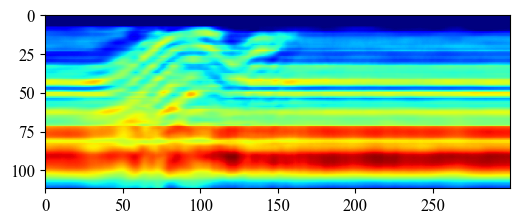

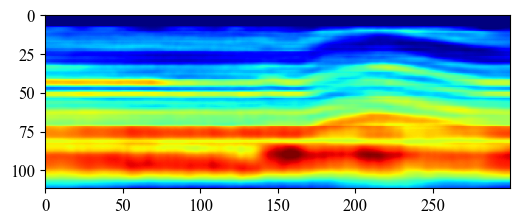

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1121 Loss:  -9.136260032653809 model_loss:  440737.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1122 Loss:  -9.143386840820312 model_loss:  442742.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1123 Loss:  -8.861502647399902 model_loss:  443594.03


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1129 Loss:  -9.111698150634766 model_loss:  438247.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1130 Loss:  -9.015375137329102 model_loss:  439006.56


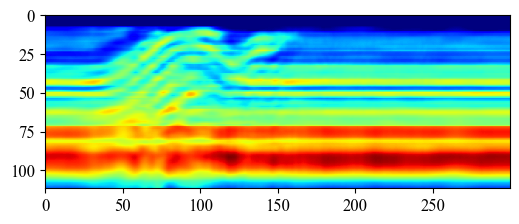

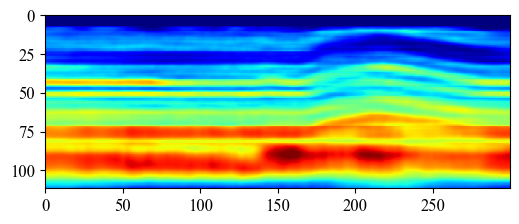

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1131 Loss:  -9.047300338745117 model_loss:  439353.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1132 Loss:  -9.156830787658691 model_loss:  440037.62


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1133 Loss:  -9.227117538452148 model_loss:  439021.66


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1139 Loss:  -9.204008102416992 model_loss:  433310.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1140 Loss:  -9.174379348754883 model_loss:  432585.0


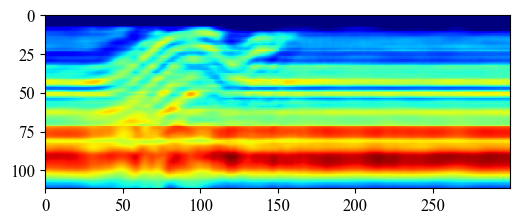

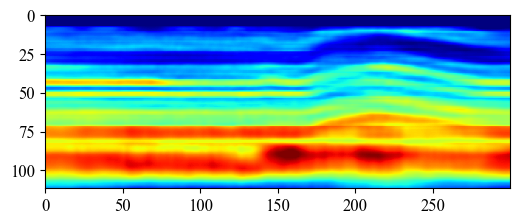

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1141 Loss:  -8.93817138671875 model_loss:  430154.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1142 Loss:  -9.06747055053711 model_loss:  430377.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1143 Loss:  -9.215279579162598 model_loss:  430467.06


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1149 Loss:  -9.013070106506348 model_loss:  418974.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1150 Loss:  -8.999460220336914 model_loss:  419907.12


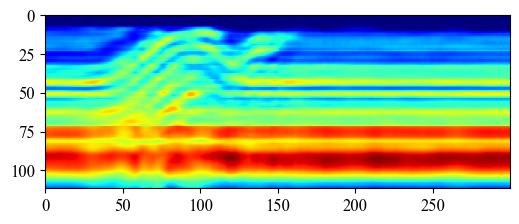

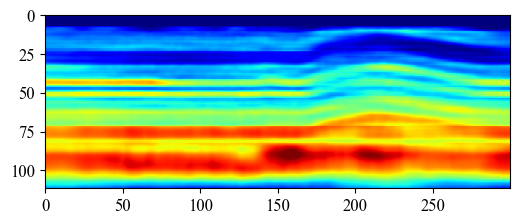

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1151 Loss:  -9.197059631347656 model_loss:  421235.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1152 Loss:  -9.1856050491333 model_loss:  421598.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1153 Loss:  -9.161762237548828 model_loss:  420348.28


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1159 Loss:  -9.114779472351074 model_loss:  417920.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1160 Loss:  -9.0457181930542 model_loss:  418417.12


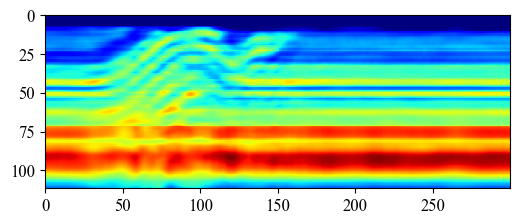

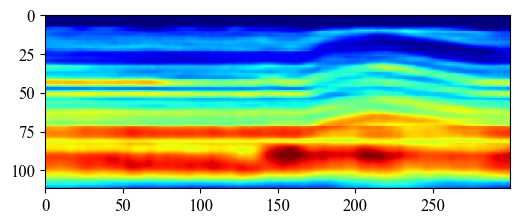

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1161 Loss:  -9.100000381469727 model_loss:  416744.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1162 Loss:  -9.142411231994629 model_loss:  416949.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1163 Loss:  -9.210325241088867 model_loss:  415914.56


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1169 Loss:  -9.214065551757812 model_loss:  410121.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1170 Loss:  -9.161377906799316 model_loss:  409765.7


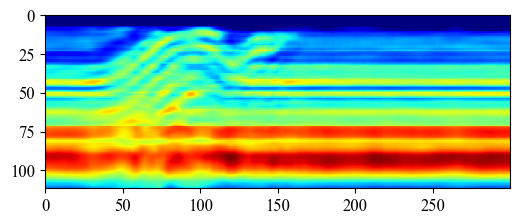

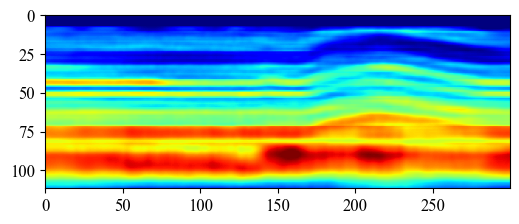

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1171 Loss:  -9.11841869354248 model_loss:  407394.47


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1172 Loss:  -9.056796073913574 model_loss:  404954.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1173 Loss:  -9.120911598205566 model_loss:  404011.84


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1179 Loss:  -9.111971855163574 model_loss:  399401.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1180 Loss:  -9.208200454711914 model_loss:  398401.1


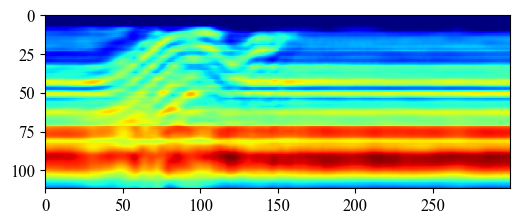

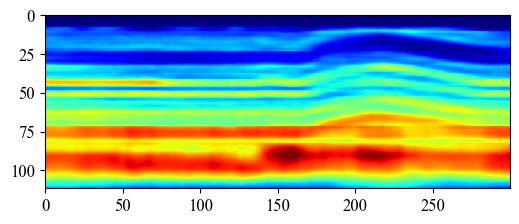

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1181 Loss:  -9.058948516845703 model_loss:  397266.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1182 Loss:  -8.976387977600098 model_loss:  397366.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1183 Loss:  -9.132143020629883 model_loss:  397402.3


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1189 Loss:  -8.997635841369629 model_loss:  390037.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1190 Loss:  -9.018930435180664 model_loss:  390344.88


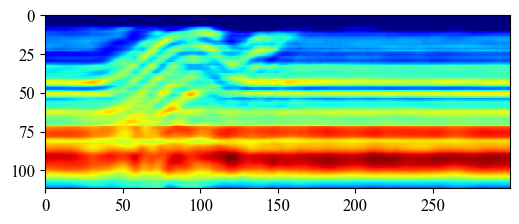

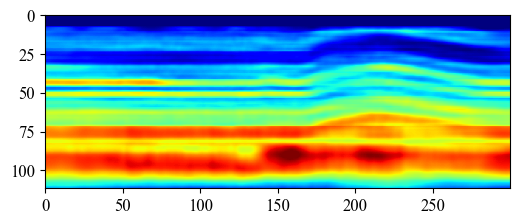

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1191 Loss:  -9.206869125366211 model_loss:  391264.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1192 Loss:  -9.163335800170898 model_loss:  391428.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1193 Loss:  -8.983603477478027 model_loss:  391167.12


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1199 Loss:  -9.141358375549316 model_loss:  383346.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1200 Loss:  -8.88245964050293 model_loss:  384236.47


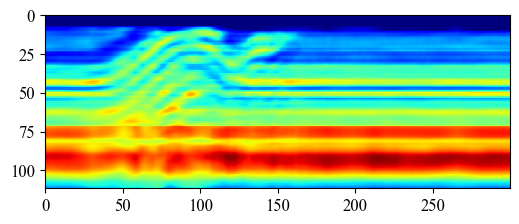

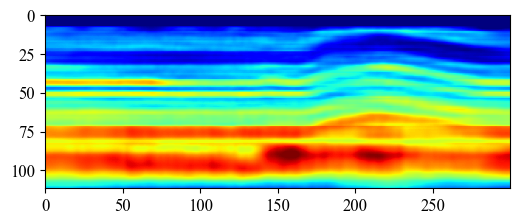

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1201 Loss:  -9.222681999206543 model_loss:  384762.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1202 Loss:  -9.146559715270996 model_loss:  385831.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1203 Loss:  -8.891936302185059 model_loss:  385454.66


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1209 Loss:  -9.202214241027832 model_loss:  382166.03


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1210 Loss:  -9.231167793273926 model_loss:  383807.1


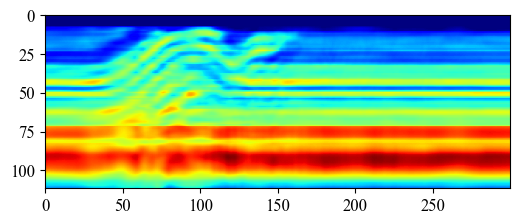

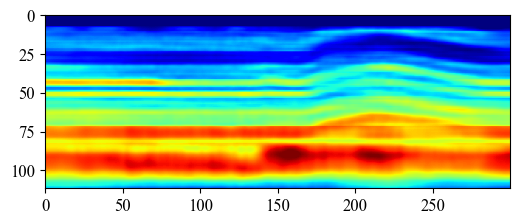

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1211 Loss:  -9.177606582641602 model_loss:  382968.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1212 Loss:  -8.997269630432129 model_loss:  381733.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1213 Loss:  -9.079935073852539 model_loss:  379864.4


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1219 Loss:  -9.16164493560791 model_loss:  373002.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1220 Loss:  -8.952600479125977 model_loss:  372555.97


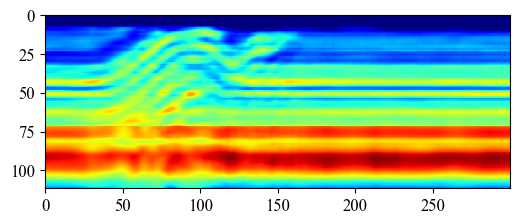

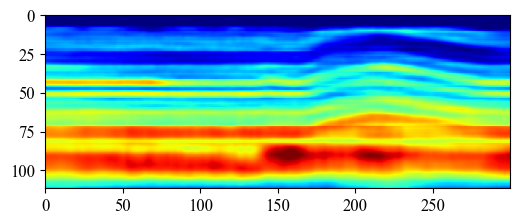

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1221 Loss:  -9.141589164733887 model_loss:  372728.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1222 Loss:  -9.212178230285645 model_loss:  372270.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1223 Loss:  -8.92056941986084 model_loss:  371500.84


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1229 Loss:  -9.101531982421875 model_loss:  369541.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1230 Loss:  -8.79427719116211 model_loss:  370219.06


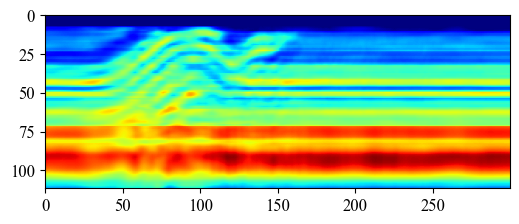

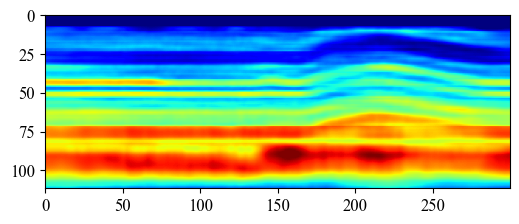

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1231 Loss:  -9.205828666687012 model_loss:  371985.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1232 Loss:  -8.88283920288086 model_loss:  373474.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1233 Loss:  -8.853901863098145 model_loss:  373867.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1239 Loss:  -9.23194694519043 model_loss:  368482.03


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1240 Loss:  -8.748544692993164 model_loss:  371535.97


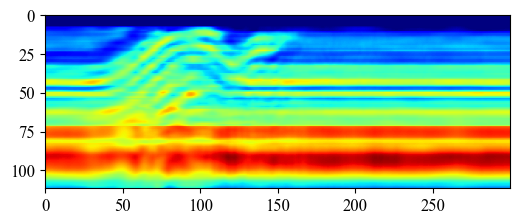

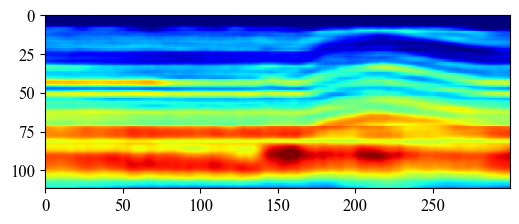

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1241 Loss:  -9.121546745300293 model_loss:  373269.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1242 Loss:  -9.045544624328613 model_loss:  372595.62


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1243 Loss:  -8.694548606872559 model_loss:  372277.62


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1249 Loss:  -9.040163040161133 model_loss:  370464.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1250 Loss:  -8.572956085205078 model_loss:  374707.94


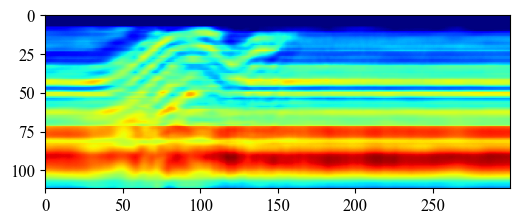

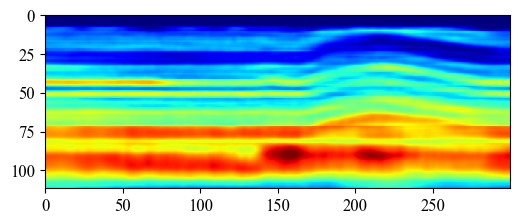

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1251 Loss:  -8.945384979248047 model_loss:  375242.38


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1252 Loss:  -8.542892456054688 model_loss:  373306.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1253 Loss:  -8.937567710876465 model_loss:  372668.03


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1259 Loss:  -8.615461349487305 model_loss:  375320.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1260 Loss:  -8.91331958770752 model_loss:  376449.4


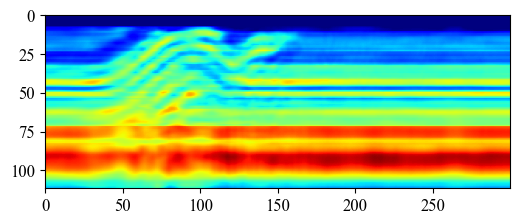

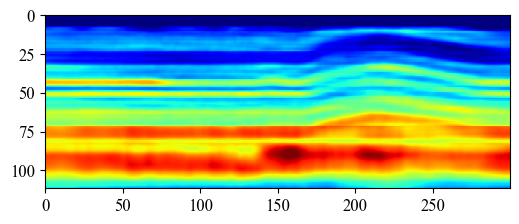

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1261 Loss:  -9.087628364562988 model_loss:  374784.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1262 Loss:  -8.745525360107422 model_loss:  371897.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1263 Loss:  -8.902901649475098 model_loss:  371853.34


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1269 Loss:  -8.635024070739746 model_loss:  376123.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1270 Loss:  -9.042276382446289 model_loss:  377819.7


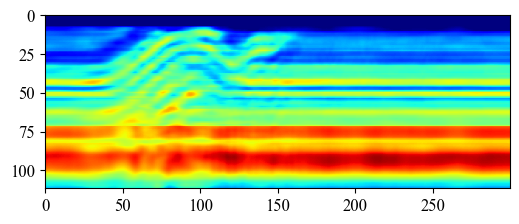

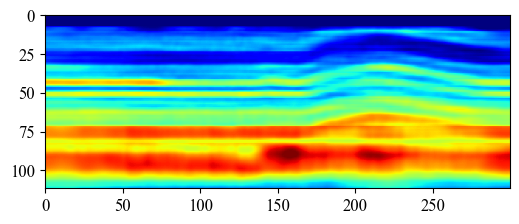

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1271 Loss:  -8.991850852966309 model_loss:  376351.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1272 Loss:  -8.787880897521973 model_loss:  373043.12


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1273 Loss:  -9.065557479858398 model_loss:  372225.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1279 Loss:  -8.993579864501953 model_loss:  382208.16


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1280 Loss:  -9.13011360168457 model_loss:  381769.8


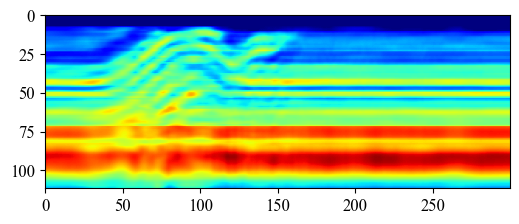

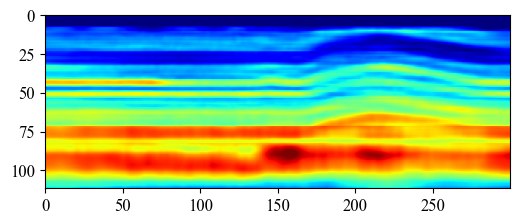

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1281 Loss:  -9.050888061523438 model_loss:  380539.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1282 Loss:  -8.97260856628418 model_loss:  379745.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1283 Loss:  -9.155145645141602 model_loss:  379239.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1289 Loss:  -9.235716819763184 model_loss:  382827.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1290 Loss:  -9.194328308105469 model_loss:  380431.2


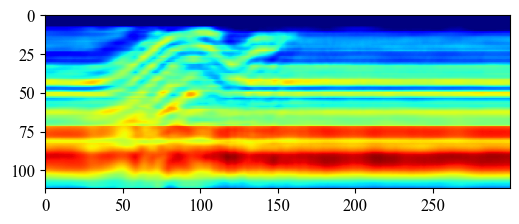

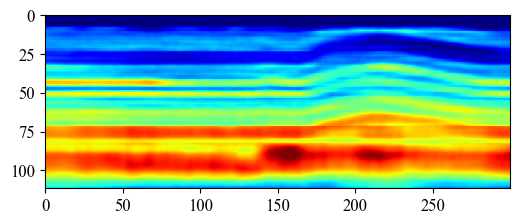

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1291 Loss:  -9.067824363708496 model_loss:  379331.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1292 Loss:  -9.011398315429688 model_loss:  377825.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1293 Loss:  -9.20967960357666 model_loss:  377110.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1299 Loss:  -9.246580123901367 model_loss:  382543.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1300 Loss:  -9.19652271270752 model_loss:  379722.88


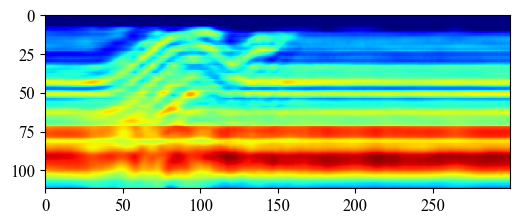

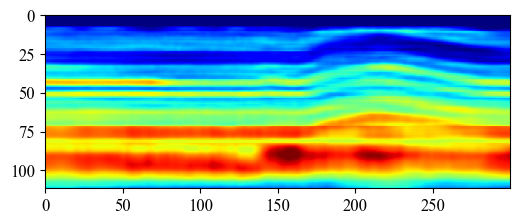

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1301 Loss:  -9.208208084106445 model_loss:  376127.84


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1302 Loss:  -9.238121032714844 model_loss:  373374.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1303 Loss:  -9.17021656036377 model_loss:  373906.6


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1309 Loss:  -9.276522636413574 model_loss:  370327.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1310 Loss:  -9.260879516601562 model_loss:  368841.2


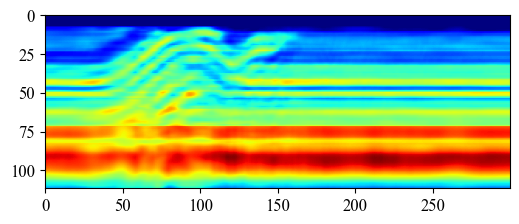

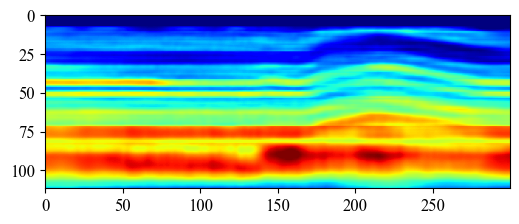

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1311 Loss:  -9.234464645385742 model_loss:  368627.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1312 Loss:  -9.103435516357422 model_loss:  368627.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1313 Loss:  -9.133611679077148 model_loss:  368282.53


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1319 Loss:  -9.24658203125 model_loss:  360793.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1320 Loss:  -9.29061508178711 model_loss:  360507.8


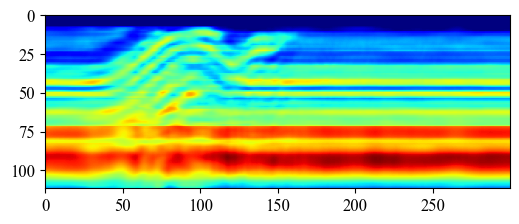

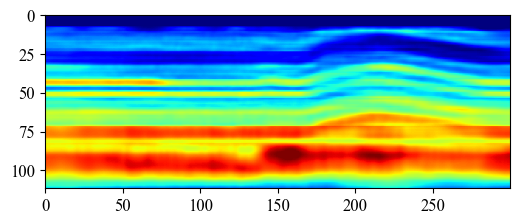

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1321 Loss:  -9.173456192016602 model_loss:  360384.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1322 Loss:  -9.07113265991211 model_loss:  360469.84


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1323 Loss:  -9.251590728759766 model_loss:  360188.72


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1329 Loss:  -9.196842193603516 model_loss:  356881.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1330 Loss:  -9.186527252197266 model_loss:  355461.25


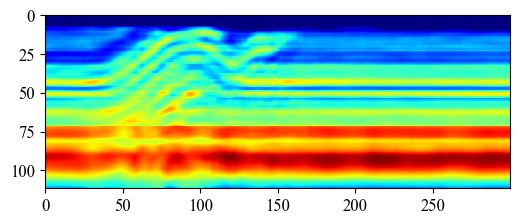

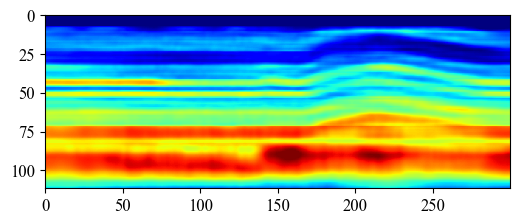

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1331 Loss:  -8.923407554626465 model_loss:  354945.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1332 Loss:  -9.232023239135742 model_loss:  354172.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1333 Loss:  -9.05219554901123 model_loss:  353805.66


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1339 Loss:  -8.900736808776855 model_loss:  351007.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1340 Loss:  -9.199141502380371 model_loss:  350224.03


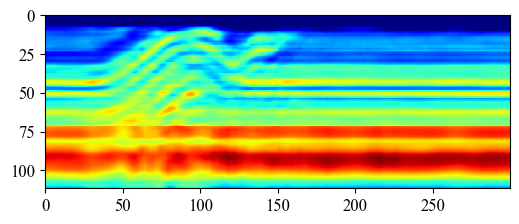

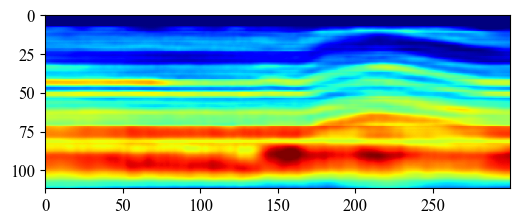

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1341 Loss:  -8.998777389526367 model_loss:  350020.22


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1342 Loss:  -8.965723991394043 model_loss:  349385.12


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1343 Loss:  -9.218280792236328 model_loss:  350495.75


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1349 Loss:  -8.85097599029541 model_loss:  347679.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1350 Loss:  -9.027231216430664 model_loss:  348791.62


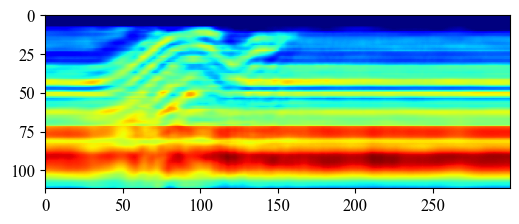

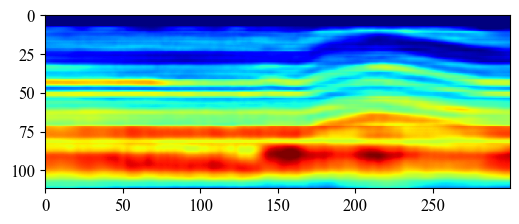

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1351 Loss:  -8.944703102111816 model_loss:  349030.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1352 Loss:  -8.950645446777344 model_loss:  346939.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1353 Loss:  -9.116809844970703 model_loss:  346429.03


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1359 Loss:  -9.122987747192383 model_loss:  343684.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1360 Loss:  -8.933968544006348 model_loss:  344678.06


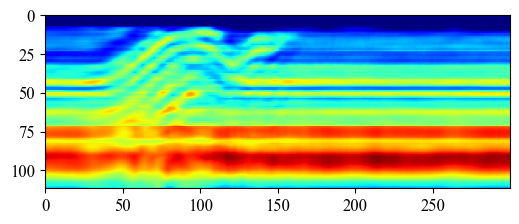

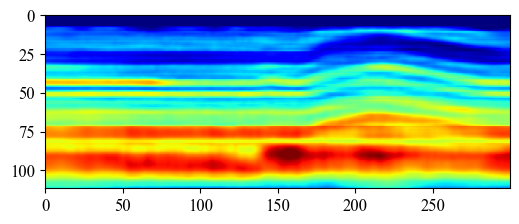

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1361 Loss:  -9.151985168457031 model_loss:  343957.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1362 Loss:  -9.16256046295166 model_loss:  343629.12


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1363 Loss:  -8.902998924255371 model_loss:  343909.62


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1369 Loss:  -8.856892585754395 model_loss:  345395.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1370 Loss:  -9.200249671936035 model_loss:  344993.84


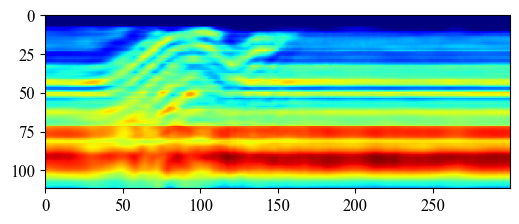

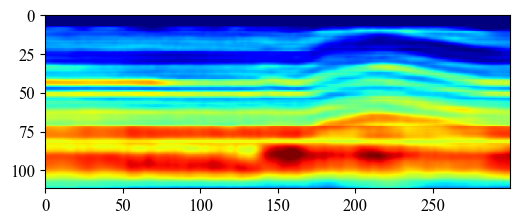

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1371 Loss:  -9.118562698364258 model_loss:  345605.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1372 Loss:  -8.81656551361084 model_loss:  346084.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1373 Loss:  -9.235822677612305 model_loss:  343592.75


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1379 Loss:  -9.221733093261719 model_loss:  345670.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1380 Loss:  -9.003880500793457 model_loss:  345539.5


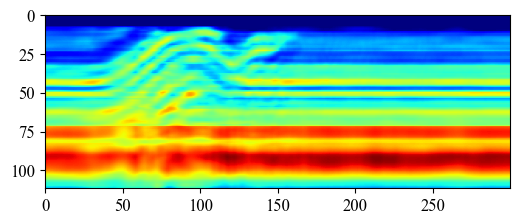

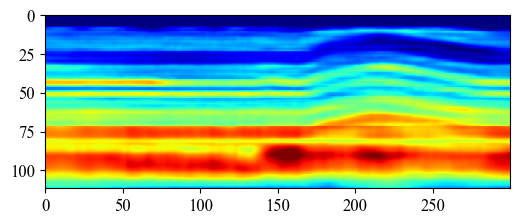

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1381 Loss:  -9.138644218444824 model_loss:  344910.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1382 Loss:  -9.260784149169922 model_loss:  342425.88


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1383 Loss:  -9.158600807189941 model_loss:  339065.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1389 Loss:  -9.309850692749023 model_loss:  335048.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1390 Loss:  -9.254287719726562 model_loss:  333445.38


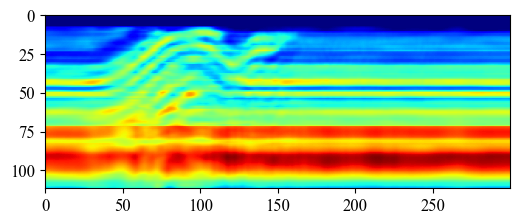

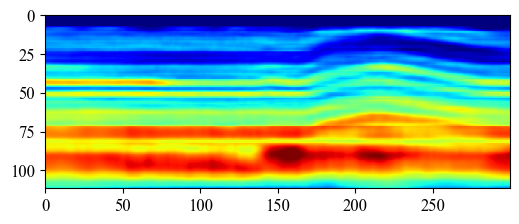

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1391 Loss:  -9.192944526672363 model_loss:  332238.38


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1392 Loss:  -9.141157150268555 model_loss:  332723.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1393 Loss:  -9.215973854064941 model_loss:  332244.34


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1399 Loss:  -9.27879524230957 model_loss:  330072.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1400 Loss:  -9.225769996643066 model_loss:  329828.9


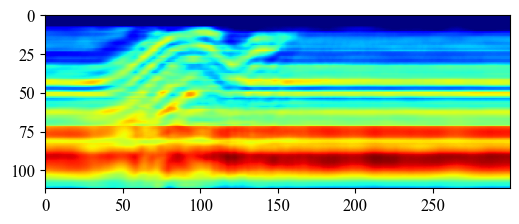

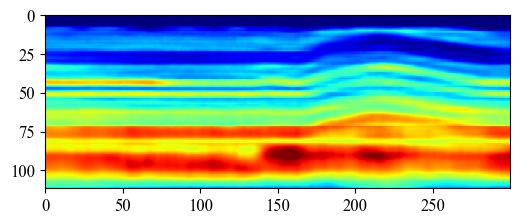

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1401 Loss:  -9.23677921295166 model_loss:  329032.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1402 Loss:  -9.312223434448242 model_loss:  329441.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1403 Loss:  -9.32843017578125 model_loss:  328658.66


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1409 Loss:  -9.33071231842041 model_loss:  320470.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1410 Loss:  -9.280906677246094 model_loss:  320470.75


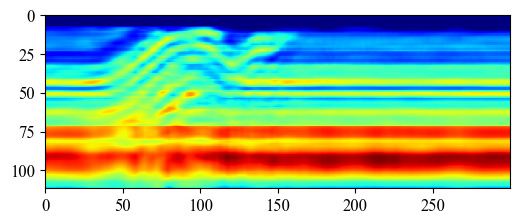

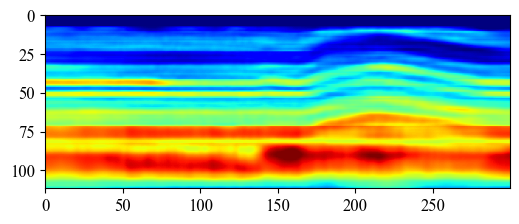

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1411 Loss:  -9.207365989685059 model_loss:  319869.16


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1412 Loss:  -9.193352699279785 model_loss:  320071.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1413 Loss:  -9.287871360778809 model_loss:  318765.97


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1419 Loss:  -9.184328079223633 model_loss:  314293.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1420 Loss:  -9.122284889221191 model_loss:  314589.97


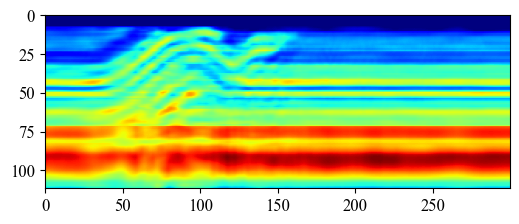

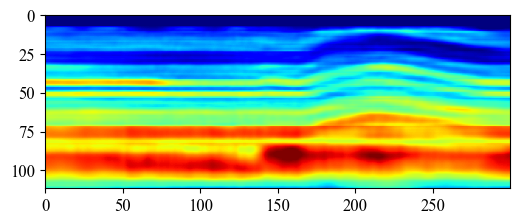

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1421 Loss:  -9.194754600524902 model_loss:  314549.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1422 Loss:  -9.242490768432617 model_loss:  314931.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1423 Loss:  -9.311328887939453 model_loss:  314080.62


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1429 Loss:  -9.30091667175293 model_loss:  306820.47


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1430 Loss:  -9.311738014221191 model_loss:  305696.75


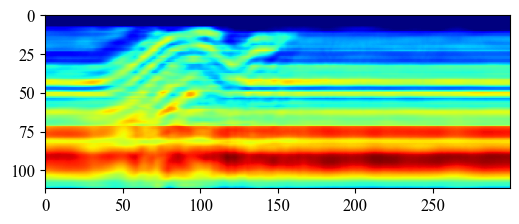

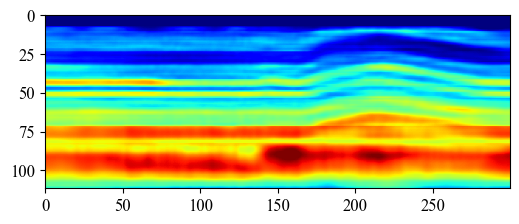

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1431 Loss:  -9.309292793273926 model_loss:  305291.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1432 Loss:  -9.302950859069824 model_loss:  303959.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1433 Loss:  -9.333968162536621 model_loss:  302903.16


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1439 Loss:  -9.235247611999512 model_loss:  295087.38


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1440 Loss:  -9.33028793334961 model_loss:  295242.62


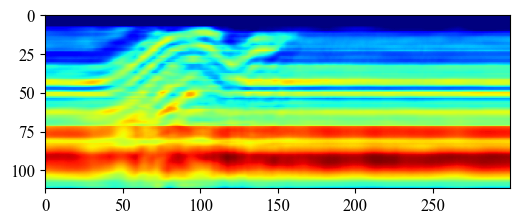

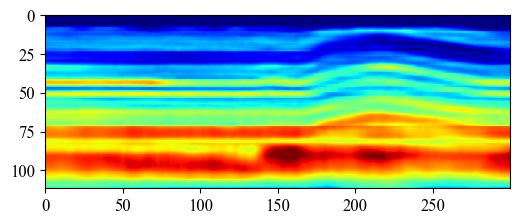

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1441 Loss:  -9.32385540008545 model_loss:  295136.16


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1442 Loss:  -9.344169616699219 model_loss:  294758.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1443 Loss:  -9.33273696899414 model_loss:  294033.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1449 Loss:  -9.37094783782959 model_loss:  290714.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1450 Loss:  -9.371753692626953 model_loss:  290220.9


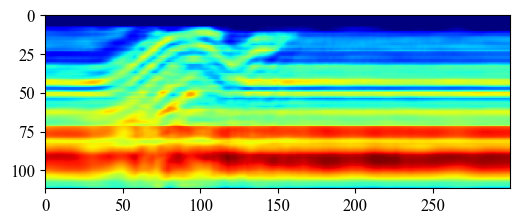

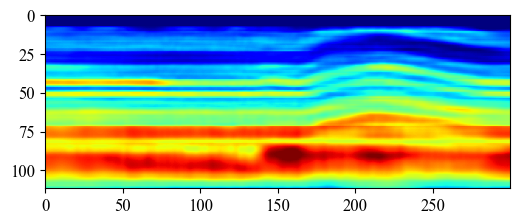

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1451 Loss:  -9.32604694366455 model_loss:  290251.94


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1452 Loss:  -9.30472469329834 model_loss:  288923.38


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1453 Loss:  -9.171923637390137 model_loss:  286492.03


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1459 Loss:  -9.289108276367188 model_loss:  285276.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1460 Loss:  -9.333456039428711 model_loss:  281847.2


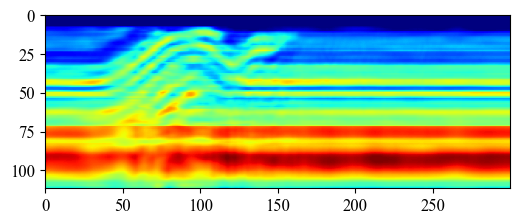

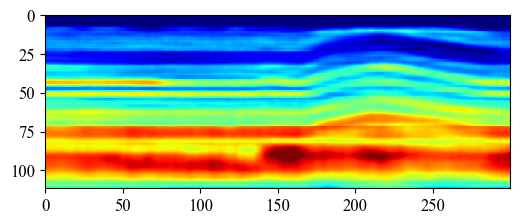

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1461 Loss:  -9.369007110595703 model_loss:  280636.38


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1462 Loss:  -9.288917541503906 model_loss:  279369.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1463 Loss:  -9.187959671020508 model_loss:  279286.44


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1469 Loss:  -9.316939353942871 model_loss:  276039.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1470 Loss:  -9.272252082824707 model_loss:  276042.3


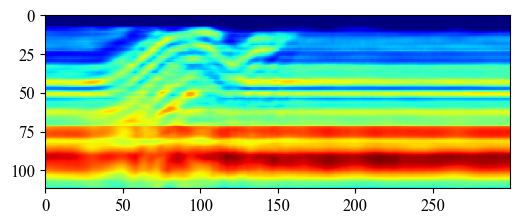

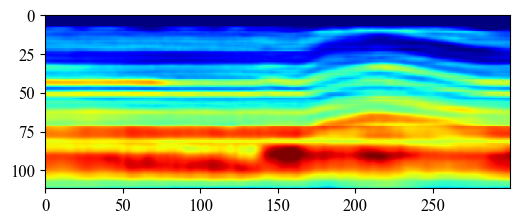

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1471 Loss:  -9.116955757141113 model_loss:  274552.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1472 Loss:  -9.22486400604248 model_loss:  275107.44


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1473 Loss:  -9.328007698059082 model_loss:  273737.88


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1479 Loss:  -9.203330993652344 model_loss:  266711.47


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1480 Loss:  -9.318338394165039 model_loss:  266875.12


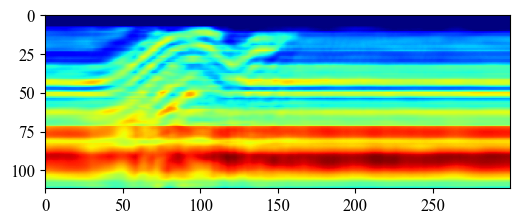

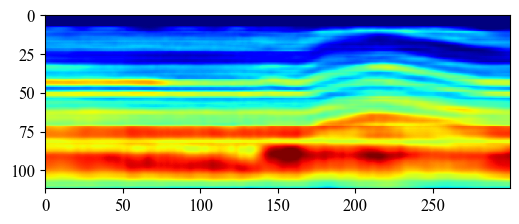

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1481 Loss:  -9.294501304626465 model_loss:  266744.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1482 Loss:  -9.205659866333008 model_loss:  266553.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1483 Loss:  -9.17558479309082 model_loss:  268497.88


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1489 Loss:  -9.225440979003906 model_loss:  262732.47


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1490 Loss:  -9.321914672851562 model_loss:  262975.3


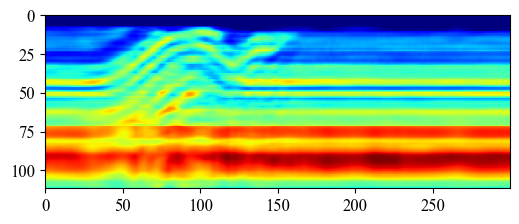

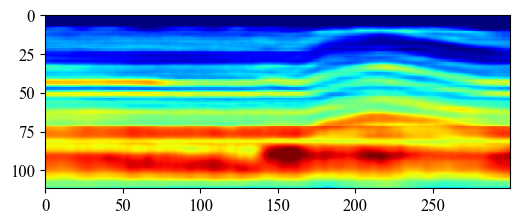

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1491 Loss:  -9.28999137878418 model_loss:  261912.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1492 Loss:  -9.278115272521973 model_loss:  261745.11


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1493 Loss:  -9.188138961791992 model_loss:  260068.69


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1499 Loss:  -9.25207233428955 model_loss:  251012.03


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1500 Loss:  -9.196356773376465 model_loss:  249545.98


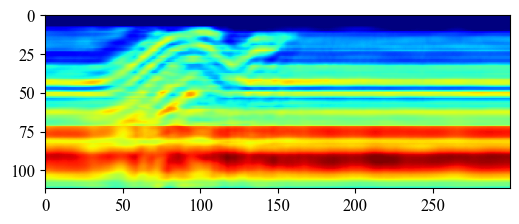

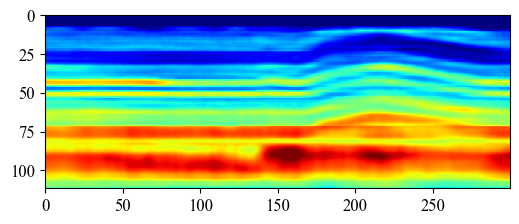

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1501 Loss:  -9.317781448364258 model_loss:  249877.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1502 Loss:  -9.307090759277344 model_loss:  250021.77


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1503 Loss:  -9.343669891357422 model_loss:  252536.89


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1509 Loss:  -9.357921600341797 model_loss:  248790.83


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1510 Loss:  -9.246633529663086 model_loss:  247868.47


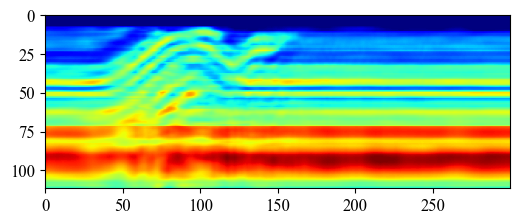

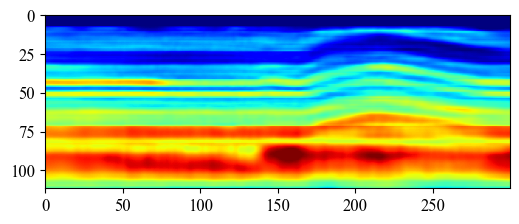

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1511 Loss:  -9.06749153137207 model_loss:  248309.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1512 Loss:  -9.25639533996582 model_loss:  246362.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1513 Loss:  -9.373177528381348 model_loss:  246649.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1519 Loss:  -9.193122863769531 model_loss:  239929.95


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1520 Loss:  -9.106627464294434 model_loss:  238552.67


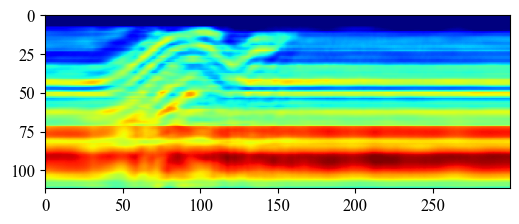

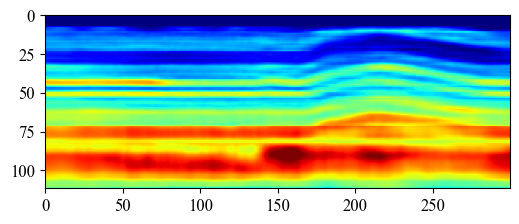

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1521 Loss:  -9.260601043701172 model_loss:  240188.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1522 Loss:  -9.275623321533203 model_loss:  240418.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1523 Loss:  -9.127367973327637 model_loss:  238519.66


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1529 Loss:  -9.316254615783691 model_loss:  236333.02


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1530 Loss:  -9.322561264038086 model_loss:  236795.3


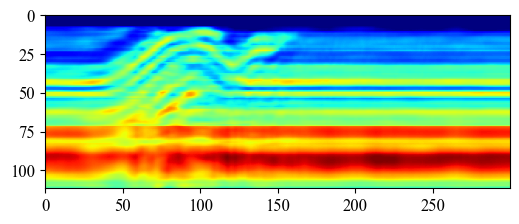

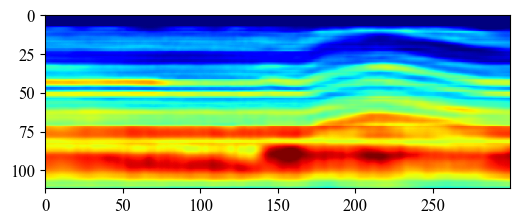

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1531 Loss:  -9.231201171875 model_loss:  235799.02


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1532 Loss:  -9.080652236938477 model_loss:  236711.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1533 Loss:  -9.196798324584961 model_loss:  234720.69


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1539 Loss:  -9.258843421936035 model_loss:  230670.47


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1540 Loss:  -9.053905487060547 model_loss:  229866.77


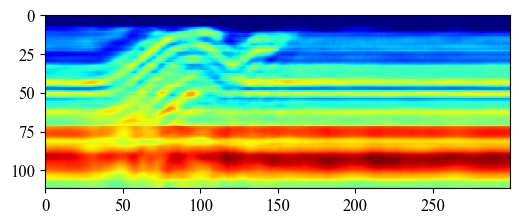

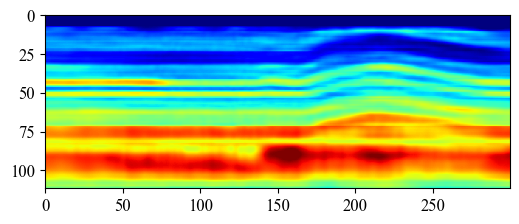

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1541 Loss:  -9.225586891174316 model_loss:  227382.67


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1542 Loss:  -9.323270797729492 model_loss:  228108.22


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1543 Loss:  -9.294988632202148 model_loss:  228393.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1549 Loss:  -9.345338821411133 model_loss:  228513.58


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1550 Loss:  -9.292792320251465 model_loss:  229346.05


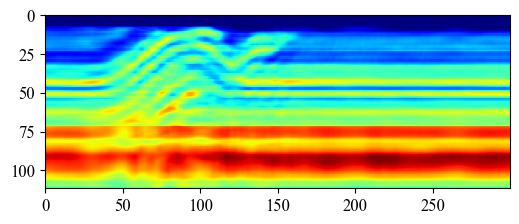

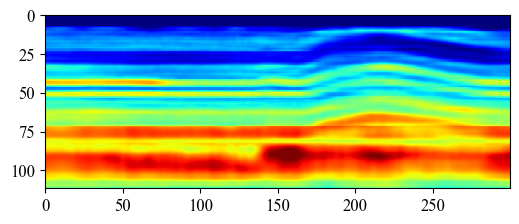

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1551 Loss:  -9.285982131958008 model_loss:  226388.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1552 Loss:  -9.26028823852539 model_loss:  226231.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1553 Loss:  -9.245959281921387 model_loss:  225168.02


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1559 Loss:  -9.379225730895996 model_loss:  221362.61


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1560 Loss:  -9.348920822143555 model_loss:  221141.1


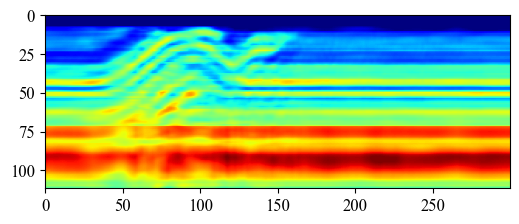

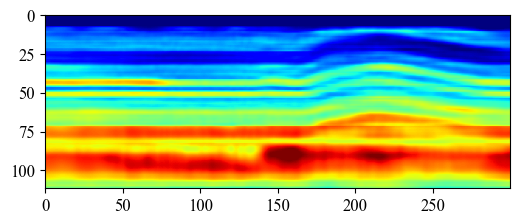

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1561 Loss:  -9.250801086425781 model_loss:  220622.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1562 Loss:  -9.1682767868042 model_loss:  218314.33


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1563 Loss:  -9.277215957641602 model_loss:  220352.58


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1569 Loss:  -9.277698516845703 model_loss:  219249.05


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1570 Loss:  -8.989008903503418 model_loss:  218122.7


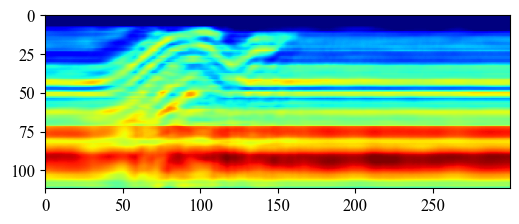

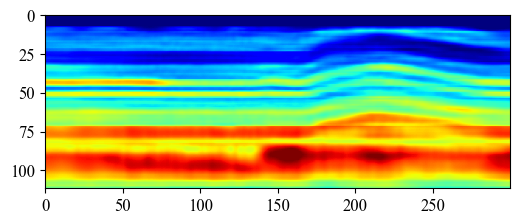

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1571 Loss:  -9.271556854248047 model_loss:  219981.11


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1572 Loss:  -9.278725624084473 model_loss:  219033.4


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1573 Loss:  -8.939979553222656 model_loss:  215520.81


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1579 Loss:  -9.202479362487793 model_loss:  213599.81


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1580 Loss:  -9.330575942993164 model_loss:  212909.14


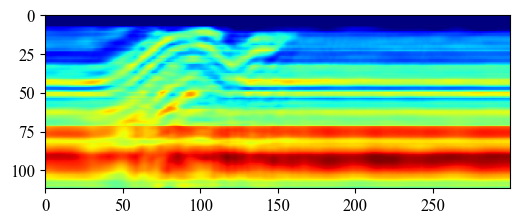

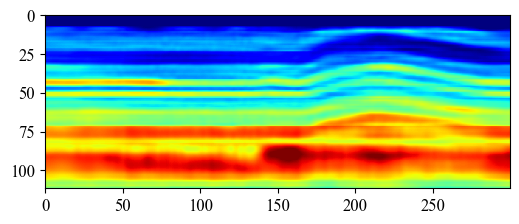

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1581 Loss:  -9.091608047485352 model_loss:  212962.14


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1582 Loss:  -9.146577835083008 model_loss:  211471.23


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1583 Loss:  -9.322746276855469 model_loss:  212253.94


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1589 Loss:  -9.184812545776367 model_loss:  211448.11


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1590 Loss:  -9.311532020568848 model_loss:  210775.73


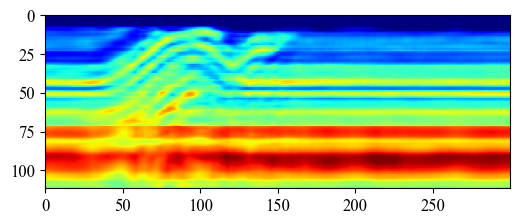

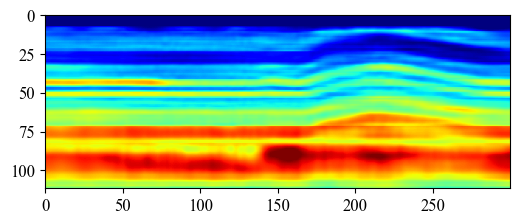

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1591 Loss:  -9.213874816894531 model_loss:  210345.45


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1592 Loss:  -9.09361457824707 model_loss:  212996.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1593 Loss:  -9.263649940490723 model_loss:  212612.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1599 Loss:  -9.120723724365234 model_loss:  213881.72


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1600 Loss:  -9.167581558227539 model_loss:  214617.2


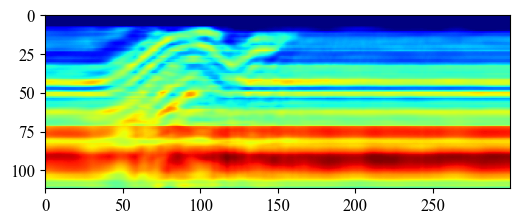

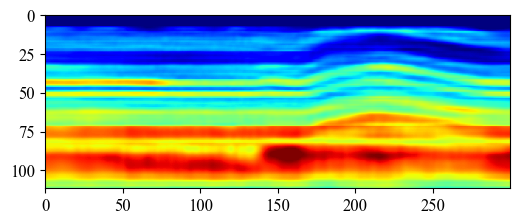

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1601 Loss:  -9.346382141113281 model_loss:  212953.33


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1602 Loss:  -9.244856834411621 model_loss:  212568.05


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1603 Loss:  -9.074973106384277 model_loss:  213305.77


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1609 Loss:  -9.341007232666016 model_loss:  208543.36


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1610 Loss:  -9.31016731262207 model_loss:  207480.47


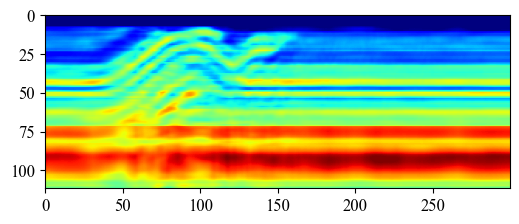

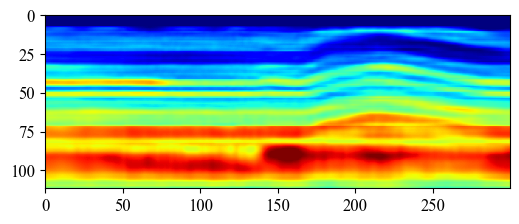

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1611 Loss:  -9.235292434692383 model_loss:  207657.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1612 Loss:  -9.225618362426758 model_loss:  205842.55


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1613 Loss:  -9.288166999816895 model_loss:  207604.75


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1619 Loss:  -9.29409122467041 model_loss:  204229.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1620 Loss:  -9.18821907043457 model_loss:  202780.9


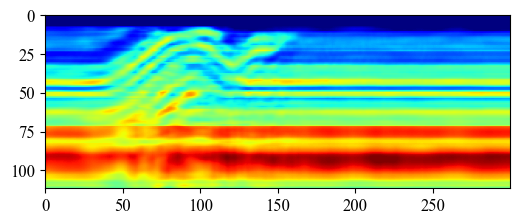

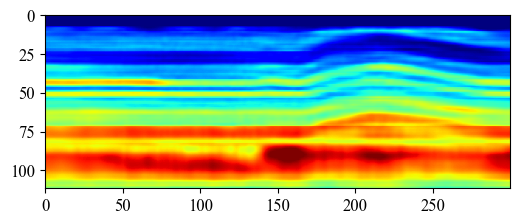

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1621 Loss:  -9.157700538635254 model_loss:  205065.89


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1622 Loss:  -9.303914070129395 model_loss:  203276.05


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1623 Loss:  -9.344249725341797 model_loss:  201783.64


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1629 Loss:  -9.303345680236816 model_loss:  198354.42


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1630 Loss:  -9.270695686340332 model_loss:  196573.9


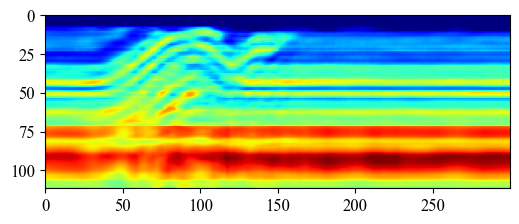

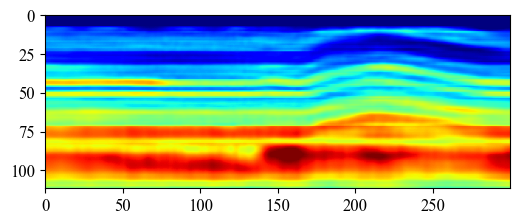

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1631 Loss:  -9.107270240783691 model_loss:  197733.73


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1632 Loss:  -9.241618156433105 model_loss:  196069.67


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1633 Loss:  -9.318729400634766 model_loss:  196044.23


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1639 Loss:  -9.288715362548828 model_loss:  194260.03


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1640 Loss:  -9.33602523803711 model_loss:  192901.28


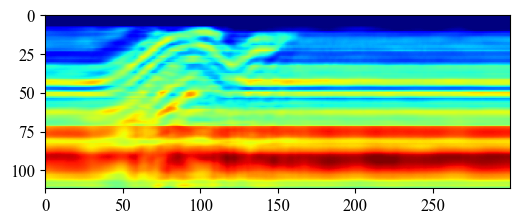

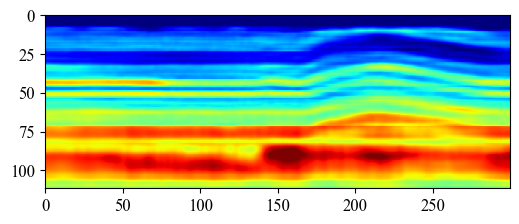

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1641 Loss:  -9.281929969787598 model_loss:  192138.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1642 Loss:  -9.3056001663208 model_loss:  190036.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1643 Loss:  -9.35348129272461 model_loss:  189886.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1649 Loss:  -9.180425643920898 model_loss:  187896.6


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1650 Loss:  -9.299005508422852 model_loss:  189426.86


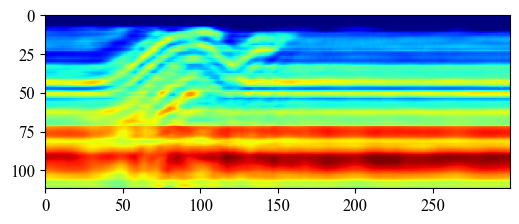

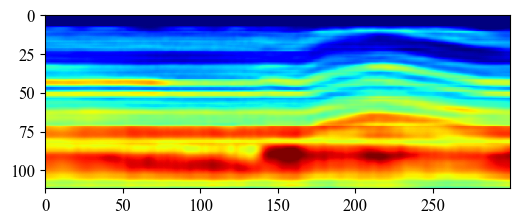

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1651 Loss:  -9.31008529663086 model_loss:  189106.36


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1652 Loss:  -9.317909240722656 model_loss:  189346.84


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1653 Loss:  -9.306340217590332 model_loss:  187279.78


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1659 Loss:  -9.203449249267578 model_loss:  180600.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1660 Loss:  -9.273963928222656 model_loss:  180829.89


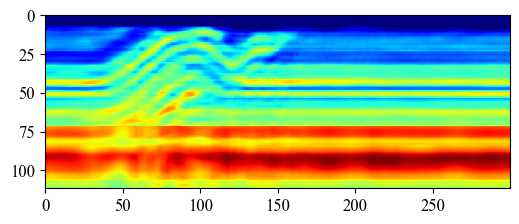

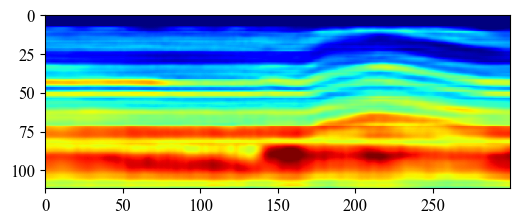

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1661 Loss:  -9.352863311767578 model_loss:  180103.62


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1662 Loss:  -9.402276039123535 model_loss:  180202.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1663 Loss:  -9.396275520324707 model_loss:  178842.83


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1669 Loss:  -9.41530990600586 model_loss:  177516.19


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1670 Loss:  -9.301434516906738 model_loss:  177151.48


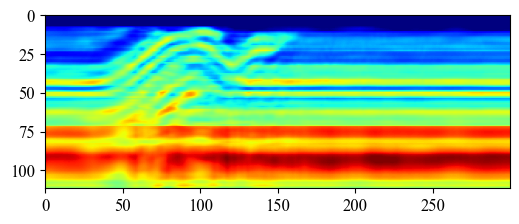

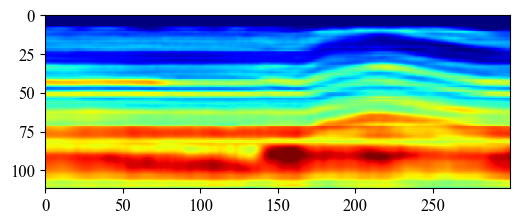

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1671 Loss:  -9.246539115905762 model_loss:  175671.52


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1672 Loss:  -9.27392578125 model_loss:  177334.36


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1673 Loss:  -9.40835189819336 model_loss:  176007.9


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1679 Loss:  -9.214727401733398 model_loss:  173647.52


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1680 Loss:  -9.178088188171387 model_loss:  174396.22


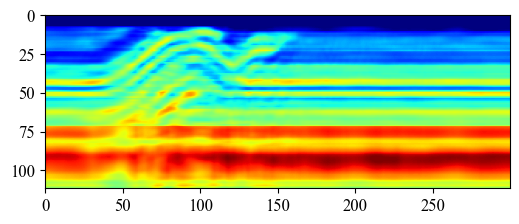

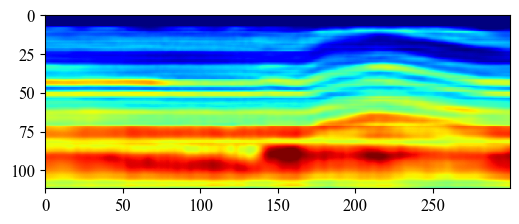

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1681 Loss:  -9.338485717773438 model_loss:  173479.95


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1682 Loss:  -9.38742446899414 model_loss:  174007.23


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1683 Loss:  -9.328516960144043 model_loss:  174863.64


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1689 Loss:  -9.377159118652344 model_loss:  172171.17


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1690 Loss:  -9.258099555969238 model_loss:  170962.61


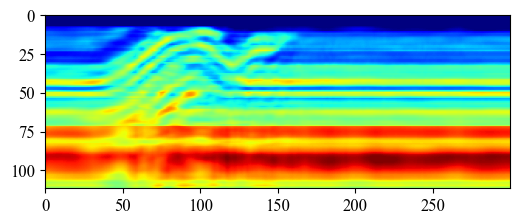

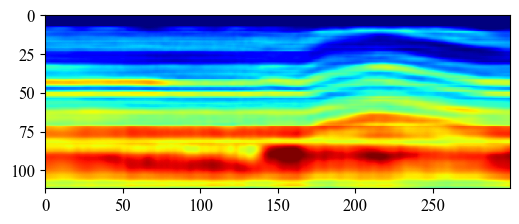

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1691 Loss:  -9.178357124328613 model_loss:  169683.34


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1692 Loss:  -9.265676498413086 model_loss:  172190.45


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1693 Loss:  -9.41137409210205 model_loss:  171289.19


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1699 Loss:  -9.39820671081543 model_loss:  170682.39


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1700 Loss:  -9.36653995513916 model_loss:  170707.39


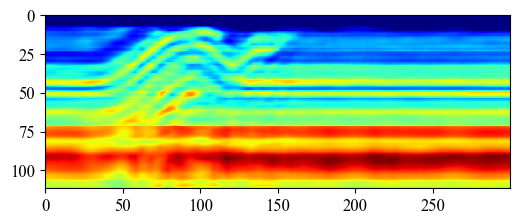

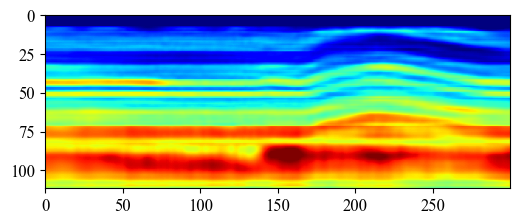

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1701 Loss:  -9.34939956665039 model_loss:  167454.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1702 Loss:  -9.24145221710205 model_loss:  167313.16


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1703 Loss:  -9.288028717041016 model_loss:  166183.86


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1709 Loss:  -9.336758613586426 model_loss:  166138.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1710 Loss:  -9.37661075592041 model_loss:  165975.81


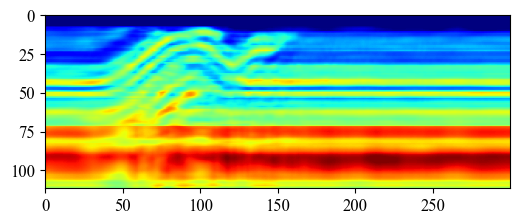

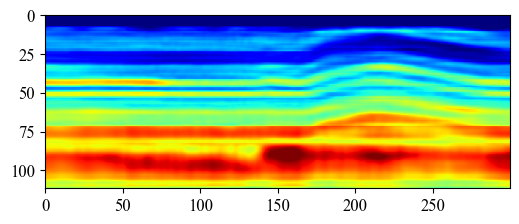

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1711 Loss:  -9.376405715942383 model_loss:  165735.92


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1712 Loss:  -9.393073081970215 model_loss:  164536.16


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1713 Loss:  -9.390810012817383 model_loss:  165730.05


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1719 Loss:  -9.158571243286133 model_loss:  158634.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1720 Loss:  -9.303153991699219 model_loss:  160264.19


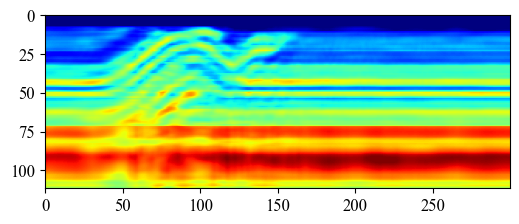

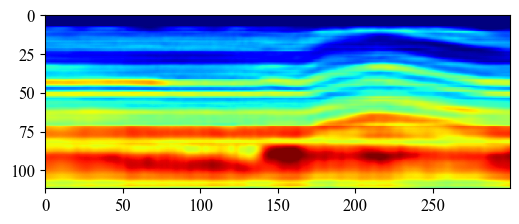

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1721 Loss:  -9.364603996276855 model_loss:  160448.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1722 Loss:  -9.387507438659668 model_loss:  159763.62


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1723 Loss:  -9.326272010803223 model_loss:  159556.97


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1729 Loss:  -9.116135597229004 model_loss:  160686.58


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1730 Loss:  -9.360443115234375 model_loss:  160183.12


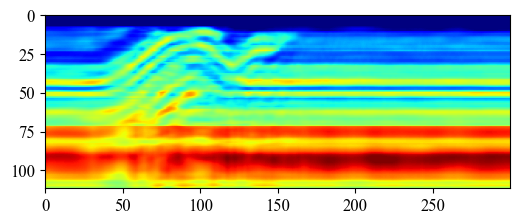

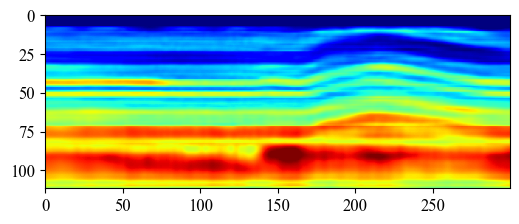

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1731 Loss:  -9.374631881713867 model_loss:  159437.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1732 Loss:  -9.327428817749023 model_loss:  159685.25


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1733 Loss:  -9.176579475402832 model_loss:  160827.98


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1739 Loss:  -9.220808029174805 model_loss:  155270.81


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1740 Loss:  -9.377017974853516 model_loss:  156174.92


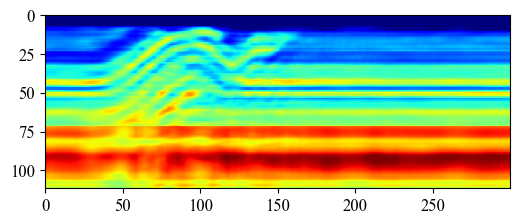

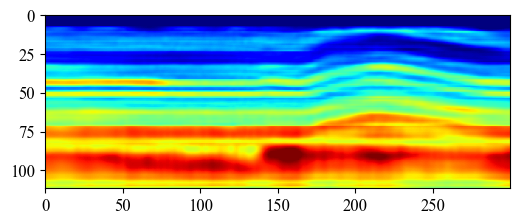

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1741 Loss:  -9.31527328491211 model_loss:  156287.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1742 Loss:  -9.125207901000977 model_loss:  153950.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1743 Loss:  -9.30138111114502 model_loss:  155446.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1749 Loss:  -9.372116088867188 model_loss:  153495.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1750 Loss:  -9.392969131469727 model_loss:  154250.69


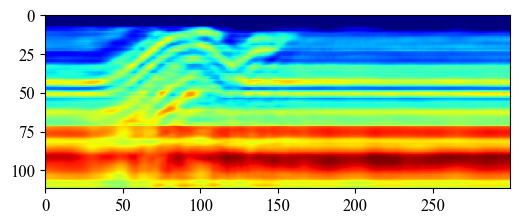

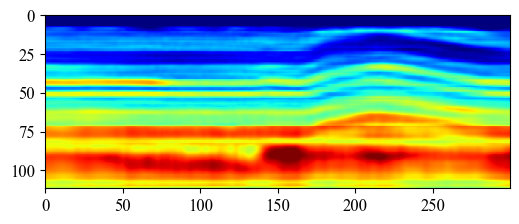

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1751 Loss:  -9.314472198486328 model_loss:  155289.33


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1752 Loss:  -9.218360900878906 model_loss:  153049.3


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1753 Loss:  -9.171184539794922 model_loss:  154786.98


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1759 Loss:  -9.175868034362793 model_loss:  144628.36


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1760 Loss:  -9.237042427062988 model_loss:  145655.73


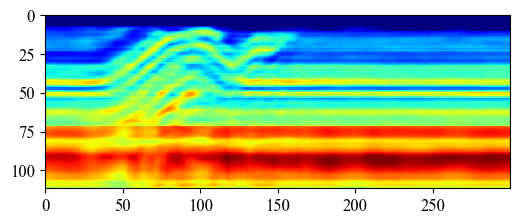

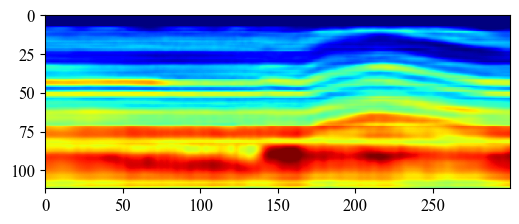

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1761 Loss:  -9.335762023925781 model_loss:  145381.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1762 Loss:  -9.361926078796387 model_loss:  146502.22


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1763 Loss:  -9.3853178024292 model_loss:  145542.8


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1769 Loss:  -9.302942276000977 model_loss:  143498.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1770 Loss:  -9.351884841918945 model_loss:  144206.66


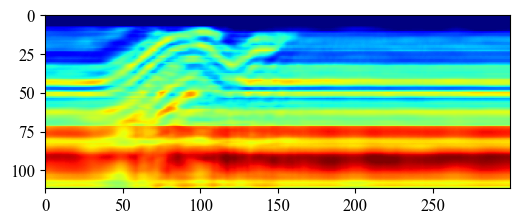

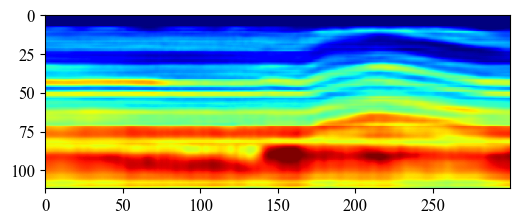

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1771 Loss:  -9.377067565917969 model_loss:  143404.55


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1772 Loss:  -9.308157920837402 model_loss:  142254.23


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1773 Loss:  -9.121745109558105 model_loss:  143996.56


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1779 Loss:  -9.333051681518555 model_loss:  142912.19


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1780 Loss:  -9.176061630249023 model_loss:  141686.75


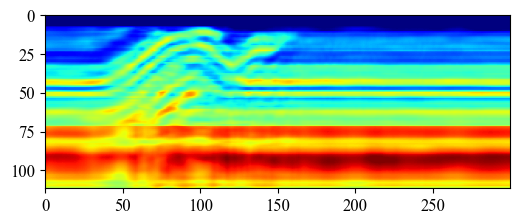

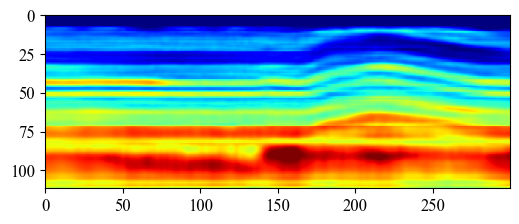

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1781 Loss:  -9.201284408569336 model_loss:  143862.02


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1782 Loss:  -9.352376937866211 model_loss:  141478.95


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1783 Loss:  -9.388381958007812 model_loss:  141746.23


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1789 Loss:  -9.394606590270996 model_loss:  141149.98


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1790 Loss:  -9.262680053710938 model_loss:  140865.25


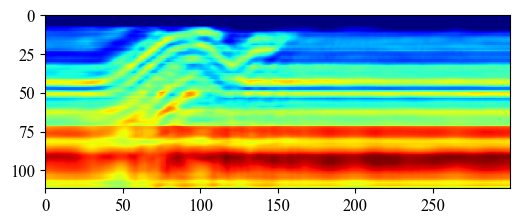

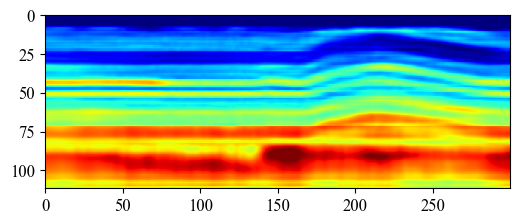

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1791 Loss:  -9.078391075134277 model_loss:  142901.14


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1792 Loss:  -9.2789306640625 model_loss:  140374.28


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1793 Loss:  -9.302166938781738 model_loss:  138010.5


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1799 Loss:  -9.246024131774902 model_loss:  137708.06


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1800 Loss:  -8.932840347290039 model_loss:  139680.25


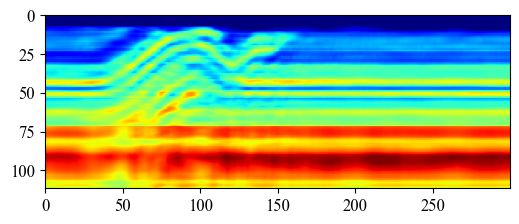

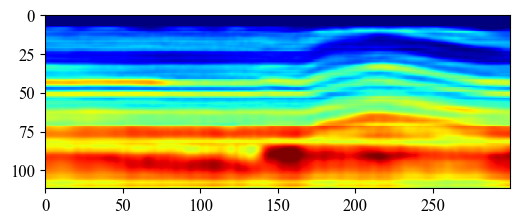

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1801 Loss:  -9.190099716186523 model_loss:  137379.78


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1802 Loss:  -9.065616607666016 model_loss:  135961.73


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1803 Loss:  -9.000802993774414 model_loss:  138670.64


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1809 Loss:  -9.12413501739502 model_loss:  138282.58


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1810 Loss:  -9.15680980682373 model_loss:  139311.39


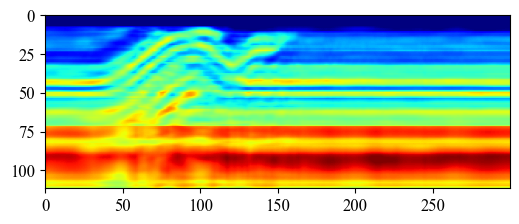

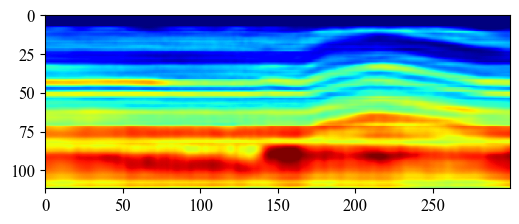

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1811 Loss:  -9.008902549743652 model_loss:  136496.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1812 Loss:  -9.169478416442871 model_loss:  137283.17


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1813 Loss:  -9.083248138427734 model_loss:  138424.77


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1819 Loss:  -8.983724594116211 model_loss:  142019.55


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1820 Loss:  -9.076537132263184 model_loss:  139792.94


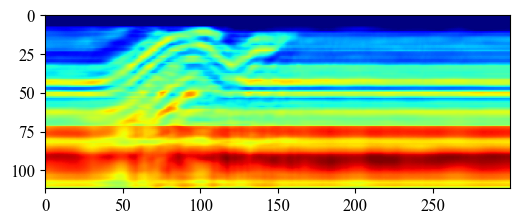

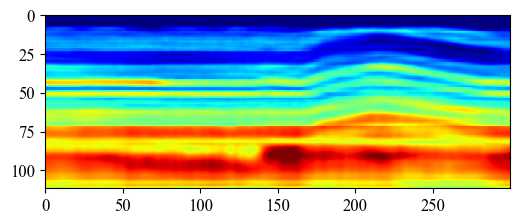

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1821 Loss:  -9.09560775756836 model_loss:  137189.27


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1822 Loss:  -8.916190147399902 model_loss:  138787.53


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1823 Loss:  -8.973821640014648 model_loss:  138239.2


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1829 Loss:  -8.989234924316406 model_loss:  141540.64


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1830 Loss:  -8.943541526794434 model_loss:  139321.05


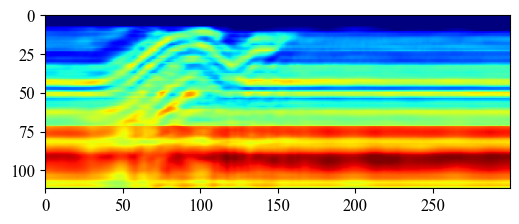

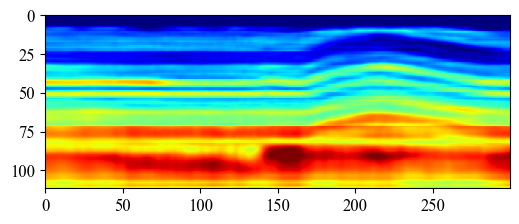

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1831 Loss:  -9.263175964355469 model_loss:  142597.88


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1832 Loss:  -9.077030181884766 model_loss:  144914.55


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1833 Loss:  -8.923078536987305 model_loss:  143493.14


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1839 Loss:  -9.061637878417969 model_loss:  143846.05


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1840 Loss:  -9.190132141113281 model_loss:  143725.47


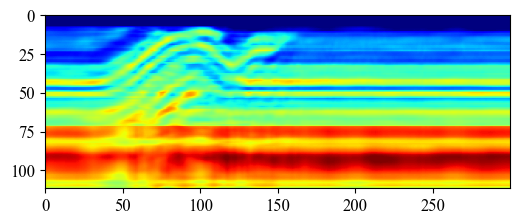

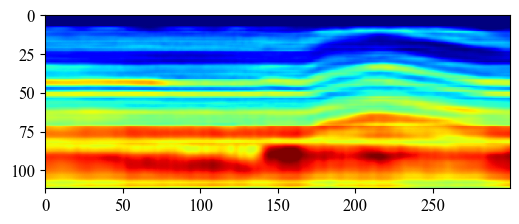

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1841 Loss:  -9.007580757141113 model_loss:  147470.14


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1842 Loss:  -9.03053092956543 model_loss:  147248.8


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1843 Loss:  -9.251266479492188 model_loss:  146065.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1849 Loss:  -9.172246932983398 model_loss:  145085.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1850 Loss:  -8.993901252746582 model_loss:  145595.97


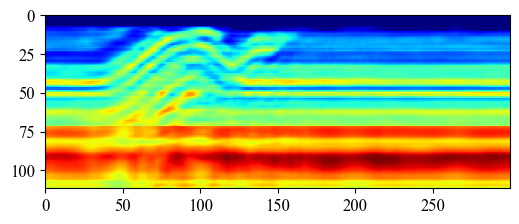

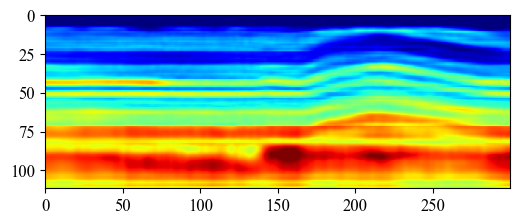

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1851 Loss:  -9.148924827575684 model_loss:  143523.83


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1852 Loss:  -9.064661026000977 model_loss:  142821.83


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1853 Loss:  -8.936359405517578 model_loss:  146459.0


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1859 Loss:  -8.854628562927246 model_loss:  149318.81


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1860 Loss:  -9.228828430175781 model_loss:  149563.23


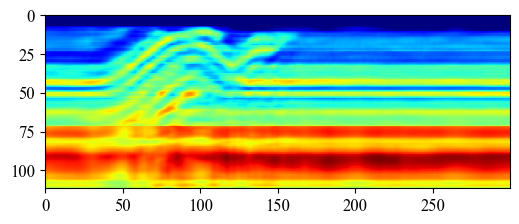

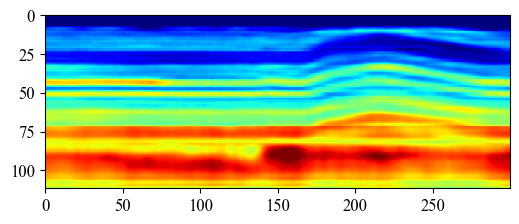

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1861 Loss:  -8.945387840270996 model_loss:  147365.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1862 Loss:  -9.061702728271484 model_loss:  149510.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1863 Loss:  -9.122506141662598 model_loss:  149135.78


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1869 Loss:  -9.33977222442627 model_loss:  150457.66


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1870 Loss:  -9.233991622924805 model_loss:  150095.06


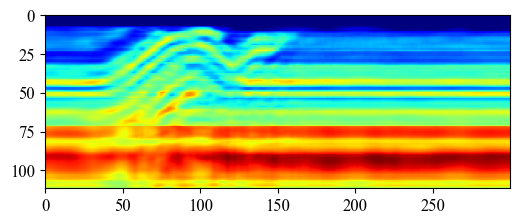

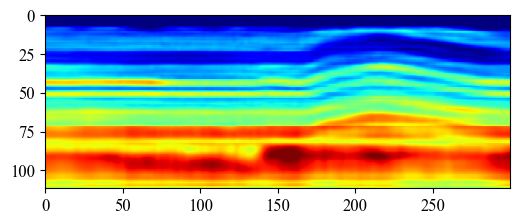

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1871 Loss:  -9.126381874084473 model_loss:  152250.48


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1872 Loss:  -9.193997383117676 model_loss:  150391.83


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1873 Loss:  -9.269596099853516 model_loss:  150844.98


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1879 Loss:  -9.121838569641113 model_loss:  150601.33


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1880 Loss:  -9.22925090789795 model_loss:  147934.0


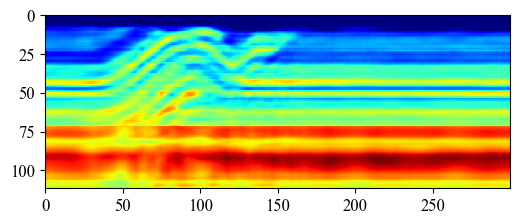

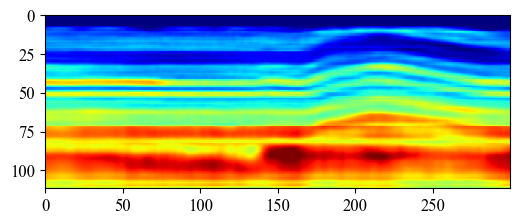

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1881 Loss:  -9.36689567565918 model_loss:  148705.75


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1882 Loss:  -9.272841453552246 model_loss:  150181.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1883 Loss:  -9.131155967712402 model_loss:  147945.44


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1889 Loss:  -9.219654083251953 model_loss:  147811.2


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1890 Loss:  -9.3273344039917 model_loss:  148346.8


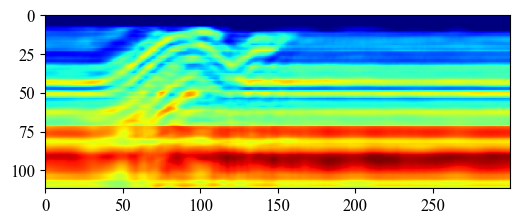

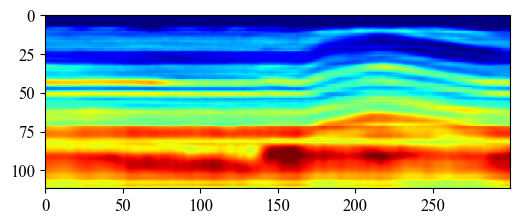

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1891 Loss:  -9.063499450683594 model_loss:  149265.81


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1892 Loss:  -9.255880355834961 model_loss:  146302.0


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1893 Loss:  -9.326762199401855 model_loss:  146394.69


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1899 Loss:  -9.319398880004883 model_loss:  149266.81


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1900 Loss:  -9.345091819763184 model_loss:  146657.28


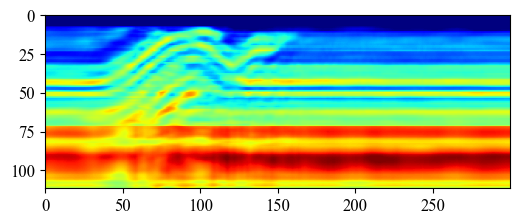

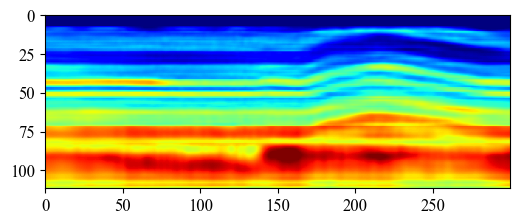

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1901 Loss:  -9.336772918701172 model_loss:  146880.27


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1902 Loss:  -9.34701156616211 model_loss:  148511.97


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1903 Loss:  -9.349220275878906 model_loss:  147641.72


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1909 Loss:  -9.319647789001465 model_loss:  147084.7


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1910 Loss:  -9.35590934753418 model_loss:  146076.58


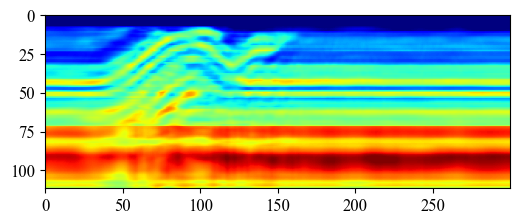

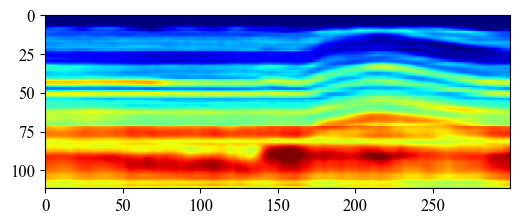

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1911 Loss:  -9.368735313415527 model_loss:  142447.56


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1912 Loss:  -9.306098937988281 model_loss:  141648.02


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1913 Loss:  -9.240628242492676 model_loss:  139983.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1919 Loss:  -9.403017044067383 model_loss:  137362.17


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1920 Loss:  -9.404848098754883 model_loss:  137555.44


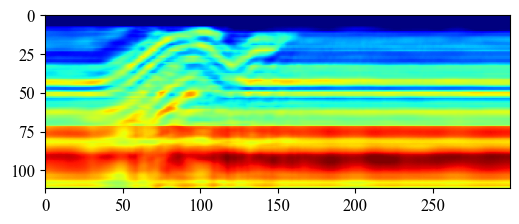

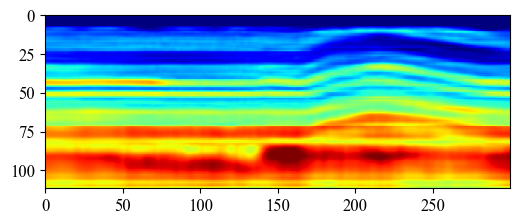

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1921 Loss:  -9.379152297973633 model_loss:  138086.14


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1922 Loss:  -9.402872085571289 model_loss:  137551.1


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1923 Loss:  -9.366081237792969 model_loss:  136205.81


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1929 Loss:  -9.278460502624512 model_loss:  133298.77


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1930 Loss:  -9.25793743133545 model_loss:  134197.03


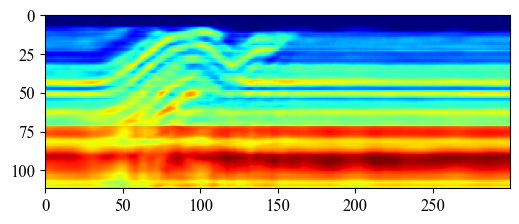

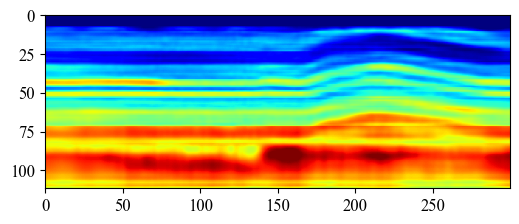

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1931 Loss:  -9.38350772857666 model_loss:  132783.9


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1932 Loss:  -9.405388832092285 model_loss:  132606.98


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1933 Loss:  -9.365915298461914 model_loss:  132209.23


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1939 Loss:  -9.376266479492188 model_loss:  129441.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1940 Loss:  -9.259063720703125 model_loss:  129729.48


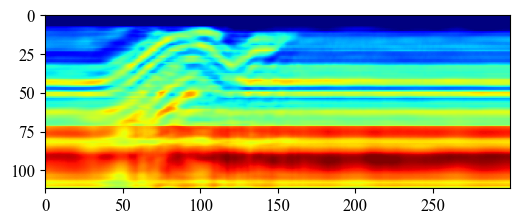

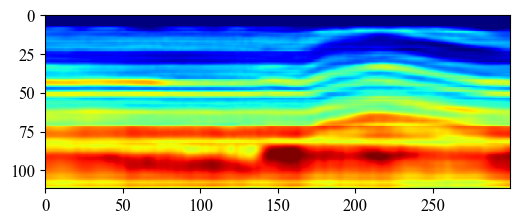

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1941 Loss:  -9.274917602539062 model_loss:  128370.01


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1942 Loss:  -9.387956619262695 model_loss:  130711.59


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1943 Loss:  -9.425418853759766 model_loss:  130486.36


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1949 Loss:  -9.436287879943848 model_loss:  127708.836


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1950 Loss:  -9.443774223327637 model_loss:  126213.586


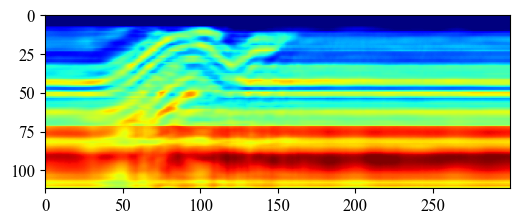

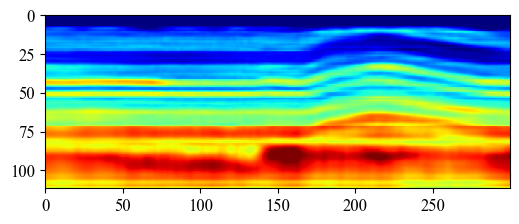

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1951 Loss:  -9.412933349609375 model_loss:  126179.63


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1952 Loss:  -9.357179641723633 model_loss:  125828.08


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1953 Loss:  -9.336830139160156 model_loss:  127183.1


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1959 Loss:  -9.427648544311523 model_loss:  122477.58


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1960 Loss:  -9.419185638427734 model_loss:  123343.46


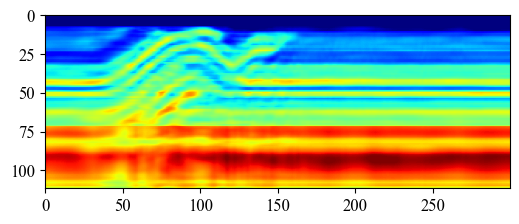

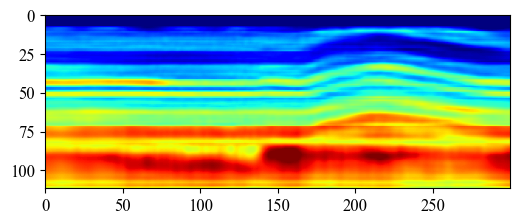

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1961 Loss:  -9.414152145385742 model_loss:  122743.48


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1962 Loss:  -9.345067977905273 model_loss:  122754.65


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1963 Loss:  -9.286857604980469 model_loss:  120055.305


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1969 Loss:  -9.403620719909668 model_loss:  116268.04


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1970 Loss:  -9.41567325592041 model_loss:  116136.24


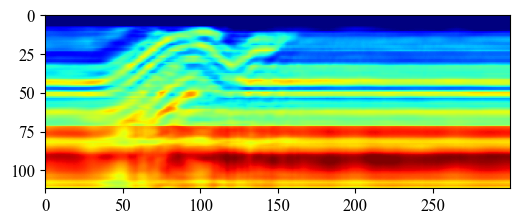

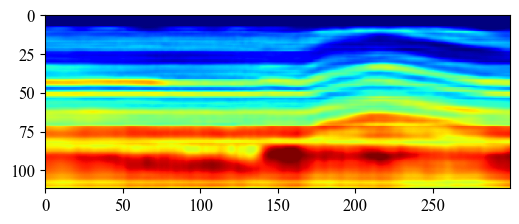

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1971 Loss:  -9.404234886169434 model_loss:  115744.82


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1972 Loss:  -9.39783000946045 model_loss:  116512.5


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1973 Loss:  -9.380249977111816 model_loss:  114950.375


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1979 Loss:  -9.423914909362793 model_loss:  115438.91


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]

Epoch: 1980 Loss:  -9.402524948120117 model_loss:  114640.266


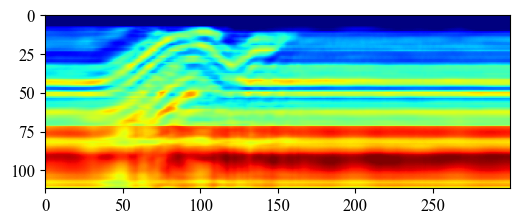

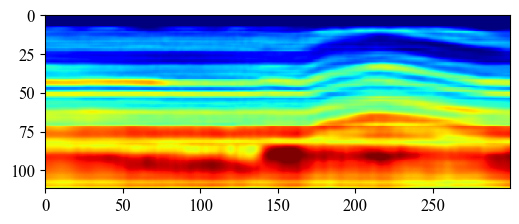

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1981 Loss:  -9.280248641967773 model_loss:  115983.33


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1982 Loss:  -9.309579849243164 model_loss:  114429.86


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1983 Loss:  -9.341753959655762 model_loss:  115617.24


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1989 Loss:  -9.346797943115234 model_loss:  113025.74


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 1990 Loss:  -9.445411682128906 model_loss:  112654.32


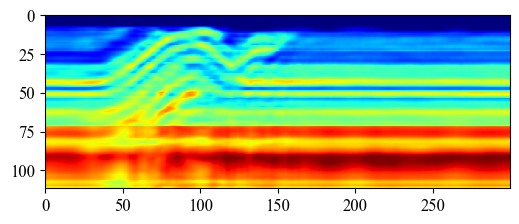

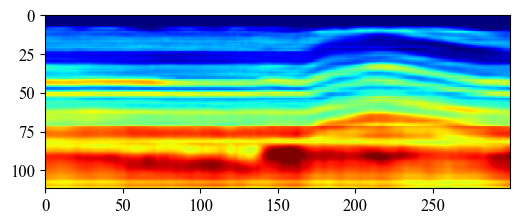

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1991 Loss:  -9.384576797485352 model_loss:  111945.555


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.88s/it]


Epoch: 1992 Loss:  -9.367229461669922 model_loss:  111001.55


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1993 Loss:  -9.277463912963867 model_loss:  112659.47


... (10 outputs left out)

100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]


Epoch: 1999 Loss:  -9.329815864562988 model_loss:  108245.05


100%|██████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.87s/it]

Epoch: 2000 Loss:  -9.288875579833984 model_loss:  110079.36


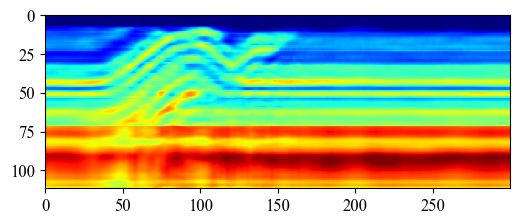

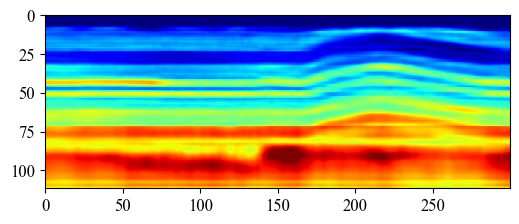

Runtime (mins): 198.12972332636517


In [30]:
t_start = time.time()
num_batches = 1
n_epochs = 2001

data_loss = []

for epoch in range(n_epochs):
    def closure(v, dz, dy, dx, dt, source_amplitudes_true, source_locations, receiver_locations, observed_data, freq, pml_width):
        observed_data = deepwave3D.common.upsample(observed_data, step_ratio)
        observed_data = filt(taper(observed_data))
        
        n_shots = source_amplitudes_true.size(0)
        wavefield_size = [n_shots, nz + 2 * pml_width, ny + 2 * pml_width,
                          nx + 2 * pml_width]
        wavefield_0 = torch.zeros(*wavefield_size, device=device)
        wavefield_m1 = torch.zeros(*wavefield_size, device=device)
        psiz_m1 = torch.zeros(*wavefield_size, device=device)
        psiy_m1 = torch.zeros(*wavefield_size, device=device)
        psix_m1 = torch.zeros(*wavefield_size, device=device)
        zetaz_m1 = torch.zeros(*wavefield_size, device=device)
        zetay_m1 = torch.zeros(*wavefield_size, device=device)
        zetax_m1 = torch.zeros(*wavefield_size, device=device)

        predicted_data = torch.zeros(n_shots,
                                          n_receivers_per_shot, nt,
                                          device=device)
        k = 0
        n_segments = 10
        for i, chunk in enumerate(torch.chunk(source_amplitudes_true,
                                              n_segments,
                                              dim=-1)):
            if i == n_segments - 1:
                (wavefield_0, wavefield_m1, psiz_m1, psiy_m1, psix_m1,
                 zetaz_m1, zetay_m1, zetax_m1, receiver_amplitudes_chunk) = \
                    wrap(v, dz, dy, dx, dt, chunk, source_locations, receiver_locations, 
                         freq, pml_width,
                         wavefield_0,
                         wavefield_m1,
                         psiz_m1, psiy_m1, psix_m1,
                         zetaz_m1, zetay_m1, zetax_m1)
            else:
                (wavefield_0, wavefield_m1, psiz_m1, psiy_m1, psix_m1,
                 zetaz_m1, zetay_m1, zetax_m1, receiver_amplitudes_chunk) = \
                 torch.utils.checkpoint.checkpoint(wrap, v, 
                                                   dz, dy, dx, dt,
                                                   chunk,
                                                   source_locations, receiver_locations, 
                                                   freq, pml_width,
                                                   wavefield_0,
                                                   wavefield_m1,
                                                   psiz_m1, psiy_m1, psix_m1,
                                                   zetaz_m1, zetay_m1, zetax_m1)
            predicted_data[..., k:k+chunk.shape[-1]] = \
                receiver_amplitudes_chunk
            k += chunk.shape[-1]
        predicted_data = filt(taper(predicted_data))


        loss = criterion_data.forward(predicted_data.reshape(1,n_receivers_per_shot_x,n_receivers_per_shot_y,nt),observed_data.reshape(1,n_receivers_per_shot_x,n_receivers_per_shot_y,nt))
        loss.backward()
        return loss



    epoch_loss = 0.0
    for it in trange(num_batches):
        optimizer.zero_grad()

         # ifwi
        # model = imvel(coords.contiguous())
        


        # ifwi_tt
        model = imvel(zcoords.contiguous(), ycoords.contiguous(), xcoords.contiguous())
        std_vp = 3e3
        mean_vp = 2.45e3
        model = model * std_vp + model_init.to(device)   #mean_vp #+model_init.to(device)  
        model = torch.where(mask == 1, model, model_init.to(device))
        model.data.clamp_(2.5e3, 6e3)


        mask_source = (torch.rand(n_shots) < 0.5).float() 
        weights = torch.randint(0, 2, (n_shots,)) * 2 - 1   # {+1, -1}
        weights = weights * mask_source
        weights = weights.view(n_shots, 1, 1).to(source_amplitudes_true.device)
        batch_src_amps_true = (weights * source_amplitudes_true).permute(1, 0, 2)
        batch_rcv_amps_true = torch.sum(weights * observed_data, dim=0, keepdim=True) .to(device)
        batch_x_s = source_locations.permute(1, 0, 2).to(device)
        batch_x_r = receiver_locations[0:1].to(device)

        loss = closure(model, 
               dz, dy, dx, dt, 
               batch_src_amps_true,
               batch_x_s,
               batch_x_r, 
               batch_rcv_amps_true, 
               freq,
               20)          
        optimizer.step()
        with torch.no_grad():
            model.clamp_(min=2.45e3, max=6e3)
        epoch_loss += loss.item()


    scheduler.step()

    
    data_loss.append(epoch_loss)
    v_loss = loss_fn(model.cpu(),model_true.cpu()).detach().numpy()
    print('Epoch:', epoch, 'Loss: ', epoch_loss,'model_loss: ', v_loss)

    if epoch % 10 == 0:

        plt.figure(figsize=(6, 4))
        plt.imshow(model[:,0,:].cpu().detach().numpy(), vmin=2.5e3, vmax=6.0e3,
                   cmap='jet')
        plt.show()

        plt.figure(figsize=(6, 4))
        plt.imshow(model[:,:,30].cpu().detach().numpy(), vmin=2.5e3, vmax=6.0e3,
                   cmap='jet')
        plt.show()

t_end = time.time()
print('Runtime (mins):', (t_end - t_start)/60)